# PCLab#5 - Group 4 - Claas Boumans Giuliano Ciaramella Theodor Nissen-Meyer

**20598 – Finance with Big Data, PC Lab #5: Hackathon, NGO Press Campaigns and Responsible Investment**

*Time required: approximately >18 hours (mostly due to extra work, beyond the required scope). Difficulty: 8 out of 10.*

**Tasks we chose.** Day 1 (NGO data), Day 2 (stock data), Task #4 (betas), Task #5 (abnormal returns) and Task #6 (do campaigns matter?). We did not do Tasks #1, #2, #3 and #7.

In the charts, bad news means negative events, good news positive events, and points are percentage points.

## 0. Setup
Libraries, the chart theme and the shared helpers (`show`, `vertical_grid`, `annotate` from PC Lab #4, `ols` from PC Lab #3, first built in PC Lab #2). Data files are read from this folder. The Fama French factors are downloaded, so a run needs internet.

In [1]:
import glob
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter, PercentFormatter
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.regression.rolling import RollingOLS

pd.set_option("display.float_format", "{:,.4f}".format)
warnings.filterwarnings("ignore", category=FutureWarning)  # pandas' notice on stack()

SEED = 42
Z_95 = 1.96  # half width of a 95% interval, in standard errors
ALPHA = 0.05  # significance level of our tests

In [2]:
# Chart theme inspired by The Economist
ECONOMIST_RED = "#E3120B"
BLUE, CYAN, TEAL, YELLOW = "#006BA2", "#3EBCD2", "#379A8B", "#EBB434"
PURPLE, LIGHT_RED = "#9A607F", "#DB444B"
DARK, GREY, LIGHT_GREY = "#333333", "#758D99", "#C9D3D9"
ECONOMIST_COLORS = [BLUE, CYAN, TEAL, YELLOW, "#B4BA39", PURPLE, "#D1B07C", GREY, LIGHT_RED]
ECONOMIST_BLUES = LinearSegmentedColormap.from_list("economist_blues", ["#C5E4F0", "#3EBCD2", "#006BA2", "#0C2A4A"])
GRID = "#D0D0D0"

plt.rcParams.update({
    "figure.figsize": (10.5, 4.5),
    "figure.dpi": 120,
    "font.size": 11,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.prop_cycle": plt.cycler(color=ECONOMIST_COLORS),
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": GRID,
    "axes.axisbelow": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.titlelocation": "left",
    "axes.titleweight": "bold",
    "axes.titlesize": 14,
    "axes.labelcolor": DARK,
    "xtick.color": DARK,
    "ytick.color": DARK,
    "ytick.left": False,
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "legend.frameon": False,
    "lines.linewidth": 1.6,
})

WHITE_BOX = {"facecolor": "white", "edgecolor": "none", "pad": 0.5}  # behind a label that crosses a line


def show(title=None):
    '''Add the headline, the red rule and the tag on top of the current figure, then display it.'''
    fig = plt.gcf()
    if title:
        fig.suptitle(title, x=0.01, ha="left", fontsize=14, fontweight="bold")
    fig.tight_layout()
    fig.add_artist(plt.Line2D([0, 1], [1.02, 1.02], transform=fig.transFigure, color=ECONOMIST_RED, lw=1.5))
    fig.add_artist(plt.Rectangle((0, 1.02), 0.035, 0.015, transform=fig.transFigure, color=ECONOMIST_RED,
                                 clip_on=False))
    plt.show()


def vertical_grid(ax):
    '''Vertical gridlines only, for charts read along the x-axis.'''
    ax.grid(False, axis="y")
    ax.grid(True, axis="x", color=GRID)


def minus(text):
    '''Write a true minus sign in front of numbers.'''
    return re.sub(r"(?<![\w.])-(?=[\d.])", "−", text)


POINTS = FuncFormatter(lambda value, _: minus(f"{value * 100:.1f}"))  # axis in percentage points


def interval_dots(ax, values, positions, widths, color):
    '''Draw dots with 95% intervals: filled if the interval excludes zero, hollow if it covers zero.'''
    values, positions, widths = (np.asarray(array, dtype=float) for array in (values, positions, widths))
    excludes_zero = np.abs(values) > widths
    ax.errorbar(values, positions, xerr=widths, fmt="none", ecolor=color, capsize=3, zorder=2)
    ax.scatter(values[excludes_zero], positions[excludes_zero], s=60, color=color, zorder=3)
    ax.scatter(values[~excludes_zero], positions[~excludes_zero], s=60, facecolor=ax.get_facecolor(),
               edgecolor=color, linewidth=1.6, zorder=3)


def annotate(ax, text, xy, offset=(9, 0), **kwargs):
    '''
    Write a text next to a point, shifted by `offset` in points: right of it for a positive horizontal shift,
    left for a negative one, centred for none.
    '''
    dx = offset[0]
    style = {"ha": "left" if dx > 0 else "right" if dx < 0 else "center", "va": "center", "fontsize": 10.5,
             "color": DARK}
    ax.annotate(minus(text), xy, xytext=offset, textcoords="offset points", **{**style, **kwargs})


def ols(y, x, hac_lags=0, clusters=None):
    '''
    OLS of y on a constant and x (as in PC Lab #2), with Newey-West errors for hac_lags > 0
    or errors clustered by `clusters`.
    '''
    model = sm.OLS(np.asarray(y, dtype=float), sm.add_constant(np.asarray(x, dtype=float)))
    if clusters is not None:
        return model.fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(clusters)[0]})
    if hac_lags:
        return model.fit(cov_type="HAC", cov_kwds={"maxlags": hac_lags})
    return model.fit()

## Day 1 – Explore the NGO data
Day 1 turns the Sigwatch reports of 2010 to 2018 into **one row per bank and day**, an event: bank, date, NGO, sentiment (tone towards the bank), prominence (where the report names it), NGO power (geographic reach of the NGO) and issue. Task #5 merges this table with the prices, so every cleaning step decides which events we can test.

### D1.1 Import the data and sanity check
Sigwatch delivers one Stata file per year. One row is one firm named in one NGO action, so a report naming three firms gives three rows, and one row can carry up to five NGOs (Koenig, 2017).

In [3]:
SIGWATCH_FILES = "sigwatch_data/*_data_sigwatch.dta"  # one file per year

raw = pd.concat(map(pd.read_stata, sorted(glob.glob(SIGWATCH_FILES))),
                ignore_index=True)

# Names such as "Van Lanschot " end in a space
text_columns = raw.select_dtypes(["object", "string"]).columns
raw[text_columns] = raw[text_columns].apply(lambda text: text.str.strip())
raw = raw.replace("", np.nan)  # Stata stores missing text as an empty string
raw["date"] = pd.to_datetime(raw["date"])
row_year = raw["date"].dt.year

print(f"Rows: {len(raw):,}, columns: {raw.shape[1]}")
print(f"From {raw['date'].min():%d %b %Y} to {raw['date'].max():%d %b %Y}")
print(raw.groupby(row_year).size().to_string())

text_columns = raw.select_dtypes(["object", "string"]).columns
raw[text_columns] = raw[text_columns].apply(lambda text: text.str.strip())
# Stata stores missing text as an empty string
raw = raw.replace("", np.nan)
raw["date"] = pd.to_datetime(raw["date"])
row_year = raw["date"].dt.year

print(f"Rows: {len(raw):,}, columns: {raw.shape[1]}")
print(f"From {raw['date'].min():%d %b %Y} to {raw['date'].max():%d %b %Y}")
print(raw.groupby(row_year).size().to_string())

Rows: 73,094, columns: 94
From 04 Jan 2010 to 19 Dec 2018
date
2010     3439
2011     6030
2012     7366
2013     8488
2014     8761
2015     8547
2016     8582
2017     9307
2018    12574


Rows: 73,094, columns: 94
From 04 Jan 2010 to 19 Dec 2018
date
2010     3439
2011     6030
2012     7366
2013     8488
2014     8761
2015     8547
2016     8582
2017     9307
2018    12574


**Sanity check.** Koenig (2017) and the do file of the course (the Stata cleaning script that comes with the data) warn of several traps, which we count first: duplicates and the US label, NGO names and power, undefined prominence and missing parents.

In [4]:
print("Exact duplicate rows:", raw.duplicated().sum())

us_rows = raw[raw["company_parent_country"].isin(["US", "USA"])]
print(pd.crosstab(us_rows["company_parent_country"], us_rows["date"].dt.year))

spellings = raw.groupby("ngo_code1")["ngo_name1"].nunique()
power_values = raw.groupby("ngo_code1")["ngo_power1"].nunique()
# Two values in one year would be noise, across years a re-rating
yearly_values = raw.groupby(["ngo_code1", row_year])["ngo_power1"].nunique()
print(f"NGO codes with two spellings: {(spellings > 1).sum()} of {len(spellings):,}")
print(f"NGOs whose power changes: {(power_values > 1).sum()} of {len(power_values):,}")
print(f"NGO years with two powers: {(yearly_values > 1).sum()} of {len(yearly_values):,}")

is_subsidiary = raw["company_type"] == "Subsidiary"
no_parent = raw.loc[is_subsidiary, "company_parent"].isna()
# Prominence runs from 1 to 4, so 0 has no defined meaning
print("Rows with prominence 0:", (raw["prominence"] == 0).sum())
print(f"Subsidiaries without parent: {no_parent.sum()} of {len(no_parent):,}")

Exact duplicate rows: 0
date                    2010  2011  2012  2013  2014  2015  2016  2017  2018
company_parent_country                                                      
US                      1136  1969  2611  2675  2952  2991     0     0     0
USA                        0     0     0     0     0     0  2929  3235  4321


NGO codes with two spellings: 78 of 3,010
NGOs whose power changes: 205 of 3,010
NGO years with two powers: 0 of 7,236
Rows with prominence 0: 44
Subsidiaries without parent: 24 of 10,018


**Comments – D1.1**
* **The files append cleanly:** 73,094 rows, 94 columns, no exact duplicates. "US" and "USA" are merged, and NGOs are counted by code, as 78 of 3,010 codes have two spellings. Only 24 of 10,018 subsidiary rows have no parent, so D1.2 can rely on parents.
* **Each NGO keeps its most frequent power:** 205 NGOs change value between years, never within one, so Sigwatch re-rates them, which could mix with the split around COP21 (the Paris climate conference of December 2015).

### D1.2 Keep the bank campaigns
Sigwatch's Finance sector also holds insurers, pension funds and development banks, so we select by name: a firm stays only if it is a bank with a Datastream price series.
* **Own name first.** A firm with its own price series stays itself. Natixis and CaixaBank are subsidiaries of unlisted groups, whose parents have no prices.
* **Otherwise the parent:** Santander UK is Grupo Santander, NatWest is RBS, Halifax is Lloyds.
* **Country is the parent's country:** euro area, Sweden, UK and US, without Norway and Switzerland.
* **One exception:** Smithfield Foods and Shuanghui, recorded under Goldman Sachs, are pig welfare campaigns against a food firm, so we drop them. Owned firms where the bank is a fair target stay, such as Third Energy (fracking) under Barclays.

The name dictionary, `bank_names.csv`, starts from the do file (`example_name_cleaning.txt`), without its wrong renames (Pinnacle West, Berkshire Hathaway, Lloyd's of London, Generali, Virgin Group, ACE, Allianz).

In [5]:
# Sigwatch name in lower case, Datastream column, and where each pair comes from
BANK_NAMES = pd.read_csv("bank_names.csv", index_col="sigwatch_name")["datastream_column"].to_dict()

In [6]:
# Euro area countries in Datastream, then Sweden, the UK and the US
COUNTRIES = [
    "Austria", "Belgium", "Cyprus", "Estonia", "Finland", "France", "Germany",
    "Greece", "Ireland", "Italy", "Lithuania", "Malta", "Netherlands",
    "Portugal", "Slovakia", "Slovenia", "Spain", "Sweden", "UK", "US",
]

# Recorded under Goldman Sachs, but the campaigns are about food firms
FOOD_FIRMS = ["Smithfield Foods", "Shuanghui International Holdings"]


def match_banks(raw):
    '''Keep the rows on our banks, matched by own name, else by parent.'''
    own_name = raw["company"].str.lower()
    parent_name = raw["company_parent"].str.lower()
    is_subsidiary = raw["company_type"] == "Subsidiary"

    # Own name first: a parent counts only for a subsidiary
    own_bank = own_name.map(BANK_NAMES)
    parent_bank = parent_name.map(BANK_NAMES).where(is_subsidiary)

    rows = raw.copy()
    rows["bank"] = own_bank.fillna(parent_bank)
    rows["through_parent"] = own_bank.isna()
    rows["country"] = raw["company_parent_country"].replace("USA", "US")

    has_bank = rows["bank"].notna()
    in_country = rows["country"].isin(COUNTRIES)
    is_food_firm = rows["company"].isin(FOOD_FIRMS)
    return rows[has_bank & in_country & ~is_food_firm].copy()


bank_rows = match_banks(raw)

In [7]:
# Every dictionary name must exist in the price files, or Task #5 loses that bank silently
MAIN_PRICES = "banks_data_bocconi/banks_ri.xlsm"
NORDIC_PRICES = "banks_data_bocconi/scandinavian_banks_ri.xlsm"
RI_TAIL = " - TOT RETURN IND"  # Datastream adds this to every column name


def read_sheets(main_file, nordic_file, rows=None):
    '''Read the country sheets of a Datastream file, Sweden included.'''
    sheets = pd.read_excel(main_file, sheet_name=None, nrows=rows)
    sheets.pop("REQUEST_TABLE")  # a log of the download, not prices
    sheets["SD"] = pd.read_excel(nordic_file, sheet_name="SD", nrows=rows)
    return sheets


def series_sheets():
    '''Find the Datastream sheet of every return series of our countries.'''
    sheets = read_sheets(MAIN_PRICES, NORDIC_PRICES, rows=0)  # headers only
    return pd.Series({header.replace(RI_TAIL, ""): sheet_name
                      for sheet_name, sheet in sheets.items()
                      for header in sheet.columns
                      if header != "Name"})  # "Name" is the date column

series_sheet = series_sheets()
targets = set(BANK_NAMES.values())
assert targets <= set(series_sheet.index)

In [8]:
through_parent = bank_rows["through_parent"].sum()
named_directly = len(bank_rows) - through_parent
bank_share_of_rows = len(bank_rows) / len(raw)

print(f"Rows on our banks: {len(bank_rows):,} ({bank_share_of_rows:.1%})")
print(f"Named directly: {named_directly:,}")
print(f"Through the parent: {through_parent:,}")
print(f"Sigwatch reports: {bank_rows['uid_archive'].nunique():,}")
print("Banks:", bank_rows["bank"].nunique())
print("Rows with prominence 0:", (bank_rows["prominence"] == 0).sum())

# Who is left out? The unmatched Finance firms of the same countries with the most rows
is_finance = raw["corp_industry_sector1"] == "Finance"
parent_country = raw["company_parent_country"].replace("USA", "US")
finance = raw[is_finance & parent_country.isin(COUNTRIES)]

# errors="ignore": a bank row need not lie in the Finance sector
unmatched = finance.drop(index=bank_rows.index, errors="ignore")
matched_share = finance.index.isin(bank_rows.index).mean()

print(f"Finance rows in our countries: {len(finance):,}")
print(f"Of which matched: {matched_share:.1%}")
print(unmatched["company"].value_counts().head(12).to_string())

Rows on our banks: 3,197 (4.4%)
Named directly: 2,906
Through the parent: 291
Sigwatch reports: 1,280
Banks: 64
Rows with prominence 0: 0
Finance rows in our countries: 6,226
Of which matched: 51.2%
company
World Bank                               239
EBRD                                      95
Rabobank                                  94
AXA                                       65
IFC International Finance Corporation     64
Morgan Stanley                            64
Triodos Bank                              55
BlackRock                                 42
Allianz Group / Allianz SE                42
Aegon Bank                                39
Allianz SE                                38
World Bank Group                          36


**Comments – D1.2**
* **3,197 of 73,094 rows (4.4%), from 1,280 reports, on 64 banks.** All target names exist in the price files, and 291 rows reach a bank only through its parent.
* **Half of the Finance sector stays out, mostly for good reasons:** only 51.2% of its 6,226 rows match. The rest are development banks, insurers, unlisted banks and asset managers. Our largest real loss is Morgan Stanley (64 rows), not in our price files, as we download no extra prices.

### D1.3 From rows to events
A bank can appear in many rows without being hit many times. We follow the do file and Krüger (2015), the event study of corporate social responsibility news behind our method, in this order:
1. **Same NGO, bank and day: one row.** The same action, recorded twice.
2. **Same NGO and bank, less than 30 calendar days apart: keep the first.** A follow up adds little for the market.
3. **Positive and negative event on the same bank and day: drop both.** The price reaction could not be read (Krüger, 2015).
4. **Same bank and day: one event.** The market sees one bank day.

Steps 1 and 4 keep the worst sentiment and the highest prominence. Step 4 comes last because a merged bank day no longer shows which NGO acted, and its worst sentiment would hide a positive event. Neutral events stay in the charts of Day 1, but out of the tests.

The do file widens step 3 to 5 days. That costs many positive events, so we keep the same day rule of Krüger (2015) and use the 5 days (no event is dropped here, only flagged) as a robustness check in Task #6.

In [9]:
# Step 1: one row per NGO, bank and day
def merge_rows(rows, keys):
    '''Keep one row per key, with the worst sentiment and top prominence.'''
    ordered = rows.sort_values(["sentiment", "prominence"],
                               ascending=[True, False])
    # The top prominence can sit on another row than the worst sentiment
    top_prominence = ordered.groupby(keys)["prominence"].transform("max")
    ordered["prominence"] = top_prominence
    return ordered.drop_duplicates(keys)


ngo_days = merge_rows(bank_rows, ["bank", "ngo_code1", "date"])

# Step 2: only the first event of a run by the same NGO
REPEAT_DAYS = 30  # calendar days, as in the do file


def drop_repeats(rows):
    '''Keep the first event of each run by the same NGO on the same bank.'''
    ordered = rows.sort_values(["bank", "ngo_code1", "date"])
    pairs = ordered.groupby(["bank", "ngo_code1"])["date"]
    days_since_last = pairs.diff().dt.days
    # The first event of a pair has no gap (NaN), and this form keeps it
    return ordered[~(days_since_last < REPEAT_DAYS)]


first_events = drop_repeats(ngo_days)

# Step 3: no opposite signs on the same day
OPPOSITE_DAYS = 0  # the same day, as in Krüger (2015)


def find_conflicts(rows, window):
    '''Find the rows with an event of opposite sign within `window` days.'''
    columns = ["bank", "date", "sentiment"]
    signed = rows.loc[rows["sentiment"] != 0, columns].reset_index()
    # Every signed event of a bank meets all its other signed events
    pairs = signed.merge(signed, on="bank", suffixes=("", "_other"))

    days_apart = (pairs["date"] - pairs["date_other"]).dt.days.abs()
    is_close = days_apart <= window
    is_opposite = pairs["sentiment"] * pairs["sentiment_other"] < 0

    return pairs.loc[is_close & is_opposite, "index"].unique()


same_day_conflicts = find_conflicts(first_events, OPPOSITE_DAYS)
no_conflicts = first_events.drop(same_day_conflicts)

ROBUST_DAYS = 5  # do file, calendar days

five_day_conflicts = find_conflicts(first_events, ROBUST_DAYS)
# Flag only: the main sample keeps the same day rule
no_conflicts["conflict_5_days"] = no_conflicts.index.isin(five_day_conflicts)

# Step 4: one event per bank and day
bank_days = merge_rows(no_conflicts, ["bank", "date"])

In [10]:
NGO_SLOTS = [f"ngo_code{slot}" for slot in range(1, 6)]


def count_ngos(rows):
    '''Count the different NGOs per bank day, over all five NGO slots.'''
    slots = rows.melt(id_vars=["bank", "date"], value_vars=NGO_SLOTS,
                      value_name="ngo")
    slots = slots.dropna(subset="ngo")
    return slots.groupby(["bank", "date"])["ngo"].nunique().rename("n_ngos")

CLIMATE_GROUP = "Climate and fossil fuels"

# Issue groups from Sigwatch's labels. Climate uses the keywords of the do file, as regular expressions
CLIMATE_WORDS = [
    "carbon", "climate", "coal", "mining", "oilsands", "logging", "oil",
    "fossil", "pipelines?", "gas", "drilling", "refiner", "shale", "fracking",
    "arctic", "ghg", "lng", "greenwashing", "renewable", "plastics", "methane",
    "land.grabbing",
]
CONSUMER_WORDS = [
    "consumer", "customer", "lending abuses", "excessive charges",
    "mis-selling",
]

# The order matters: the first match wins. \b makes a keyword start a word, so "soil" does not count as "oil"
ISSUE_GROUPS = {
    CLIMATE_GROUP: r"\b(?:" + "|".join(CLIMATE_WORDS) + ")",
    "Tax": r"\btax",
    "Consumer protection": "|".join(CONSUMER_WORDS),
    "Arms": r"\barms\b|weapon",  # \b keeps "farms" out
}

ISSUE_LABELS = ["issue_name1", "issue_name2", "issue_name3"]


def issue_group(rows):
    '''Give each row the first issue group that matches its labels.'''
    label_text = rows[ISSUE_LABELS].fillna("").agg(" | ".join, axis=1)
    label_text = label_text.str.lower()

    groups = pd.Series("Other", index=rows.index)
    # Reversed: the first group of the list is written last, so it wins
    for group, keywords in reversed(ISSUE_GROUPS.items()):
        groups[label_text.str.contains(keywords)] = group
    return groups

In [11]:
# NGO power changes between years (D1.1), so each NGO keeps its most frequent value (the lowest on a tie)
ngo_power = raw.groupby("ngo_code1")["ngo_power1"].agg(lambda power: power.mode().iloc[0])
ngo_names = raw.groupby("ngo_code1")["ngo_name1"].first()

SIGN_NAMES = {-1: "negative", 0: "neutral", 1: "positive"}
NON_EURO = ["US", "UK", "Sweden"]  # all other countries form the euro area
TABLE_COLUMNS = [
    "bank", "date", "year", "country", "country_group", "ngo_code1", "ngo",
    "sentiment", "sign", "prominence", "ngo_power", "n_ngos", "issue_group",
    "issue_name1", "uid_archive", "conflict_5_days",
]

ngos_per_event = count_ngos(no_conflicts)
events = bank_days.merge(ngos_per_event, on=["bank", "date"],
                         validate="one_to_one")

events["ngo"] = events["ngo_code1"].map(ngo_names)
events["ngo_power"] = events["ngo_code1"].map(ngo_power)
events["issue_group"] = issue_group(events)
events["year"] = events["date"].dt.year
events["sign"] = np.sign(events["sentiment"]).map(SIGN_NAMES)

is_non_euro = events["country"].isin(NON_EURO)
events["country_group"] = events["country"].where(is_non_euro, "Euro area")

events = events[TABLE_COLUMNS].sort_values(["date", "bank"])
events = events.reset_index(drop=True)

We check the result: no bank day may appear twice, and no conflict may survive, which a second method (a plain loop over the banks) confirms. We also compare what the 5 day rule would cost each sign.

In [12]:
def conflicts_by_loop(events):
    '''Count positive and negative events of a bank that are close in time.'''
    conflicts = 0
    for bank, group in events.groupby("bank"):
        negative_dates = group.loc[group["sentiment"] < 0, "date"]
        for date in group.loc[group["sentiment"] > 0, "date"]:
            days_apart = (negative_dates - date).dt.days.abs()
            conflicts += (days_apart <= OPPOSITE_DAYS).sum()
    return conflicts

# On the rows before cleaning, to see what step 4 alone would hide
sentiment_range = bank_rows.groupby(["bank", "date"])["sentiment"]
lowest = sentiment_range.min()
highest = sentiment_range.max()
both_signs = (lowest < 0) & (highest > 0)

print("Bank days with both signs, before cleaning:", both_signs.sum())
assert not events.duplicated(["bank", "date"]).any()
assert conflicts_by_loop(events) == 0
assert not (events["date"].dt.weekday > 4).any()

Bank days with both signs, before cleaning: 41


In [13]:
def count_sign(rows, sign):
    '''Count the rows whose sentiment has the given sign.'''
    return (np.sign(rows["sentiment"]) == sign).sum()


unflagged = no_conflicts[~no_conflicts["conflict_5_days"]]

for name, sign in [("Negative", -1), ("Positive", 1)]:
    rows_before = count_sign(first_events, sign)
    same_day_rule = count_sign(no_conflicts, sign)
    five_day_rule = count_sign(unflagged, sign)
    print(f"{name} rows before: {rows_before:,}")
    print(f"Same day rule: {same_day_rule:,} "
          f"(-{1 - same_day_rule / rows_before:.0%})")
    print(f"5 day rule: {five_day_rule:,} "
          f"(-{1 - five_day_rule / rows_before:.0%})")

flagged_events = events.groupby("sign")["conflict_5_days"].sum()
print(flagged_events.to_string())

Negative rows before: 2,242
Same day rule: 2,219 (-1%)
5 day rule: 2,105 (-6%)
Positive rows before: 383
Same day rule: 360 (-6%)
5 day rule: 265 (-31%)
sign
negative    109
neutral       0
positive     95


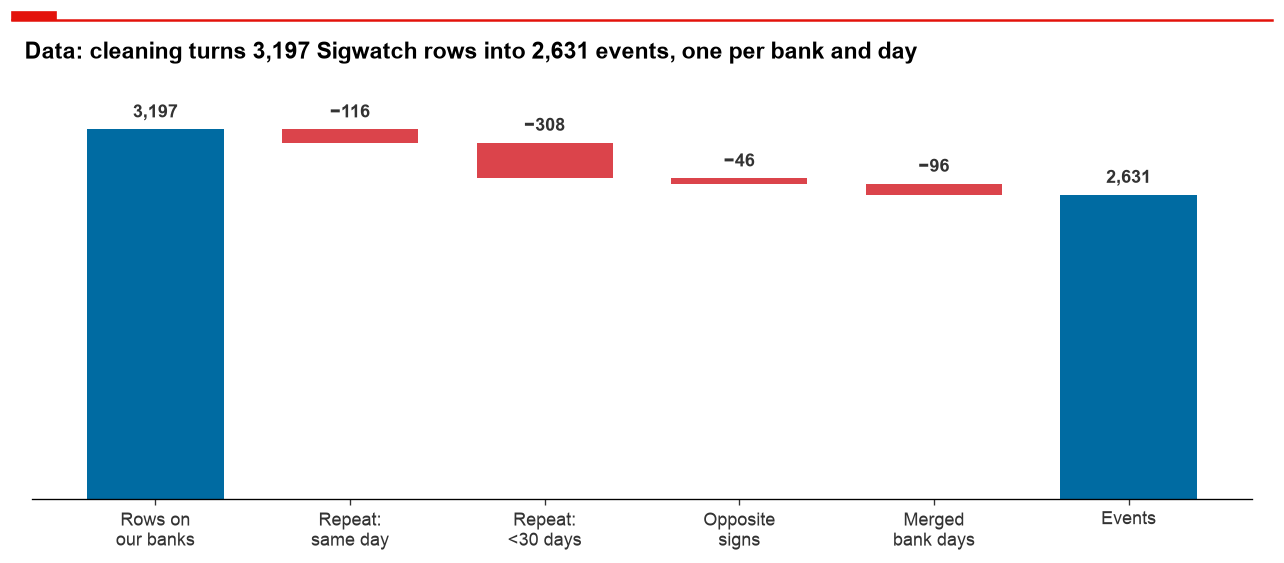

In [14]:
def plot_waterfall(ax, counts, step_names, first_name, last_name):
    '''Draw a waterfall from a list of counts after each cleaning step.'''
    positions = range(1, len(counts))
    last_position = len(counts)

    # The first and last bars are totals, the others what a step removes
    for position, total in [(0, counts[0]), (last_position, counts[-1])]:
        ax.bar(position, total, width=0.7, color=BLUE)
        annotate(ax, f"{total:,}", (position, total), offset=(0, 10),
                 fontweight="bold")

    for position in positions:
        before, after = counts[position - 1], counts[position]
        ax.bar(position, before - after, bottom=after, width=0.7,
               color=LIGHT_RED)
        annotate(ax, f"-{before - after:,}", (position, before),
                 offset=(0, 10), fontweight="bold")

    ax.set_xticks(range(last_position + 1),
                  [first_name, *step_names, last_name])
    ax.set_ylim(0, counts[0] * 1.1)  # room for the labels

row_counts = [len(bank_rows), len(ngo_days), len(first_events),
              len(no_conflicts), len(bank_days)]
step_names = ["Repeat:\nsame day", "Repeat:\n<30 days", "Opposite\nsigns", "Merged\nbank days"]

fig, ax = plt.subplots(figsize=(10.5, 4.5))
plot_waterfall(ax, row_counts, step_names, "Rows on\nour banks", "Events")
ax.set_yticks([])
ax.grid(False)
show(f"Data: cleaning turns {len(bank_rows):,} Sigwatch rows into {len(events):,} events, one per bank and day")

**Comments – D1.3**
* **41 bank days held both signs before cleaning,** which step 4 alone would have hidden.
* **Why the same day rule:** the 5 days of the do file cost 31% of positive rows against 6%, as a positive event is rare and a negative one usually close. `conflict_5_days` flags the 204 events it would remove (109 negative, 95 positive), for a check in 6.5.

### D1.4 How many campaigns, NGOs and banks
We count NGOs by `ngo_code`, because names are not unique.

In [15]:
def describe_events(events):
    '''Measure the size of the sample, for all events and per sign.'''
    groups = {"all": events, **dict(tuple(events.groupby("sign")))}
    rows = [{"events": len(group),
             "share": len(group) / len(events),
             "banks": group["bank"].nunique(),
             "lead NGOs": group["ngo_code1"].nunique(),
             "days": group["date"].nunique(),
             "headline share": (group["prominence"] == 4).mean(),  # 4 = headline
             "several NGOs": (group["n_ngos"] > 1).mean()}
            for group in groups.values()]
    return pd.DataFrame(rows, index=list(groups)).rename_axis("sign")

# Over all five slots, because a co-signing NGO counts too
all_ngos = no_conflicts[NGO_SLOTS].stack().nunique()
print("Different NGOs over all five slots:", all_ngos)

describe_events(events).style.format({
    "events": "{:,}",
    "share": "{:.1%}",
    "days": "{:,}",
    "headline share": "{:.1%}",
    "several NGOs": "{:.1%}",
})

Different NGOs over all five slots: 516


,events,share,banks,lead NGOs,days,headline share,several NGOs
sign,,,,,,,
all,"2,631",100.0%,64,335,882,19.7%,35.4%
negative,"2,134",81.1%,63,293,779,21.4%,37.1%
neutral,143,5.4%,30,57,80,9.8%,22.4%
positive,354,13.5%,35,102,200,13.3%,30.5%


**The variables.** `sentiment` is the tone towards the firm, coded by Sigwatch staff from −2 to +2. `prominence` says where the firm is named, from 1 (only in an attached report) to 4 (headline). `ngo_power` is the geographic reach of the NGO, from local (0.5) to global (2.75).

Events from NGOs of reach 1.5 or less: 68%


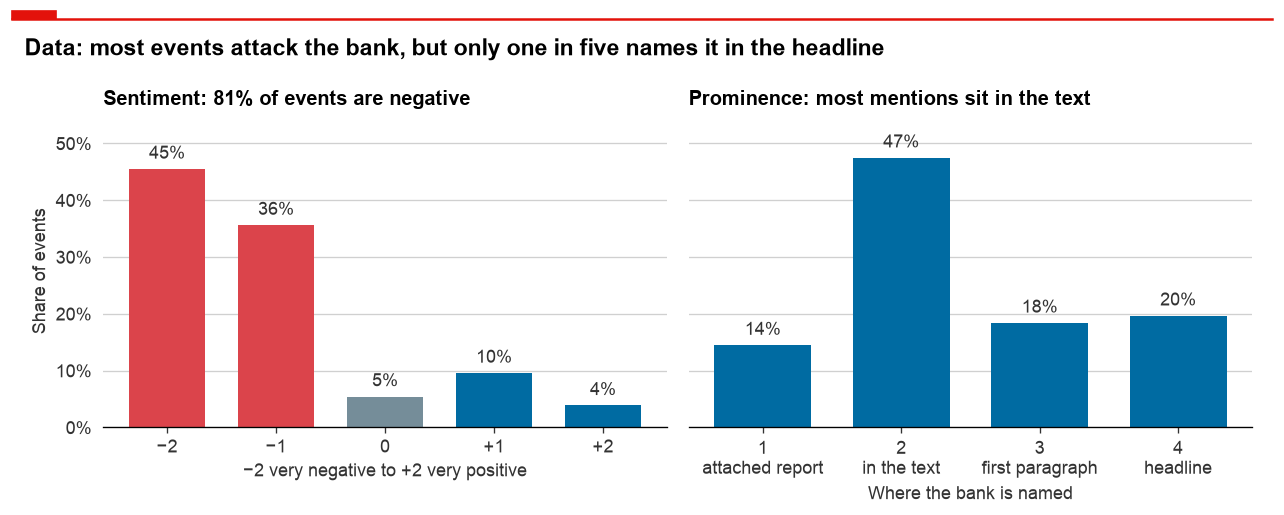

In [16]:
def share_bars(ax, shares, labels, colors, title, xlabel):
    '''Draw the share of events per value, with the share on each bar.'''
    bars = ax.bar(labels, shares.values, color=colors, width=0.7)
    for bar, share in zip(bars, shares.values):
        middle = bar.get_x() + bar.get_width() / 2
        annotate(ax, f"{share:.0%}", (middle, share), offset=(0, 9))

    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_ylim(0, 0.55)  # same scale on every panel, room for the labels
    ax.set_title(title, fontsize=12)
    ax.set_xlabel(xlabel)

SIGNS = ["negative", "positive"]  # neutral events stay out of the tests
SENTIMENT_LABELS = {-2: "−2", -1: "−1", 0: "0", 1: "+1", 2: "+2"}
SENTIMENT_COLORS = {
    "negative": LIGHT_RED,
    "neutral": GREY,
    "positive": BLUE,
}

sentiment_shares = events["sentiment"].value_counts(normalize=True).sort_index()
prominence_shares = events["prominence"].value_counts(normalize=True).sort_index()

sentiment_signs = np.sign(sentiment_shares.index).map(SIGN_NAMES)
sentiment_colors = [SENTIMENT_COLORS[sign] for sign in sentiment_signs]

sentiment_labels = [SENTIMENT_LABELS[level] for level in sentiment_shares.index]
prominence_labels = ["1\nattached report", "2\nin the text",
                     "3\nfirst paragraph", "4\nheadline"]
negative_share_all = (events["sentiment"] < 0).mean()

print(f"Events from NGOs of reach 1.5 or less: {(events['ngo_power'] <= 1.5).mean():.0%}")

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.12), sharey=True)

share_bars(axes[0], sentiment_shares, sentiment_labels, sentiment_colors,
           f"Sentiment: {negative_share_all:.0%} of events are negative",
           "−2 very negative to +2 very positive")
share_bars(axes[1], prominence_shares, prominence_labels, BLUE,
           "Prominence: most mentions sit in the text",
           "Where the bank is named")

axes[0].set_ylabel("Share of events")
show("Data: most events attack the bank, but only one in five names it in the headline")

**Comments – D1.4**
* **2,631 events on 882 days:** 2,134 negative (81.1%), 354 positive (13.5%), 143 neutral (5.4%). Krüger (2015) has 1,542 negative and 574 positive, so our comparison group is thinner. 35.4% of events involve several NGOs.
* **Why Task #6 tests headlines apart:** many events may be small news, and negative events reach the headline more often (21.4%) than positive ones (13.3%). About two events in three come from NGOs of reach 1.5 or less.

### D1.5 Campaigns over time
A rising count could just be better coverage, so we also look at banks as a share of all Sigwatch rows, and first at whether the labels are coded the same way every year. The dashed lines mark the two dates of Task #6.

In [17]:
per_year = events.groupby(["year", "sign"]).size().unstack(fill_value=0)

# All of Sigwatch: a change of method would hit every sector
neutral_share = (raw["sentiment"] == 0).groupby(row_year).mean()

negative_rows = raw[raw["sentiment"] < 0]
is_harshest = negative_rows["sentiment"] == -2
harshest_share = is_harshest.groupby(negative_rows["date"].dt.year).mean()

coding = pd.DataFrame({
    "neutral rows, all Sigwatch": neutral_share,
    "-2 among negative rows, all Sigwatch": harshest_share,
    "neutral events on banks": per_year["neutral"],
}).rename_axis("year")

coding.style.format({
    "neutral rows, all Sigwatch": "{:.1%}",
    "-2 among negative rows, all Sigwatch": "{:.0%}",
})

,"neutral rows, all Sigwatch","-2 among negative rows, all Sigwatch",neutral events on banks
year,,,
2010,5.1%,23%,12
2011,5.2%,63%,17
2012,7.4%,68%,20
2013,8.0%,64%,20
2014,7.7%,61%,20
2015,7.6%,52%,46
2016,1.9%,58%,3
2017,2.1%,66%,4
2018,2.3%,59%,1


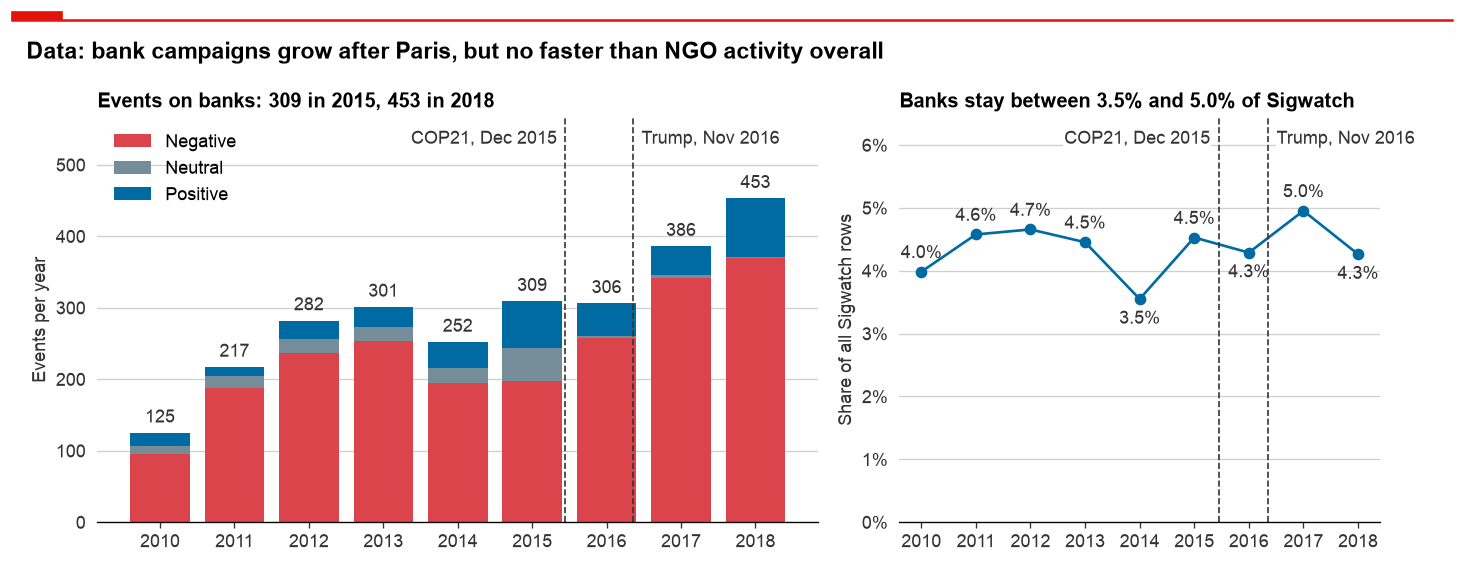

In [18]:
COP21 = pd.Timestamp("2015-12-12")  # Paris Agreement adopted
TRUMP = pd.Timestamp("2016-11-08")  # US presidential election
EVENT_DATES = [(COP21, "COP21, Dec 2015", "right"),
               (TRUMP, "Trump, Nov 2016", "left")]


def event_lines(ax):
    '''Draw dashed lines for COP21 and the Trump election, on an axis in years.'''
    top = ax.get_ylim()[1]
    for date, label, side in EVENT_DATES:
        position = date.year + (date.dayofyear - 1) / 365
        shift = -5 if side == "right" else 5
        ax.axvline(position, color=DARK, ls="--", lw=1)
        annotate(ax, label, (position, top), offset=(shift, -8), ha=side,
                 va="top", bbox=WHITE_BOX)

def stacked_year_bars(ax, table, colors, labels):
    '''Stack the columns of a yearly table, with one bar per year.'''
    bottom = np.zeros(len(table))
    for column, color, label in zip(table.columns, colors, labels):
        # + 0.5: bars in the middle of their year, so event lines fit the axis
        ax.bar(table.index + 0.5, table[column], bottom=bottom, width=0.8,
               color=color, label=label)
        bottom += table[column].values

    ax.set_xticks(table.index + 0.5, list(table.index))

def plot_events_per_year(ax, per_year):
    '''Show the events per year, stacked by sign, with the total on top.'''
    totals = per_year.sum(axis=1)
    labels = [sign.capitalize() for sign in per_year.columns]
    stacked_year_bars(ax, per_year, SENTIMENT_COLORS.values(), labels)

    for year, total in totals.items():
        annotate(ax, f"{total:.0f}", (year + 0.5, total), offset=(0, 9))

    ax.set_ylim(0, totals.max() * 1.25)  # room for the labels and the legend
    ax.set_ylabel("Events per year")
    ax.legend(loc="upper left")
    ax.set_title(f"Events on banks: {totals[2015]:.0f} in 2015, "
                 f"{totals[2018]:.0f} in 2018", fontsize=12)
    event_lines(ax)

LOW_YEARS = [2014, 2016, 2018]  # local lows: the label goes under the line


def plot_bank_share(ax, bank_share):
    '''Show the share of banks in all Sigwatch rows, year by year.'''
    ax.plot(bank_share.index + 0.5, bank_share.values,
            color=BLUE, marker="o")

    for year, share in bank_share.items():
        shift = -12 if year in LOW_YEARS else 11
        annotate(ax, f"{share:.1%}", (year + 0.5, share), offset=(0, shift))

    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_ylim(0, bank_share.max() * 1.3)  # room for the labels
    ax.set_xticks(bank_share.index + 0.5, list(bank_share.index))
    ax.set_ylabel("Share of all Sigwatch rows")
    ax.set_title(f"Banks stay between {bank_share.min():.1%} and "
                 f"{bank_share.max():.1%} of Sigwatch", fontsize=12)
    event_lines(ax)

rows_per_year = raw.groupby(row_year).size()
bank_rows_per_year = bank_rows.groupby(bank_rows["date"].dt.year).size()
bank_share = bank_rows_per_year / rows_per_year

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5),
                         gridspec_kw={"width_ratios": [1.5, 1]})
plot_events_per_year(axes[0], per_year)
plot_bank_share(axes[1], bank_share)
show("Data: bank campaigns grow after Paris, but no faster than NGO activity overall")

**Comments – D1.5**
* **The rise reflects NGO activity or coverage overall, not a new target:** all of Sigwatch grows as fast, from 8,547 rows in 2015 to 12,574 in 2018.
* **A caveat the chart cannot show:** Sigwatch's coding seems to change. Neutral rows fall from 7.6% in 2015 to 1.9% in 2016 across all firms, and only 23% of negative rows in 2010 carry −2, against 52% to 68% later. A comparison around COP21 could partly pick up the coding, so the sign of an event is safer than its level, and we rerun without 2010 to 2012.

### D1.6 Banks and NGOs
A few large banks or NGOs could carry the whole sample, and same day reports and repeat targets make events less independent than their number suggests.

In [19]:
FEW_EVENTS = 3  # at most this many events: a rare target
MANY_EVENTS = 50  # at least this many events: a regular target

events_per_bank = events["bank"].value_counts()
events_per_date = events.groupby("date")["bank"].transform("size")
banks_per_report = events.groupby("uid_archive")["bank"].nunique()

few_events = (events_per_bank <= FEW_EVENTS).sum()
many_events = (events_per_bank >= MANY_EVENTS).sum()
shared_date = (events_per_date > 1).mean()
shared_report = (banks_per_report > 1).sum()

print("Median events per bank:", int(events_per_bank.median()))
print(f"Banks with {FEW_EVENTS} events or fewer:", few_events)
print(f"Banks with {MANY_EVENTS} events or more:", many_events)
print(f"Events sharing their date with others: {shared_date:.1%}")
print("Most events on one day:", events_per_date.max())
print(f"Reports on several banks: {shared_report} of {len(banks_per_report):,}")
# One report carries one label per bank
labels_per_report = events.groupby("uid_archive")["sentiment"].nunique()
signs_per_report = events.groupby("uid_archive")["sign"].nunique()
print(f"Reports with different labels: {(labels_per_report > 1).sum()}")
print(f"Reports with different signs: {(signs_per_report > 1).sum()}")

Median events per bank: 15
Banks with 3 events or fewer: 22
Banks with 50 events or more: 18
Events sharing their date with others: 85.8%
Most events on one day: 21
Reports on several banks: 541 of 1,139
Reports with different labels: 157
Reports with different signs: 123


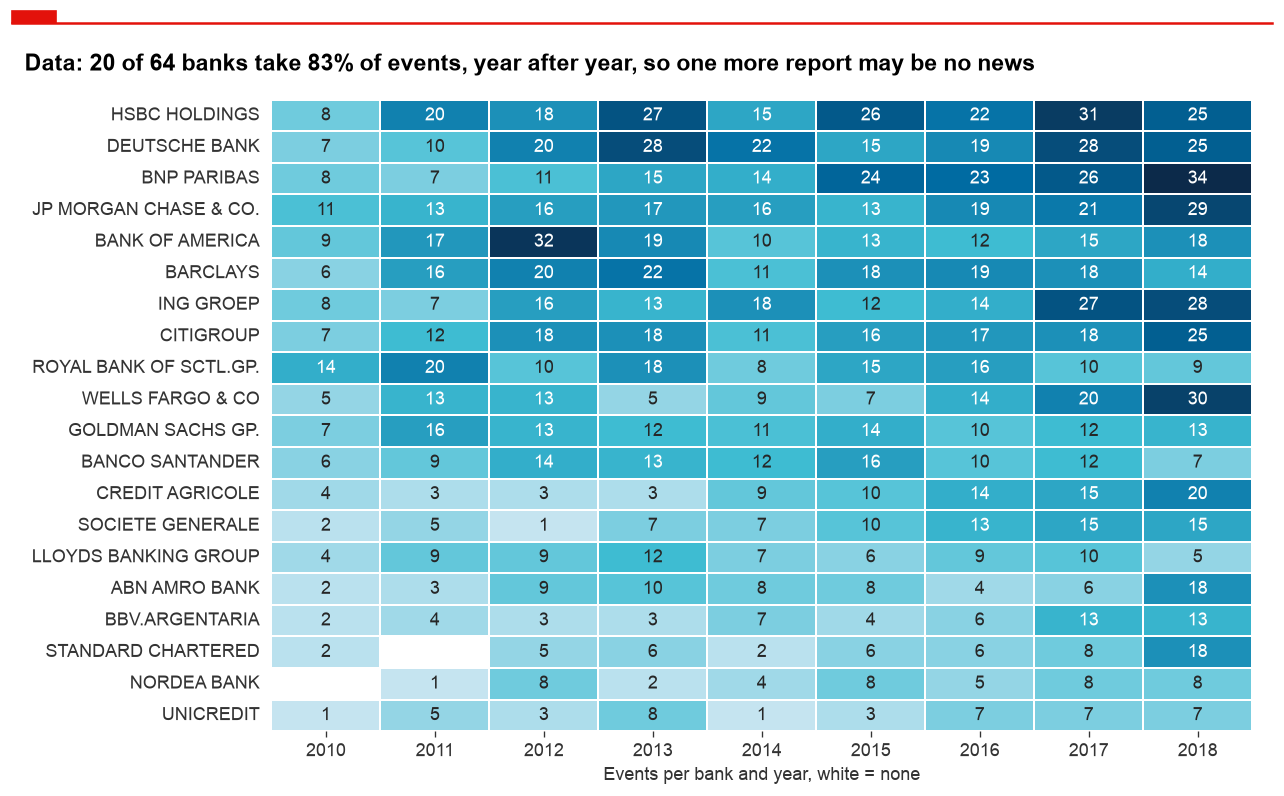

In [20]:
TOP_BANKS = 20  # banks in the heatmap

top_banks = events_per_bank.head(TOP_BANKS).index
top_events = events[events["bank"].isin(top_banks)]
top_share = len(top_events) / len(events)

per_bank_year = top_events.groupby(["bank", "year"]).size().unstack()
# Reindex keeps the years without an event, as white cells
per_bank_year = per_bank_year.reindex(index=top_banks, columns=per_year.index)

fig, ax = plt.subplots(figsize=(10.5, 6.38))
sns.heatmap(per_bank_year, annot=True, fmt=".0f", cmap=ECONOMIST_BLUES,
            linewidths=1, cbar=False, ax=ax)
ax.set_xlabel("Events per bank and year, white = none")
ax.set_ylabel("")
ax.grid(False)
show(f"Data: {TOP_BANKS} of {len(events_per_bank)} banks take {top_share:.0%} of events, year after year, so one more report may be no news")

In [21]:
# Former names, such as "(formerly World Development Movement)", only lengthen the labels
FORMER_NAME = r" \((?:formerly|previously).*\)"

ngo_counts = events["ngo"].str.replace(FORMER_NAME, "", regex=True).value_counts()
cumulative_share = ngo_counts.cumsum() / len(events)
print(ngo_counts.head(10).to_string())
print(f"Lead NGOs: {len(ngo_counts)}, top 10: {cumulative_share.iloc[9]:.0%} of events, "
      f"top 50: {cumulative_share.iloc[49]:.0%}")

ngo
Amis de la Terre France / FoE France     150
Rainforest Action Network RAN            112
Which? (UK Consumers Association)         97
Sierra Club U.S.A.                        76
Eerlijke Bankwijzer / Fair Bank Guide     74
U.S. PIRG                                 66
Corporate Europe Observatory / CEO        52
ADICAE                                    52
FairFin                                   51
Global Justice Now                        48
Lead NGOs: 335, top 10: 30% of events, top 50: 63%


**Comments – D1.6**
* **The median bank has 15 events, and 18 banks have 50 or more.** Ten of 335 lead NGOs bring 30% of events, led by climate and consumer groups.
* **Why Task #6 clusters by event date:** 85.8% of events share their date with another, up to 21 on one day, and 541 of 1,139 reports name more than one bank, with different signs in 123.

### D1.7 Issues
Task #6 compares climate with the rest, so we check that Sigwatch's labels give large enough groups, and how they move around COP21.

In [22]:
GROUP_ORDER = [*ISSUE_GROUPS, "Other"]
GROUP_COLORS = dict(zip(GROUP_ORDER, [TEAL, YELLOW, CYAN, PURPLE, LIGHT_GREY]))

is_climate = events["issue_group"] == CLIMATE_GROUP
after_cop21 = events["date"] > COP21
climate_before = is_climate[~after_cop21].mean()
climate_after = is_climate[after_cop21].mean()

is_other = events["issue_group"] == "Other"
other_labels = events.loc[is_other, "issue_name1"].value_counts()

print(f"Climate share up to COP21: {climate_before:.1%}")
print(f"Climate share after COP21: {climate_after:.1%}")
print(other_labels.head(4).to_string())

Climate share up to COP21: 37.5%
Climate share after COP21: 55.5%
issue_name1
CSR/ESG standards for financial institutions    177
Regulation of financial institutions             87
Ethical investing/SRI                            29
CSR standards and reporting                      24


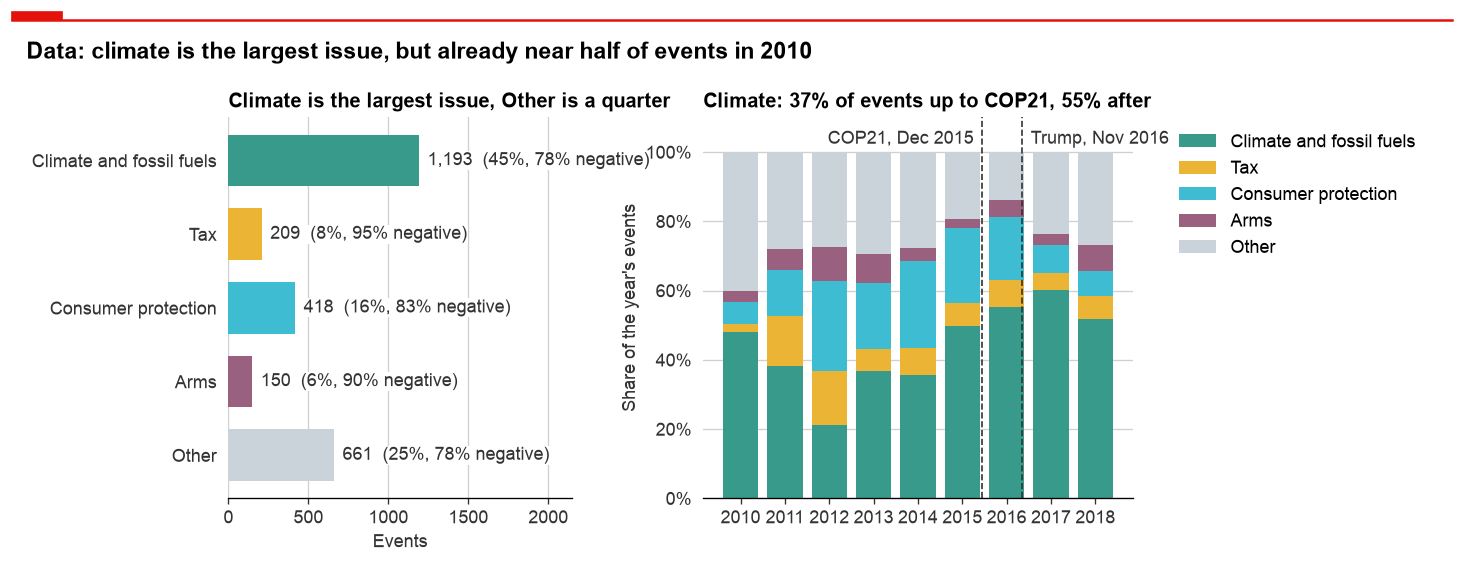

In [23]:
def plot_group_sizes(ax, events):
    '''Show the events per issue group, with share and negative share.'''
    counts = events["issue_group"].value_counts()
    counts = counts.reindex(GROUP_ORDER[::-1])  # barh starts at the bottom
    is_negative = events["sentiment"] < 0
    negative_share = is_negative.groupby(events["issue_group"]).mean()

    ax.barh(counts.index, counts.values, height=0.7,
            color=[GROUP_COLORS[group] for group in counts.index])
    for group, count in counts.items():
        share = count / len(events)
        negative = negative_share[group]
        label = f"{count:,}  ({share:.0%}, {negative:.0%} negative)"
        annotate(ax, label, (count, group), offset=(5, 0), bbox=WHITE_BOX)

    ax.set_xlim(0, counts.max() * 1.8)  # room for the labels
    vertical_grid(ax)
    ax.set_xlabel("Events")
    ax.set_title("Climate is the largest issue, Other is a quarter",
                 fontsize=12)

def plot_group_shares(ax, events):
    '''Show the share of each issue group per year.'''
    counts = events.groupby(["year", "issue_group"]).size()
    per_year = counts.unstack(fill_value=0)[GROUP_ORDER]
    shares = per_year.div(per_year.sum(axis=1), axis=0)

    colors = [GROUP_COLORS[group] for group in GROUP_ORDER]
    stacked_year_bars(ax, shares, colors, GROUP_ORDER)

    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_ylabel("Share of the year's events")
    ax.set_ylim(0, 1.1)  # room for the labels of the event lines
    ax.set_yticks(np.arange(0, 1.01, 0.2))
    ax.legend(loc="upper left", bbox_to_anchor=(1.07, 1))
    ax.set_title(f"Climate: {climate_before:.0%} of events up to COP21, "
                 f"{climate_after:.0%} after", fontsize=12)
    event_lines(ax)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5),
                         gridspec_kw={"width_ratios": [1.2, 1.5]})
plot_group_sizes(axes[0], events)
plot_group_shares(axes[1], events)
show("Data: climate is the largest issue, but already near half of events in 2010")

**Comments – D1.7**
* **The groups are large enough to test:** climate 1,193 events (45%), consumer protection 418, tax 209, arms 150, other 661. Climate is wide on purpose: the keywords of the do file also catch mining, logging and palm oil.
* **We write "after COP21", never "because of COP21":** climate is 37.5% of events up to COP21 and 55.5% after, yet already about 48% in 2010.

### D1.8 Countries
Country means the country of the parent. The group sizes set how much our check on US banks can show in Task #6.

In [24]:
REGION_ORDER = ["US", "UK", "Euro area", "Sweden"]

country_counts = events.groupby("country")["bank"].agg(events="size", banks="nunique")
country_counts = country_counts.sort_values("events", ascending=False)
print(country_counts.head(4).to_string())
print(country_counts.tail(3).to_string(header=False))
print(f"US and UK: {events['country_group'].isin(['US', 'UK']).mean():.0%} of events")

is_positive = events["sentiment"] > 0
positive_share = is_positive.groupby(events["country_group"]).mean()
print(positive_share[REGION_ORDER].map("{:.1%}".format).to_string())

issue_mix = pd.crosstab(events["country_group"], events["issue_group"], normalize="index")
print(issue_mix.reindex(index=REGION_ORDER, columns=GROUP_ORDER).map("{:.0%}".format).to_string())

             events  banks
country                   
US              779     24
UK              585      7
France          344      4
Netherlands     250      4
country       
Ireland   7  3
Austria   3  1
Portugal  3  1
US and UK: 52% of events
country_group
US            9.5%
UK           12.0%
Euro area    15.6%
Sweden       25.2%
issue_group   Climate and fossil fuels  Tax Consumer protection Arms Other
country_group                                                             
US                                 48%  11%                 15%   4%   21%
UK                                 45%  11%                 21%   3%   20%
Euro area                          45%   4%                 14%   8%   29%
Sweden                             32%   7%                  9%   8%   43%


**Comments – D1.8**
* **The US and the UK take 52% of the events** (779 on 24 US banks, 585 on 7 UK banks), so our check on US banks keeps a large sample, without a currency issue.
* **Regions differ:** climate leads everywhere except Sweden, and positive events run from 9.5% in the US to 25.2% in Sweden.

In [25]:
SHOWN_COLUMNS = ["bank", "date", "ngo", "sentiment", "prominence", "ngo_power",
                 "n_ngos", "issue_group"]
events[SHOWN_COLUMNS].sample(5, random_state=SEED)

,bank,date,ngo,sentiment,prominence,ngo_power,n_ngos,issue_group
221,JP MORGAN CHASE & CO.,2011-05-26,Global Witness,-2,4,2.5000,1,Other
318,SOCIETE GENERALE,2011-11-30,groundWork / FoE South Africa,-1,2,2.5000,3,Climate and fossil fuels
926,CITIGROUP,2014-01-02,WWF Russia,1,4,2.5000,1,Other
1355,BARCLAYS,2015-07-27,Which? (UK Consumers Association),-1,2,1.0000,1,Consumer protection
1421,DEUTSCHE BANK,2015-10-23,Urgewald,-2,4,1.0000,1,Climate and fossil fuels


## Day 2 – Explore the stock data
We build one clean table of Datastream total return indices for the same banks: one column per bank, one row per weekday, only banks with usable prices.

### D2.1 Load and clean
Datastream gives two series per firm: RI, the total return index with dividends reinvested, and PI, the price index without them. Every country has its own sheet, Sweden a separate file, and we leave out Norway and Switzerland. `banks_info.xlsx` lists the same firms with ISIN and country, but we do not need it: the sheet gives the country, and Day 1 matches by name. We then drop:
* **Everything after 31 January 2019:** Task #5 needs 10 trading days after our last event, with room for holidays. So the COVID-19 crash cannot enter our estimates.
* **Duplicate columns:** for a repeated name in a sheet pandas adds `.1` to the second column. We check that these are true copies, and compare the values to find copies under another name.
* **Non-banks,** added to match Sigwatch names: insurers, asset managers, Advance Auto Parts (car parts), Mersen (industrial), two central banks and KBC Ancora, a holding company whose asset is its stake in KBC.
* **Dead and illiquid series:** a stock that does not trade keeps its last price, so its return is exactly zero and its beta is meaningless. We drop series without any price, then every series with more than half of its returns at zero. Holidays are still in these returns (D2.5).

In [26]:
MAIN_INDEX = "banks_data_bocconi/banks_pi.xlsm"  # PI: the price index
NORDIC_INDEX = "banks_data_bocconi/scandinavian_banks_pi.xlsm"


def load_datastream(main_file, nordic_file, tail):
    '''Join the country sheets of one Datastream series into one table.'''
    sheets = read_sheets(main_file, nordic_file)

    tables = []
    for sheet in sheets.values():
        table = sheet.set_index("Name")
        table.columns = table.columns.str.replace(tail, "", regex=False)
        tables.append(table)
    return pd.concat(tables, axis=1)

ri_raw = load_datastream(MAIN_PRICES, NORDIC_PRICES, RI_TAIL)
pi_raw = load_datastream(MAIN_INDEX, NORDIC_INDEX, " - PRICE INDEX")

print(f"RI: {ri_raw.shape[1]} series, {len(ri_raw):,} days")
print(f"PI: {pi_raw.shape[1]} series, {len(pi_raw):,} days")
print(f"From {ri_raw.index.min():%d %b %Y} to {ri_raw.index.max():%d %b %Y}")
print("Rows without a date in PI:", pi_raw.index.isna().sum())
print("Days on a weekend:", (ri_raw.index.dayofweek > 4).sum())
print("Values of zero or below in RI:", (ri_raw <= 0).sum().sum())

SAMPLE_END = "2019-01-31"  # last event plus 10 trading days and holidays

ri_sample = ri_raw.loc[:SAMPLE_END]
pi_sample = pi_raw.loc[:SAMPLE_END]

print(f"Last event: {events['date'].max():%d %b %Y}")
print(f"Days kept: {len(ri_sample):,} of {len(ri_raw):,}")

def find_copies(table):
    '''Find the columns that pandas marked as a repeated name.'''
    return [name for name in table.columns if name.endswith(".1")]


for table in [ri_sample, pi_sample]:
    for copy in find_copies(table):
        original = copy.removesuffix(".1")
        print(copy, "same as original:", table[copy].equals(table[original]))

ri_unique = ri_sample.drop(columns=find_copies(ri_sample))

# Check: a second method, by content, finds no other copy in RI
# Transposed, because duplicated() compares rows
same_content = ri_unique.T.duplicated(keep=False).sum()
print("Other columns with the same content in RI:", same_content)

NON_BANKS = [
    # Insurers
    "AEGON", "AFLAC", "ALLIANZ", "AMERICAN INTL.GP.", "ASR NEDERLAND",
    "ADMIRAL GROUP", "AXIS CAPITAL HDG.",
    "AETNA CAP.L L C PF.MIPS 9 - %TOT RETURN IND",
    "DELTA LLOYD GROUP DEAD - DEAD 01/06/17",
    # Payment firms, a payday lender and other financial firms
    "AMERICAN EXPRESS", "MASTERCARD", "SAGA GROUP",
    "ACE CASH EXPRESS (BER) DEAD - 10/10/06",
    # Asset managers and funds
    "ARES MANAGEMENT A", "ALLIANCE TRUST",
    "ADVENT CONVERTIBLE AND INCOME FUND",
    # Firms outside finance
    "ADV.AUTO PARTS", "MERSEN (EX LCL)",
    # Central banks and a holding company
    "BANK OF GREECE", "BANQUE NATIONALE DE BELGIQUE", "KBC ANCORA",
]

ri_banks = ri_unique.drop(columns=NON_BANKS)
event_banks = events["bank"].unique()

print(f"Series: {ri_unique.shape[1]} to {ri_banks.shape[1]}")
print("Event banks among them:", len(set(NON_BANKS) & set(event_banks)))

MAX_ZERO_SHARE = 0.5  # above this a beta means little

ri_priced = ri_banks.dropna(axis=1, how="all")
no_prices = ri_banks.columns.difference(ri_priced.columns)
print("Series without prices in our sample:", list(no_prices))

# fill_method=None: a gap in the prices must not create a return
priced_returns = ri_priced.pct_change(fill_method=None)
zero_days = (priced_returns == 0).sum()
zero_share = zero_days / priced_returns.notna().sum()

illiquid = zero_share[zero_share > MAX_ZERO_SHARE].index
ri_liquid = ri_priced.drop(columns=illiquid)

print(f"Series dropped: {len(illiquid)} of {ri_priced.shape[1]}")
print("Event banks among them:", len(set(illiquid) & set(event_banks)))
print("Dropped:", list(illiquid))
print(zero_share[zero_share.between(0.25, MAX_ZERO_SHARE)].sort_values().map("{:.0%}".format).to_string())
top_event_bank = zero_share[event_banks].idxmax()
print(f"Highest event bank: {top_event_bank}, {zero_share[top_event_bank]:.0%}")

RI: 162 series, 3,363 days
PI: 164 series, 3,363 days
From 01 Jan 2008 to 19 Nov 2020
Rows without a date in PI: 0
Days on a weekend: 0
Values of zero or below in RI: 0
Last event: 18 Dec 2018
Days kept: 2,893 of 3,363
CREDIT AGRICOLE.1 same as original: True
CREDIT AGRICOLE.1 same as original: True
ERSTE GROUP BANK.1 same as original: True
RAIFFEISEN BANK INTL..1 same as original: True
Other columns with the same content in RI: 0
Series: 161 to 140
Event banks among them: 0
Series without prices in our sample: ['ILLIMITY BANK']
Series dropped: 12 of 139
Event banks among them: 0
Dropped: ['BANQUE DE SAVOIE DEAD - 01/04/10', 'LOMBARD BANK', 'BANK FUR TIROL UND VBG.', 'BKS BANK', 'OBERBANK', 'OBERBANK PREF.', 'OTP BANKA SLOVENSKO', 'OTP BANKA SLOVENSKO2', 'OTP BANKA SLOVENSKO3', 'TATRA BANKA', 'TATRA BANKA 2', 'VSEOBECNA UVEROVA BANKA']
PROCREDIT HOLDING                       27%
LHV GROUP                               28%
BANK OF VALLETTA                        28%
EUROBANK HOLDINGS   

**Comments – D2.1**
* **The layout is clean:** 162 RI series and 164 PI series, all on weekdays, no row without a date and no value of zero or below. We keep 2,893 of 3,363 days.
* **This cleaning costs no campaign:** none of the 21 non-banks and 12 illiquid series has an event. The limit is no close call, as the highest event bank, Monte dei Paschi, stands at 22%. Holidays count as zero here, but are only about 100 of 2,892 days.
* **The rule misses Lehman preferred (46%),** whose problem is the opposite one (D2.2).

### D2.2 Outliers
Before we call a large move a data error, we compare RI with PI, a second series for the same price. Both come from Datastream, so this catches an error in one series, not one they share.

In [27]:
LEHMAN = "LEHMAN BROS.HDG.CAP.TST. III PF.SR.K"
LARGE_MOVE = 0.3  # a daily move above 30% in either direction


def large_moves(returns):
    '''List the daily returns above the limit in either direction.'''
    all_returns = returns.stack()
    return all_returns[all_returns.abs() > LARGE_MOVE]


liquid_returns = ri_liquid.pct_change(fill_method=None)
moves_before = large_moves(liquid_returns)
is_lehman = moves_before.index.get_level_values(1) == LEHMAN

print("Large moves, all series:", len(moves_before))
print("Of which Lehman preferred:", is_lehman.sum())
print(f"Largest move of Lehman: {moves_before[is_lehman].max():+.0%}")
print(f"Lowest RI of Lehman: {ri_liquid[LEHMAN].min():.2f}")

prices = ri_liquid.drop(columns=LEHMAN)  # final table of prices, in local currency
returns = prices.pct_change(fill_method=None)

moves_after = large_moves(returns)
move_dates = moves_after.index.get_level_values(0)
crisis_share = (move_dates.year <= 2009).mean()

print("Large moves left:", len(moves_after))
print(f"Of which in 2008 and 2009: {crisis_share:.0%}")

Large moves, all series: 642
Of which Lehman preferred: 510
Largest move of Lehman: +1250%
Lowest RI of Lehman: 0.01
Large moves left: 132
Of which in 2008 and 2009: 60%


Are the largest moves left real? If RI and PI agree, the move is in the price and not an error in one series.

In [28]:
TOP_MOVES = 10  # moves in the table

# One bank has no PI series
pi_banks = pi_sample[prices.columns.intersection(pi_sample.columns)]
pi_returns = pi_banks.pct_change(fill_method=None)

largest = moves_after.sort_values(key=abs, ascending=False).head(TOP_MOVES)
largest_table = largest.rename("RI return").to_frame()
largest_table["PI return"] = pi_returns.stack().reindex(largest.index)
largest_table = largest_table.rename_axis(["date", "bank"]).reset_index()
bank_events = largest_table["bank"].map(events_per_bank)
largest_table["events"] = bank_events.fillna(0).astype(int)

largest_table.style.format({
    "date": "{:%d %b %Y}",
    "RI return": "{:+.0%}",
    "PI return": "{:+.0%}",
})

,date,bank,RI return,PI return,events
0,30 Apr 2013,BANKIA,+191%,+190%,26
1,26 Jan 2009,BARCLAYS,+73%,+73%,144
2,25 Oct 2017,BANCA MONTE DEI PASCHI,-69%,-50%,1
3,19 Jan 2009,ROYAL BANK OF SCTL.GP.,-67%,-67%,120
4,25 Mar 2009,CREDIT FONCIER DE MONACO,+65%,+65%,0
5,18 Sep 2008,WESTERN ALL.BANCORP.,+63%,+64%,0
6,06 Feb 2009,FIFTH THIRD BANCORP,+60%,+60%,3
7,23 Sep 2011,PERMANENT TSB GHG.,+59%,+56%,1
8,29 Nov 2010,PERMANENT TSB GHG.,+59%,+59%,1
9,08 May 2009,FIFTH THIRD BANCORP,+59%,+59%,3


**Comments – D2.2**
* **One series made most of the noise:** Lehman preferred, the share of a bankrupt firm with an RI as low as 0.01, holds 510 of 642 moves above 30%, so we drop it. Of the 132 left, 60% fall in 2008 and 2009.
* **The largest moves are real:** RI and PI agree within one point on eight of the top ten. The two exceptions, Permanent TSB and Monte dei Paschi, trade at very low prices, where rounding matters. Bankia's +191% is in both, and as it can still distort betas and CARs, Task #4 flags events with a move above 50%, and Task #6 winsorises CARs (values beyond a percentile limit are set to that limit).

### D2.3 Why returns come from RI
PI ignores dividends, as HSBC, our most targeted bank, shows in pounds.

In [29]:
BANK_EXAMPLE = "HSBC HOLDINGS"


def growth_of_one(index_values):
    '''Turn an index into the growth of 1 from its first day.'''
    return index_values / index_values.iloc[0]


with_dividends = growth_of_one(prices[BANK_EXAMPLE])
without_dividends = growth_of_one(pi_banks[BANK_EXAMPLE])
dividend_gap = with_dividends.iloc[-1] - without_dividends.iloc[-1]

print(f"Banks with PI: {pi_banks.shape[1]} of {prices.shape[1]}")
print(f"Gap at the end: £{dividend_gap:.2f} per £1 invested")
print(f"£1 in 2008 ends at £{without_dividends.iloc[-1]:.2f} without dividends, £{with_dividends.iloc[-1]:.2f} with them")

Banks with PI: 125 of 126
Gap at the end: £0.65 per £1 invested
£1 in 2008 ends at £0.87 without dividends, £1.52 with them


**Comments – D2.3**
* **So all returns come from RI:** £1 in HSBC in 2008 ends at £0.87 without dividends and £1.52 with them, and PI would make a bank look worse on every dividend day. PI has one decimal only, so it stays out of the panel.

### D2.4 Data after cleaning
Daily returns of our most targeted bank against the normal distribution, and the Jarque-Bera test for the eight most targeted banks, built from skewness and excess kurtosis as in PC Labs #1 and #2.

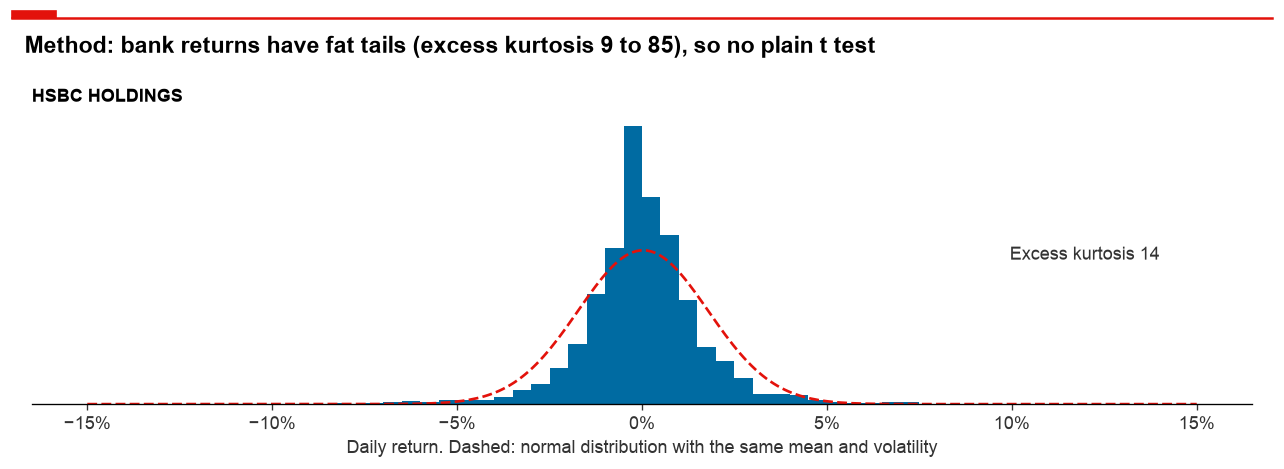

In [30]:
TOP_TARGETS = 8  # banks in the figure
BINS = np.arange(-0.15, 0.1501, 0.005)  # half a point wide
RETURN_GRID = np.linspace(-0.15, 0.15, 300)
KURTOSIS_LABEL = (0.14, 22)  # top right of each panel: return, density


def plot_distribution(ax, daily_returns, bank):
    '''Show one bank's daily returns against a normal distribution.'''
    daily = daily_returns.dropna()
    ax.hist(daily, bins=BINS, density=True, color=BLUE)
    ax.plot(RETURN_GRID, stats.norm.pdf(RETURN_GRID, daily.mean(), daily.std()),
            color=ECONOMIST_RED, ls="--")
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_title(bank, fontsize=11)
    annotate(ax, f"Excess kurtosis {daily.kurt():.0f}", KURTOSIS_LABEL,
             offset=(0, 0), ha="right")

top_targets = events_per_bank.head(TOP_TARGETS).index
excess_kurtosis = returns[top_targets].kurt()

fig, ax = plt.subplots(figsize=(10.5, 3.75))
plot_distribution(ax, returns[BANK_EXAMPLE], BANK_EXAMPLE)
ax.set_yticks([])
ax.set_xlabel("Daily return. Dashed: normal distribution with the same mean and volatility")
show(f"Method: bank returns have fat tails (excess kurtosis {excess_kurtosis.min():.0f} to {excess_kurtosis.max():.0f}), so no plain t test")

In [31]:
daily = returns[top_targets]
jb = daily.count() / 6 * (daily.skew() ** 2 + daily.kurt() ** 2 / 4)  # kurt() gives excess kurtosis
jb_p_values = stats.chi2.sf(jb, df=2)
print(f"Jarque-Bera rejects normality at 1% for {(jb_p_values < 0.01).sum()} of {len(jb)} banks")

Jarque-Bera rejects normality at 1% for 8 of 8 banks


In [32]:
# Check: compounded returns rebuild the index from its first day
# Missing returns count as no change, only for this check
compounded = (1 + returns.fillna(0)).prod()
index_growth = prices.ffill().iloc[-1] / prices.bfill().iloc[0]
assert np.allclose(compounded, index_growth)

assert set(event_banks) <= set(prices.columns)
series_steps = [ri_sample, ri_unique, ri_banks, ri_priced, ri_liquid, prices]
print("Series after each cleaning step:", [table.shape[1] for table in series_steps])
print(f"Table of prices: {len(prices):,} days, {prices.shape[1]} banks")

Series after each cleaning step: [162, 161, 140, 139, 127, 126]
Table of prices: 2,893 days, 126 banks


**Comments – D2.4**
* **Why Task #6 goes beyond a t test:** Jarque-Bera rejects normality for all eight banks, with Barclays at a kurtosis of 85 after its +73% day. The sign test needs no normal distribution, the BMP test (Boehmer, Musumeci and Poulsen, 1991) scales every bank by its own volatility, and winsorising limits extreme days (6.2).
* **We keep 126 of 162 series and all 64 event banks.** `prices` is still in local currency and holds the holidays.

### D2.5 Holidays
Datastream repeats the last price on a holiday, and these false zero returns would pull betas towards zero. The Fama French files of D2.7 cannot tell us the holidays, as they hold every weekday, Christmas Day included. So we read them from the prices: a day is a holiday for a region when all its big banks show exactly zero, which large banks almost never do on a real trading day. Every bank gets its region from the sheet of its price series, which we compare with the groups of Day 1 (the parent's country).

In [33]:
SHEET_REGIONS = {"US": "US", "UK": "UK", "SD": "Sweden"}  # others: euro area

bank_sheet = series_sheet[prices.columns]
bank_region = bank_sheet.map(SHEET_REGIONS).fillna("Euro area")
print(bank_region.value_counts().to_string())

event_region = events["bank"].map(bank_region)
other_region = events[event_region != events["country_group"]]
print(other_region["bank"].value_counts().to_string())

Euro area    64
US           48
UK           10
Sweden        4
bank
NORDEA BANK    44


In [34]:
# Large, liquid banks: if all of them stand still, the market was closed
BIG_BANKS = {
    "US": ["BANK OF AMERICA", "CITIGROUP", "JP MORGAN CHASE & CO.",
           "WELLS FARGO & CO"],
    "UK": ["BARCLAYS", "HSBC HOLDINGS", "LLOYDS BANKING GROUP",
           "ROYAL BANK OF SCTL.GP."],
    "Euro area": ["BANCO SANTANDER", "BNP PARIBAS", "DEUTSCHE BANK",
                  "ING GROEP", "SOCIETE GENERALE"],
    "Sweden": ["SKANDINAVISKA ENSKILDA BANKEN A", "SVENSKA HANDELSBANKEN A",
               "SWEDBANK A"],
}


def find_holidays(returns, banks):
    '''Mark the days when all the given banks show exactly zero.'''
    return returns[banks].eq(0).all(axis=1)


holidays = pd.DataFrame(index=returns.index)
for region, banks in BIG_BANKS.items():
    holidays[region] = find_holidays(returns, banks)

print(holidays.sum().to_string())

US           102
UK            90
Euro area     53
Sweden       108


Two tests of the rule: known closures must be on the list (Hurricane Sandy and the funeral of President Bush for the US, Christmas for everybody), and on the days we find the other banks of the region must stand still too, while no other day may look like a holiday.

In [35]:
assert holidays.loc["2012-10-29":"2012-10-30", "US"].all()  # Hurricane Sandy
assert holidays.loc["2018-12-05", "US"]  # Bush funeral
assert holidays.loc["2018-12-25"].all()  # Christmas

NEAR_ALL_ZERO = 0.7  # share of banks at zero that looks like a holiday

rows = []
for region in REGION_ORDER:
    banks = bank_region[bank_region == region].index
    zero_banks = (returns[banks] == 0).sum(axis=1)
    zero_share_of_day = zero_banks / returns[banks].notna().sum(axis=1)
    is_holiday = holidays[region]
    other_days = zero_share_of_day[~is_holiday]
    rows.append({
        "holidays": is_holiday.sum(),
        "banks at zero on them": zero_share_of_day[is_holiday].median(),
        "other days with 70% at zero": (other_days >= NEAR_ALL_ZERO).sum(),
    })

holiday_check = pd.DataFrame(rows, index=REGION_ORDER)
holiday_check.style.format({"banks at zero on them": "{:.0%}"})

,holidays,banks at zero on them,other days with 70% at zero
US,102,100%,0
UK,90,100%,0
Euro area,53,94%,1
Sweden,108,100%,2


In [36]:
# A closure in one country is no euro area holiday, so the rule cannot see it
is_euro_event = event_region == "Euro area"
euro_banks = events[is_euro_event].groupby("country")["bank"].unique()

for country, banks in euro_banks.items():
    # One bank at zero could simply be illiquid
    if len(banks) > 1:
        all_zero = find_holidays(returns, list(banks))
        local_closures = all_zero & ~holidays["Euro area"]
        print(f"{country} ({len(banks)} banks), days: {local_closures.sum()}")

France (4 banks), days: 1
Germany (3 banks), days: 18
Ireland (3 banks), days: 30
Italy (4 banks), days: 25
Netherlands (4 banks), days: 0
Spain (8 banks), days: 0


**Comments – D2.5**
* **102 holidays in the US, 90 in the UK, 53 in the euro area, 108 in Sweden.** On them 94% to 100% of a region's banks stand still, while at most two other days look like a holiday.
* **Closures in one country stay invisible:** Ireland 30 days, Italy 25, Germany 18, France 1, so the euro area keeps more zero returns. We accept this to keep one simple rule.
* **Nordea changes group:** its 44 events are Swedish in Day 1, by the parent's country, but its prices follow the euro area.

### D2.6 Conversion from local currency to US dollars
The Fama French factors are in US dollars, so we convert every price: returns and factors then share a currency, and the US T-bill is the right risk free rate for all banks. Covered interest parity supports this: a foreign bill hedged into dollars earns about the US rate. The file quotes pounds and euros as dollars per unit, but the krona as units per dollar, so we invert it.

In [37]:
FX_FILE = "Exchange_Rates_LSEG.xlsx"    # Excel file holding Datastream exchange rates
REGION_CURRENCY = {"US": "USD", "UK": "GBP", "Euro area": "EUR",
                   "Sweden": "SEK"}


def load_fx():
    '''Load the exchange rates as US dollars per unit of each currency.'''
    rates = pd.read_excel(FX_FILE, index_col=0).rename_axis("date")
    rates.columns = ["GBP", "EUR", "SEK", "NOK", "CHF"]

    fx = pd.DataFrame(index=rates.index)
    fx["USD"] = 1.0  # US banks use the same formula
    fx["GBP"] = rates["GBP"]
    fx["EUR"] = rates["EUR"]
    fx["SEK"] = 1 / rates["SEK"]  # quoted as krona per dollar
    return fx


fx = load_fx().loc[:SAMPLE_END]
assert fx.index.equals(prices.index)
assert not fx.isna().any().any()
print(fx.iloc[[0, -1]].round(4).to_string())

              USD    GBP    EUR    SEK
date                                  
2008-01-01 1.0000 1.9906 1.4620 0.1547
2019-01-31 1.0000 1.3154 1.1474 0.1105


Sigwatch files Nordea under Sweden, but its series is the Helsinki quote, so we treat it as a euro series. If so, its return gap to the Swedish banks must fall when the euro rises against the krona, with a slope near −1, and near zero for a placebo of two Swedish banks.

In [38]:
HAC_LAGS = 5  # one trading week of Newey-West lags

# Both in dollars per unit, so their ratio is krona per euro
euro_in_krona = (fx["EUR"] / fx["SEK"]).pct_change().rename("euro")
swedish_banks = returns[BIG_BANKS["Sweden"]].mean(axis=1)

for name, bank in [("Nordea", "NORDEA BANK"), ("Placebo", "SWEDBANK A")]:
    data = pd.concat([returns[bank] - swedish_banks, euro_in_krona], axis=1).dropna()
    fit = ols(data.iloc[:, 0], data["euro"], hac_lags=HAC_LAGS)
    print(f"{name}: slope {fit.params[1]:.2f}, t {fit.tvalues[1]:.1f}")

Nordea: slope -0.79, t -9.9
Placebo: slope -0.03, t -0.4


In [39]:
bank_currency = bank_region.map(REGION_CURRENCY)
bank_fx = fx[bank_currency.values]
bank_fx.columns = prices.columns

usd_prices = prices * bank_fx

def trading_day_returns(usd_prices, holidays, bank_region):
    '''Compute returns over the trading days of each bank's region.'''
    tables = []
    for region in holidays.columns:
        banks = bank_region[bank_region == region].index
        trading_days = ~holidays[region]
        # Without holidays, pct_change spans them and keeps the currency move
        region_prices = usd_prices.loc[trading_days, banks]
        tables.append(region_prices.pct_change(fill_method=None))

    region_returns = pd.concat(tables, axis=1, sort=False)
    # Holidays come back as missing returns
    return region_returns.reindex(index=usd_prices.index,
                                  columns=usd_prices.columns)


usd_returns = trading_day_returns(usd_prices, holidays, bank_region)

On a holiday the price stands still, but the exchange rate moves, and deleting that day's return would lose this currency move. So we compute returns over the trading days of each region: the holiday stays missing, and the next return covers both days.

We check the result against the formula $r^{USD}_t = (1 + r^{local}_t) \times S_t / S_{t-1} - 1$, on all days not touched by a holiday.

In [40]:
is_bank_holiday = holidays[bank_region.values]
is_bank_holiday.columns = prices.columns
# A return after a holiday spans two days, so the formula does not fit
after_holiday = is_bank_holiday.shift(1, fill_value=False)
normal_day = ~is_bank_holiday & ~after_holiday

fx_change = bank_fx.pct_change()
formula_returns = (1 + returns) * (1 + fx_change) - 1

assert np.allclose(usd_returns.where(normal_day), formula_returns.where(normal_day), equal_nan=True)
assert usd_returns.where(is_bank_holiday).notna().sum().sum() == 0

# Check: compounded returns rebuild the dollar index across the holidays
compounded_usd = (1 + usd_returns.fillna(0)).prod()
usd_growth = usd_prices.ffill().iloc[-1] / usd_prices.bfill().iloc[0]
assert np.allclose(compounded_usd, usd_growth)

# Check: nothing changes for US banks, apart from the holidays
us_banks = bank_region[bank_region == "US"].index
# The dollar return after a US holiday spans two days, so we leave it out
us_trading = ~holidays["US"].shift(1, fill_value=False)
assert np.allclose(usd_returns.loc[us_trading, us_banks],
                   returns.loc[us_trading, us_banks].where(~holidays["US"]), equal_nan=True)

What do holidays and currency do to the numbers? We compare zero returns and volatility, and the day of the Brexit vote.

In [41]:
DAYS = 252  # trading days per year, used to annualise daily numbers
BREXIT = pd.Timestamp("2016-06-24")  # first trading day after the vote


def zero_rate(table):
    '''Compute the share of all returns that are exactly zero.'''
    return (table == 0).sum().sum() / table.notna().sum().sum()


def region_event_banks(region):
    '''List the event banks of one region.'''
    banks = bank_region[bank_region == region].index
    return banks.intersection(event_banks)

# In dollars a stale price still moves with the currency, so we count zeros
# in local currency, on the trading days of each region
local_trading = returns.where(usd_returns.notna())

rows = []
for region in REGION_ORDER:
    banks = region_event_banks(region)
    rows.append({
        "zero returns, all days": zero_rate(returns[banks]),
        "zero returns, trading days": zero_rate(local_trading[banks]),
        "volatility, local": returns[banks].std().median() * np.sqrt(DAYS),
        "volatility, USD": usd_returns[banks].std().median() * np.sqrt(DAYS),
    })

effect_table = pd.DataFrame(rows, index=REGION_ORDER)
print(f"HSBC on {BREXIT:%d %b %Y}: {returns.loc[BREXIT, BANK_EXAMPLE]:+.1%} "
      f"in pounds, {usd_returns.loc[BREXIT, BANK_EXAMPLE]:+.1%} in dollars")
effect_table.style.format("{:.1%}")

HSBC on 24 Jun 2016: -1.4% in pounds, -9.3% in dollars


,"zero returns, all days","zero returns, trading days","volatility, local","volatility, USD"
US,4.8%,1.3%,41.7%,42.4%
UK,3.9%,0.9%,40.1%,44.7%
Euro area,6.0%,4.3%,44.3%,47.2%
Sweden,5.9%,2.3%,38.6%,45.3%


Value against the US dollar since January 2008: {'GBP': '-34%', 'EUR': '-22%', 'SEK': '-29%'}


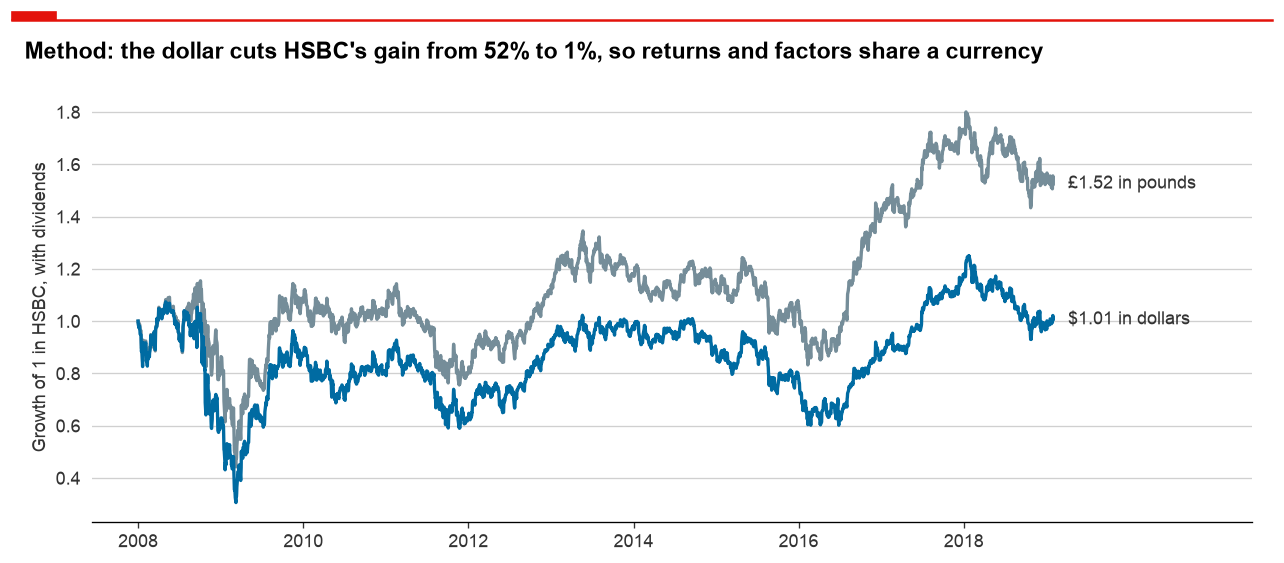

In [42]:
YEAR_TICKS = pd.date_range("2008", "2018", freq="2YS")

currency_loss = {currency: f"{growth_of_one(fx[currency]).iloc[-1] - 1:+.0%}" for currency in ["GBP", "EUR", "SEK"]}
print("Value against the US dollar since January 2008:", currency_loss)

hsbc_pounds = growth_of_one(prices[BANK_EXAMPLE])
hsbc_dollars = growth_of_one(usd_prices[BANK_EXAMPLE])
end_date = hsbc_pounds.index[-1]

fig, ax = plt.subplots(figsize=(10.5, 4.5))
ax.plot(hsbc_pounds, color=GREY, lw=2)
ax.plot(hsbc_dollars, color=BLUE, lw=2)
annotate(ax, f"£{hsbc_pounds.iloc[-1]:.2f} in pounds", (end_date, hsbc_pounds.iloc[-1]))
annotate(ax, f"${hsbc_dollars.iloc[-1]:.2f} in dollars", (end_date, hsbc_dollars.iloc[-1]))
ax.set_xlim(right=pd.Timestamp("2021-06-30"))  # room for the labels
ax.set_xticks(YEAR_TICKS, YEAR_TICKS.year)
ax.set_ylabel("Growth of 1 in HSBC, with dividends")
show(f"Method: the dollar cuts HSBC's gain from {hsbc_pounds.iloc[-1] - 1:.0%} to {hsbc_dollars.iloc[-1] - 1:.0%}, so returns and factors share a currency")

**Comments – D2.6**
* **The currency matters on single days too:** on the day after the Brexit vote HSBC fell 1.4% in pounds, but 9.3% in dollars. Since January 2008 the pound lost 34% against the dollar, the krona 29%, the euro 22%.
* **Nordea is in euros:** the gap to the Swedish banks moves with the euro at a slope of −0.79 (t −9.9), against −0.03 for the placebo.
* **Removing holidays works where the calendar fits:** among event banks, zero returns fall from 4.8% to 1.3% in the US, but only from 6.0% to 4.3% in the euro area (D2.5). Volatility rises outside the US, from 40.1% to 44.7% a year in the UK, the cost of conversion that D2.8 weighs.

### D2.7 Fama French five factors and momentum
Task #4 needs the daily five factors and momentum for North America and Europe, from Ken French's data library, all in US dollars. The notebook downloads them on every run and writes no file. The files mark missing values as −99.99.

In [43]:
FACTOR_URL = ("https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/"
              "{}_CSV.zip")
# The server may refuse a request without a browser name
BROWSER = {"User-Agent": "Mozilla/5.0 (Bocconi 20598 PC Lab, academic use)"}


def read_factor_file(name):
    '''Read one daily file of Ken French's library, in decimals.'''
    table = pd.read_csv(FACTOR_URL.format(name), compression="zip", skiprows=6,
                        index_col=0, storage_options=BROWSER)
    table.columns = table.columns.str.strip()
    dates = table.index.astype(str).str.strip()
    table.index = pd.to_datetime(dates, format="%Y%m%d")
    return table / 100      # the files are in percent

def daily_factors(region, first_day):
    '''Download the five factors and momentum of one region.'''
    five_factors = read_factor_file(f"{region}_5_Factors_Daily")
    momentum = read_factor_file(f"{region}_MOM_Factor_Daily")
    factors = five_factors.join(momentum, how="inner")
    # round(6) removes the float noise of the division by 100
    return factors.loc[first_day:SAMPLE_END].round(6)

factors_north_america = daily_factors("North_America", prices.index[0])
factors_europe = daily_factors("Europe", prices.index[0])

assert factors_europe.index.equals(prices.index)
# The files mark missing values as -99.99, so -0.9999 after our division
assert not (factors_europe < -0.9).any().any() and not (factors_north_america < -0.9).any().any()

### D2.8 Risk free rate and market return
The factor files come with the US one month T-bill, our risk free rate for every bank. The market return of Krüger's model is the market excess return plus the risk free rate.

In [44]:
# The files hold the market excess return, Krüger needs the raw one
for table in [factors_north_america, factors_europe]:
    table["market"] = table["Mkt-RF"] + table["RF"]

same_rate = factors_europe["RF"].equals(factors_north_america["RF"])
print(f"Same risk free rate in both regions: {same_rate}, {factors_europe['RF'].mean() * DAYS:.2%} a year")

summary = {
    "North America": factors_north_america.mean() * DAYS,
    "Europe": factors_europe.mean() * DAYS,
}
pd.DataFrame(summary).style.format("{:.1%}")

Same risk free rate in both regions: True, 0.40% a year


,North America,Europe
Mkt-RF,8.5%,3.1%
SMB,0.4%,0.9%
HML,-1.9%,-1.9%
RMW,2.4%,5.1%
CMA,0.4%,0.8%
RF,0.4%,0.4%
WML,-0.3%,6.5%
market,8.9%,3.5%


Does the conversion help? The European market factor is in dollars, so European banks in dollars should follow it more closely than in local currency.

In [45]:
EUROPEAN_REGIONS = ["UK", "Euro area", "Sweden"]

rows = []
for region in EUROPEAN_REGIONS:
    banks = region_event_banks(region)
    rows.append({
        "local currency": local_trading[banks].mean(axis=1).corr(factors_europe["market"]),
        "US dollars": usd_returns[banks].mean(axis=1).corr(factors_europe["market"]),
    })

print(pd.DataFrame(rows, index=EUROPEAN_REGIONS).to_string(float_format="{:.2f}".format))

           local currency  US dollars
UK                   0.69        0.74
Euro area            0.78        0.83
Sweden               0.72        0.79


**Comments – D2.7 and D2.8**
* **Each region needs its own factors:** the market returns 8.9% a year in North America and 3.5% in Europe, and momentum −0.3% against 6.5%. The risk free rate averages 0.40% a year.
* **The conversion pays off:** the correlation with the European market rises in all three regions, such as 0.69 to 0.74 in the UK, so Task #4 should give cleaner betas.

### D2.9 The panel
We join bank prices (the total return index) and returns in dollars, market return, risk free rate and factors into the panel of the slide. US banks get the North American factors, all others the European ones. `usd_returns`, with one column per bank, stays for the regressions of Task #4.

In [46]:
FACTOR_COLUMNS = ["Mkt-RF", "SMB", "HML", "RMW", "CMA", "WML", "RF", "market"]

# Long format, one row per region and day, for the merge below
all_factors = pd.concat({"North America": factors_north_america,
                         "Europe": factors_europe},
                        names=["factor_region", "date"])
all_factors = all_factors[FACTOR_COLUMNS].reset_index()

# dropna: from pandas 3 on, stack() keeps the missing returns
panel = usd_returns.stack().dropna().rename("usd_return")
panel = panel.rename_axis(["date", "bank"]).reset_index()
panel["usd_price"] = usd_prices.stack().reindex(pd.MultiIndex.from_frame(panel[["date", "bank"]])).values
panel["region"] = panel["bank"].map(bank_region)
panel["factor_region"] = np.where(panel["region"] == "US", "North America",
                                  "Europe")

panel = panel.merge(all_factors, on=["factor_region", "date"],
                    validate="many_to_one")
panel["excess_return"] = panel["usd_return"] - panel["RF"]

In [47]:
expected_rows = usd_returns.notna().sum().sum()
print(f"Panel: {len(panel):,} rows, {panel['bank'].nunique()} banks")
assert len(panel) == expected_rows
assert not panel.duplicated(["bank", "date"]).any()
assert not panel.isna().any().any()

event_pairs = zip(events["date"], events["bank"])
on_holiday = sum(is_bank_holiday.at[date, bank] for date, bank in event_pairs)
print("Events dated on a holiday of their region:", on_holiday)

Panel: 314,917 rows, 126 banks


Events dated on a holiday of their region: 27


In [48]:
panel.head()

,date,bank,usd_return,usd_price,region,factor_region,Mkt-RF,SMB,HML,RMW,CMA,WML,RF,market,excess_return
0,2008-01-02,AAREAL BANK,0.0157,270.6694,Euro area,Europe,-0.0012,0.0094,0.0020,-0.0037,0.0018,0.0003,0.0001,-0.0011,0.0156
1,2008-01-02,COMDIRECT BANK,0.0060,48.6678,Euro area,Europe,-0.0012,0.0094,0.0020,-0.0037,0.0018,0.0003,0.0001,-0.0011,0.0059
2,2008-01-02,COMMERZBANK,-0.0116,"1,408.3910",Euro area,Europe,-0.0012,0.0094,0.0020,-0.0037,0.0018,0.0003,0.0001,-0.0011,-0.0117
3,2008-01-02,UMWELTBANK,0.0036,381.7144,Euro area,Europe,-0.0012,0.0094,0.0020,-0.0037,0.0018,0.0003,0.0001,-0.0011,0.0035
4,2008-01-02,DEUTSCHE BANK,-0.0118,"2,799.1261",Euro area,Europe,-0.0012,0.0094,0.0020,-0.0037,0.0018,0.0003,0.0001,-0.0011,-0.0119


**Comments – D2.9**
* **314,917 bank days on 126 banks.** 27 events fall on a holiday of their region, and in Task #5 their day 0 becomes the next trading day.
* **One small mismatch remains:** after a holiday in one region, the bank's return covers two days but the European factors only one. It happens on a few days a year, and we accept it.

## Task #4 – Estimate betas per event
For every event we estimate how the bank usually moves with the market, using only days long before the event. The first model is the market model of Krüger (2015):

$$r_{i,t} = \alpha_i + \beta_i \, r_{M,t} + \varepsilon_{i,t}$$

Krüger also uses richer benchmarks, so we check it against the five factors of Fama and French (2015) plus momentum, on excess returns:

$$r_{i,t} - r_{f,t} = \alpha_i + \beta_i (r_{M,t} - r_{f,t}) + s_i SMB_t + h_i HML_t + r_i RMW_t + c_i CMA_t + w_i WML_t + \varepsilon_{i,t}$$

The slide writes the CAPM with the market excess return. We use raw returns on both sides, as in equation (1) of Krüger (2015), so that our CARs compare directly with his. The slide also warns that the risk free rate differs between markets: all our returns are in US dollars, so the US T-bill fits every bank (D2.6).

### 4.1 The timing
The betas of an event on day $t$ come from the 250 trading days from $t-299$ to $t-50$, and stay fixed over the event window $[t-10, t+10]$. The gap keeps news that leaks before the event out of the betas.

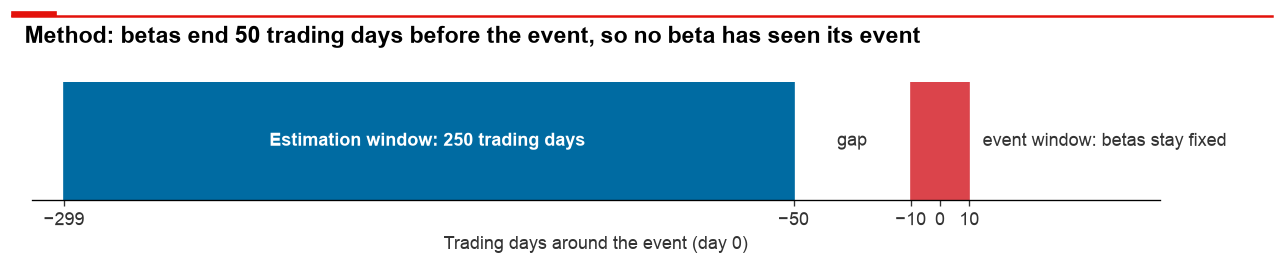

In [49]:
GAP_DAYS = 50  # trading days, as in Krüger (2015)
BASE_WINDOW = 250  # trading days, as in Krüger (2015)
# All in trading days around day 0
ESTIMATION_END = -GAP_DAYS
ESTIMATION_START = ESTIMATION_END - BASE_WINDOW + 1
EVENT_START, EVENT_END = -10, 10
WINDOW_LENGTH = EVENT_END - EVENT_START + 1  # 21 trading days

fig, ax = plt.subplots(figsize=(10.5, 2.1))
ax.axvspan(ESTIMATION_START, ESTIMATION_END, color=BLUE)
ax.axvspan(EVENT_START, EVENT_END, color=LIGHT_RED)
annotate(ax, "Estimation window: 250 trading days", (-175, 0.5), offset=(0, 0),
         color="white", fontweight="bold")
annotate(ax, "gap", (-30, 0.5), offset=(0, 0))
annotate(ax, "event window: betas stay fixed", (EVENT_END, 0.5), offset=(8, 0))

ax.set_xlim(-310, 75)  # room for the label
ax.set_ylim(0, 1)
ax.set_yticks([])
ax.set_xticks([ESTIMATION_START, ESTIMATION_END, EVENT_START, 0, EVENT_END])
ax.set_xlabel("Trading days around the event (day 0)")
ax.grid(False)
show("Method: betas end 50 trading days before the event, so no beta has seen its event")

Day 0 is the first trading day of the bank's region on or after the Sigwatch date. All windows count the trading days of that region.

In [50]:
trading_days = {}
for region in REGION_ORDER:
    trading_days[region] = holidays.index[~holidays[region]]


def first_trading_day(dates, calendar):
    '''Move each date to the first trading day on or after it.'''
    return calendar[calendar.searchsorted(dates)]


events["day_0"] = pd.NaT
for region, calendar in trading_days.items():
    is_region = event_region == region
    region_dates = events.loc[is_region, "date"]
    events.loc[is_region, "day_0"] = first_trading_day(region_dates, calendar)

moved = (events["day_0"] != events["date"]).sum()
same_bank_day = events.duplicated(["bank", "day_0"]).sum()
print(f"Events moved to the next trading day: {moved}")
print(f"Events sharing bank and day 0 after the move: {same_bank_day}")

Events moved to the next trading day: 27
Events sharing bank and day 0 after the move: 1


### 4.2 One rolling regression per bank
We run each model with windows of 120, 250 and 500 trading days: 384 rolling regressions, for 64 banks, two models and three windows. A window needs at least 80% valid returns, our rule of 200 returns in 250 days. Besides alpha and betas we keep the residual volatility for the BMP test of Task #6.

In [51]:
WINDOWS = [120, BASE_WINDOW, 500]  # trading days in an estimation window
MIN_VALID_SHARE = 0.8  # 200 returns of 250
MODEL_FACTORS = ["Mkt-RF", "SMB", "HML", "RMW", "CMA", "WML"]
BETA_MODELS = {"market": ["market"], "factors": MODEL_FACTORS}
BETA_NAMES = {"market": "Market model", "factors": "Five factors + momentum"}

def model_data(bank, model):
    '''Return the dependent variable and the factors of one bank and model.'''
    region = bank_region[bank]
    region_factors = factors_north_america if region == "US" else factors_europe
    factors = region_factors.loc[trading_days[region]]
    y = usd_returns.loc[trading_days[region], bank]
    if model == "factors":
        y = y - factors["RF"]  # excess return, as in Fama and French
    return y, factors[BETA_MODELS[model]]

def rolling_estimates(bank, model, window):
    '''Run a rolling regression, with one row per last day of the window.'''
    y, factors = model_data(bank, model)
    min_valid = int(window * MIN_VALID_SHARE)
    # missing="drop": a gap in the returns does not end a window
    fit = RollingOLS(y, sm.add_constant(factors), window=window,
                     min_nobs=min_valid, missing="drop").fit()

    estimates = fit.params.rename(columns={"const": "alpha"})
    estimates["sigma"] = np.sqrt(fit.mse_resid)
    estimates["r2"] = fit.rsquared
    estimates["nobs"] = fit.nobs
    return estimates

rolling = {}
for model in BETA_MODELS:
    for window in WINDOWS:
        rolling[model, window] = {bank: rolling_estimates(bank, model, window)
                                  for bank in event_banks}

print(f"Rolling regressions: {len(rolling) * len(event_banks)}")

Rolling regressions: 384


In [52]:
def event_estimates(model, window):
    '''Read each event's estimates from the row of day t after a shift of 50 days: the window ending on t-50.'''
    tables = []
    for bank, group in events.groupby("bank"):
        shifted = rolling[model, window][bank].shift(GAP_DAYS)
        table = shifted.reindex(group["day_0"])
        table.index = group.index
        tables.append(table)
    return pd.concat(tables).sort_index()


estimates = {}
for model, window in rolling:
    estimates[model, window] = event_estimates(model, window)

### 4.3 The timing safeguard
For 20 random events we run a direct regression on exactly the days of the estimation window, and compare it with the shifted rolling estimates, for both models and all three windows. Any difference stops the notebook. A check that cannot fail proves nothing, so it must also catch a window that ends one day too late.

In [53]:
CHECKED_EVENTS = 20  # events in the timing check


def window_days(event, window, gap=GAP_DAYS):
    '''List the trading days of an event's estimation window.'''
    calendar = trading_days[bank_region[event["bank"]]]
    day = calendar.get_loc(event["day_0"])
    last = day - gap
    # The last day of the window is included
    return calendar[last - window + 1:last + 1]


def direct_estimates(event, model, window, gap=GAP_DAYS):
    '''Estimate alpha and betas of one event by a direct regression.'''
    days = window_days(event, window, gap)
    y, factors = model_data(event["bank"], model)
    is_valid = y.loc[days].notna()
    valid_days = days[is_valid]
    return ols(y.loc[valid_days], factors.loc[valid_days]).params

def timing_failures(checked_events, gap=GAP_DAYS):
    '''Count the comparisons where direct and rolling estimates differ.'''
    failures = 0
    for index, event in checked_events.iterrows():
        for (model, window), table in estimates.items():
            columns = ["alpha", *BETA_MODELS[model]]
            rolling_values = table.loc[index, columns].values.astype(float)
            direct_values = direct_estimates(event, model, window, gap)
            failures += not np.allclose(direct_values, rolling_values)
    return failures

In [54]:
# Only events with estimates in both models and all windows
all_estimated = pd.concat([table["alpha"] for table in estimates.values()],
                          axis=1).notna().all(axis=1)
checked_events = events[all_estimated].sample(CHECKED_EVENTS, random_state=SEED)

failures = timing_failures(checked_events)
timing_checks = CHECKED_EVENTS * len(estimates)
if failures > 0:
    raise ValueError(f"Beta timing is wrong in {failures} comparisons")
print(f"Direct and rolling estimates equal: {timing_checks} of "
      f"{timing_checks}")

# Check of the check: a window ending on t-49 must be caught
caught = timing_failures(checked_events, gap=GAP_DAYS - 1)
print(f"A window one day too late is caught: {caught} of {timing_checks}")
if caught < timing_checks:
    raise ValueError("The timing check missed a window one day too late")

Direct and rolling estimates equal: 120 of 120
A window one day too late is caught: 120 of 120


**Comments – 4.3**
* **The timing is right:** all 120 comparisons (20 events, two models, three windows) match, and the check catches a window one day too late in all 120. So no beta has seen its event, and every number of Tasks #5 and #6 rests on this.

### 4.4 Which events have estimates?
A bank listed late has no estimation window for its early events, and longer windows lose more.

In [55]:
rows = []
for window in WINDOWS:
    table = estimates["market", window]
    rows.append({"window": window,
                 "minimum returns": int(window * MIN_VALID_SHARE),
                 "events with betas": table["alpha"].notna().sum(),
                 "events without": table["alpha"].isna().sum()})

coverage = pd.DataFrame(rows).set_index("window")
market_estimates = estimates["market", BASE_WINDOW]
factor_estimates = estimates["factors", BASE_WINDOW]
lost_events = events.loc[market_estimates["alpha"].isna(), "bank"]
print(lost_events.value_counts().to_string())
coverage

bank
ABN AMRO BANK      43
NIBC HOLDING       16
BANKIA              9
UNICAJA BANCO       6
LIBERBANK           4
METRO BANK          3
VIRGIN MONEY UK     2


,minimum returns,events with betas,events without
window,,,
120,96,2559,72
250,200,2548,83
500,400,2540,91


Our rules also ask for three flags on the base window: other events of the same bank inside the estimation window, a daily move above 50%, and the share of zero returns.

In [56]:
LARGE_DAILY_MOVE = 0.5  # a daily move above 50%, up or down
# In local currency, because in dollars a stale price still moves
is_zero_return = (local_trading == 0).astype(float)
is_zero_return = is_zero_return.where(local_trading.notna())


def window_statistic(daily_values, statistic):
    '''Compute a statistic over the estimation window of every event.'''
    values = pd.Series(index=events.index, dtype=float)
    for bank, group in events.groupby("bank"):
        calendar = trading_days[bank_region[bank]]
        windows = daily_values.loc[calendar, bank].rolling(BASE_WINDOW,
                                                           min_periods=1)
        shifted = windows.agg(statistic).shift(GAP_DAYS)
        values[group.index] = shifted.reindex(group["day_0"]).values
    return values

def other_events_in_window(events):
    '''Count the other events of the same bank in each estimation window.'''
    counts = pd.Series(index=events.index, dtype=int)
    for bank, group in events.groupby("bank"):
        calendar = trading_days[bank_region[bank]]
        days = calendar.get_indexer(group["day_0"])
        ordered_days = np.sort(days)
        # First and last event of the bank inside each estimation window
        first = np.searchsorted(ordered_days, days - GAP_DAYS - BASE_WINDOW + 1)
        last = np.searchsorted(ordered_days, days - GAP_DAYS, side="right")
        counts[group.index] = last - first
    return counts


events["others_in_window"] = other_events_in_window(events)
events["largest_move"] = window_statistic(usd_returns.abs(), "max")
events["zero_share"] = window_statistic(is_zero_return, "mean")

In [57]:
has_betas = market_estimates["alpha"].notna()
usable = events[has_betas]
flagged_moves = usable[usable["largest_move"] > LARGE_DAILY_MOVE]

print(f"Events with betas: {len(usable):,}")
share_with_others = (usable["others_in_window"] > 0).mean()
print(f"Other events in the window: {share_with_others:.0%}, "
      f"median {usable['others_in_window'].median():.0f}")
print(f"Daily move above 50% in the window: {len(flagged_moves)}")
print(flagged_moves["bank"].value_counts().to_string())
print(f"Zero returns, median: {usable['zero_share'].median():.1%}")
print(f"Zero returns, largest: {usable['zero_share'].max():.1%}")
bank_zero_share = usable.groupby("bank")["zero_share"].mean()
print(bank_zero_share.nlargest(3).map("{:.3f}".format).to_string())

Events with betas: 2,548
Other events in the window: 95%, median 12
Daily move above 50% in the window: 4
bank
BANKIA                3
PERMANENT TSB GHG.    1
Zero returns, median: 0.8%
Zero returns, largest: 20.0%
bank
BANCA MONTE DEI PASCHI    0.120
AIB GROUP                 0.117
VAN LANSCHOT KEMPEN       0.105


What does one extreme day do to a beta? For the flagged events we rerun the regression without the days above 50%.

In [58]:
def beta_without_large_days(event):
    '''Estimate the market beta without the days above the large move.'''
    days = window_days(event, BASE_WINDOW)
    y, factors = model_data(event["bank"], "market")
    y = y.loc[days]
    keep = y.notna() & (y.abs() <= LARGE_DAILY_MOVE)
    return ols(y[keep], factors.loc[days][keep]).params[1]


flagged_betas = pd.DataFrame({
    "bank": flagged_moves["bank"],
    "day_0": flagged_moves["day_0"],
    "largest_move": flagged_moves["largest_move"],
    "with": market_estimates.loc[flagged_moves.index, "market"],
})
flagged_betas["without"] = [beta_without_large_days(event)
                            for index, event in flagged_moves.iterrows()]
beta_gap = flagged_betas["with"] - flagged_betas["without"]
print(f"Largest change of a beta: {beta_gap.abs().max():.2f}")
print(f"Median change of a beta: {beta_gap.abs().median():.2f}")
print(flagged_betas[["bank", "with", "without"]].to_string(index=False, float_format="{:.2f}".format))

Largest change of a beta: 0.82
Median change of a beta: 0.73
              bank  with  without
PERMANENT TSB GHG.  1.61     1.87
            BANKIA  1.72     1.01
            BANKIA  1.83     1.09
            BANKIA  2.01     1.18


**Comments – 4.4**
* **Late listings cost 83 events at 250 days,** led by ABN AMRO (43), NIBC (16) and Bankia (9). The window hardly matters, with 2,559 events at 120 days and 2,540 at 500.
* **We cannot avoid other campaigns:** 95% of events have another event of the same bank in their window, with a median of 12, so dropping them would leave almost nothing.
* **Four events have a daily move above 50%:** without those days Bankia's beta falls from about 1.7 to 2.0 to about 1.0 to 1.2. We keep the estimates, as winsorising limits their CARs. Illiquidity is no problem: the median event has 0.8% zero returns in its window.

### 4.5 Did bank risk change?
The market beta of the UK event banks through time, with the 250 day window, where the cliffs are sharpest. Each date shows the window that ends there. The table gives all regions.

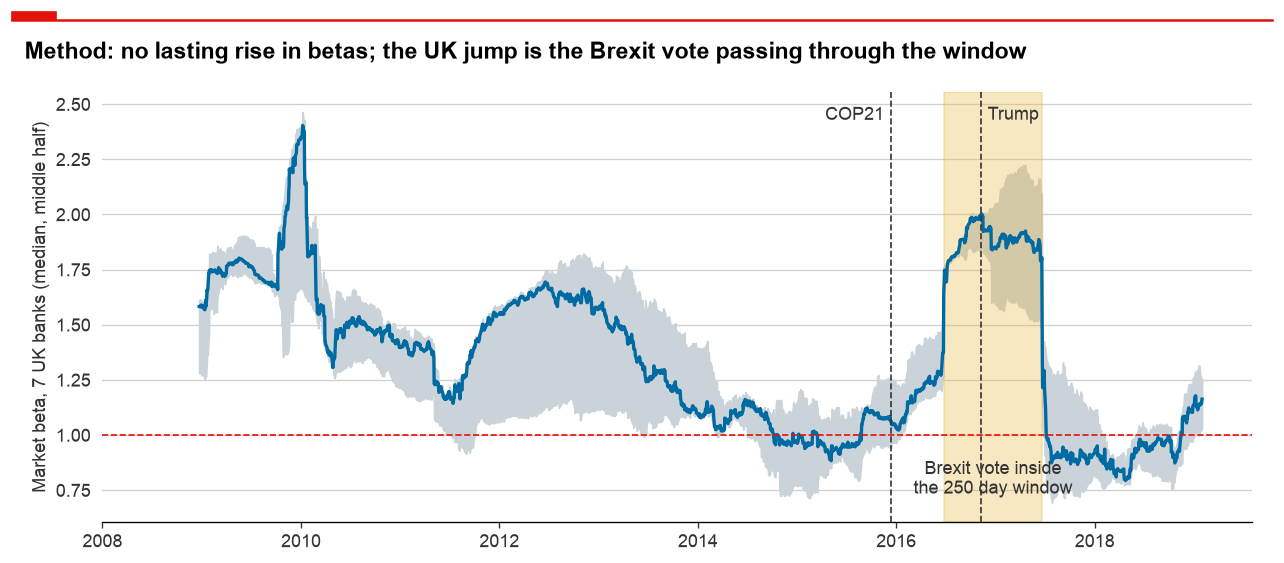

In [59]:
def region_betas(region):
    '''Collect the rolling market betas of a region's event banks.'''
    banks = region_event_banks(region)
    tables = rolling["market", BASE_WINDOW]
    return pd.DataFrame({bank: tables[bank]["market"] for bank in banks})


uk_betas = region_betas("UK")
uk_calendar = trading_days["UK"]
vote_leaves = uk_calendar[uk_calendar.searchsorted(BREXIT) + BASE_WINDOW + 1]

fig, ax = plt.subplots(figsize=(10.5, 4.5))
ax.fill_between(uk_betas.index, uk_betas.quantile(0.25, axis=1), uk_betas.quantile(0.75, axis=1), color=LIGHT_GREY)
ax.plot(uk_betas.median(axis=1), color=BLUE, lw=2)
ax.axhline(1, color=ECONOMIST_RED, ls="--", lw=1)
ax.axvspan(BREXIT, vote_leaves, color=YELLOW, alpha=0.3)
annotate(ax, "Brexit vote inside\nthe 250 day window", (BREXIT + (vote_leaves - BREXIT) / 2, 0.8), offset=(0, 0))
for date, label, shift in [(COP21, "COP21", -4), (TRUMP, "Trump", 4)]:
    ax.axvline(date, color=DARK, ls="--", lw=1)
    annotate(ax, label, (date, 2.45), offset=(shift, 0))
ax.set_xticks(YEAR_TICKS, YEAR_TICKS.year)
ax.set_ylabel("Market beta, 7 UK banks (median, middle half)")
show("Method: no lasting rise in betas; the UK jump is the Brexit vote passing through the window")

In [60]:
rows = []
for region in REGION_ORDER:
    median = region_betas(region).median(axis=1)
    rows.append({year: median.loc[year].mean()
                 for year in ["2015", "2017", "2018"]})

beta_change = pd.DataFrame(rows, index=REGION_ORDER)
beta_change.style.format("{:.2f}")

,2015,2017,2018
US,1.11,1.53,1.14
UK,1.00,1.37,0.93
Euro area,1.30,1.50,1.06
Sweden,0.87,1.17,0.99


The UK cliffs fit the two trading days of the Brexit vote, 24 and 27 June 2016, entering the window and leaving it 250 trading days later.

In [61]:
def vote_position(calendar):
    '''Find the first trading day of a region after the Brexit vote.'''
    return calendar.searchsorted(BREXIT)  # Sweden was closed on 24 June


uk_beta = region_betas("UK").median(axis=1)
uk_days = trading_days["UK"]
vote_day = vote_position(uk_days)
last_with_vote = vote_day + BASE_WINDOW - 1  # the vote is the first day of this window
print(f"UK median beta: {uk_beta.loc[uk_days[vote_day - 1]]:.2f} before the vote, "
      f"{uk_beta.loc[uk_days[last_with_vote]]:.2f} in the last window with it, "
      f"{uk_beta.loc[uk_days[last_with_vote + 2]]:.2f} once both days have left")

UK median beta: 1.37 before the vote, 1.80 in the last window with it, 1.32 once both days have left


In [62]:
in_brexit_window = pd.Series(False, index=events.index)
for region in EUROPEAN_REGIONS:
    calendar = trading_days[region]
    vote_day = vote_position(calendar)
    is_region = event_region == region
    days = calendar.get_indexer(events.loc[is_region, "day_0"])
    # The vote lies in the window if it starts before and ends after the vote
    in_brexit_window[is_region] = (days - GAP_DAYS >= vote_day) & (
        days + ESTIMATION_START <= vote_day)

events["brexit_in_window"] = in_brexit_window
print("Events with the vote in their window:", in_brexit_window.sum())
print(events.loc[in_brexit_window, "country_group"].value_counts().to_string())

Events with the vote in their window: 301
country_group
Euro area    191
UK            76
Sweden        34


**Comments – 4.5**
* **No lasting rise:** from 2015 to 2018 the median beta moves from 1.11 to 1.14 in the US, 1.00 to 0.93 in the UK and 0.87 to 0.99 in Sweden, and falls from 1.30 to 1.06 in the euro area.
* **The UK cliff is two days:** when they leave the window the beta falls from 1.80 to 1.32, about its level before the vote (1.37). Our 50% flag misses this, so `brexit_in_window` marks the 301 events with the vote in their window (191 euro area, 76 UK, 34 Sweden), and 6.5 reruns without them.

### 4.6 Market model against five factors plus momentum
If the simple model were enough, the extra factors would add little fit.

Correlation of the betas: 0.51
Mean gap, factors minus market: -0.36
Median residual volatility, market model: 1.29% a day
Median residual volatility, factors: 1.09% a day


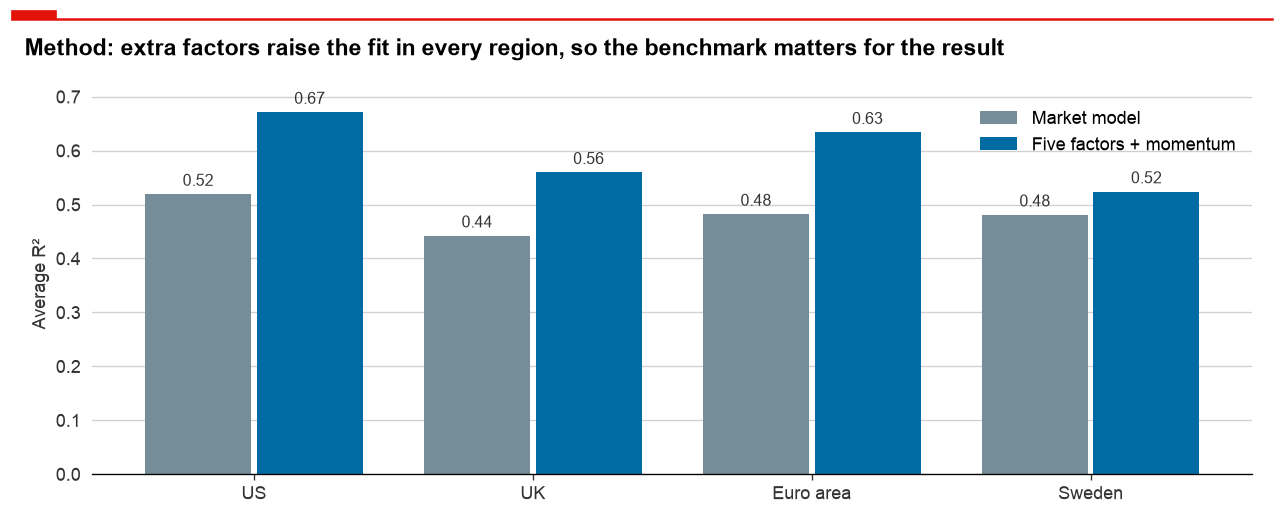

In [63]:
market_table = market_estimates[has_betas]
factor_table = factor_estimates[has_betas]


BAR_SHIFT = 0.2  # two bars side by side around each tick
BAR_WIDTH = 0.38


def plot_model_fit(ax, market_table, factor_table):
    '''Show the average fit of the two models per region.'''
    fit = pd.DataFrame({"Market model": market_table["r2"],
                        "Five factors + momentum": factor_table["r2"]})
    means = fit.groupby(event_region[has_betas]).mean().loc[REGION_ORDER]
    positions = np.arange(len(means))

    for shift, column, color in [(-BAR_SHIFT, "Market model", GREY),
                                 (BAR_SHIFT, "Five factors + momentum",
                                  BLUE)]:
        bars = ax.bar(positions + shift, means[column], width=BAR_WIDTH,
                      color=color, label=column)
        ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=9.5, color=DARK)

    ax.set_xticks(positions, means.index)
    ax.set_ylabel("Average R²")
    ax.legend(loc="upper right")

beta_gap_models = factor_table["Mkt-RF"] - market_table["market"]
beta_correlation = factor_table["Mkt-RF"].corr(market_table["market"])

print(f"Correlation of the betas: {beta_correlation:.2f}")
print(f"Mean gap, factors minus market: {beta_gap_models.mean():+.2f}")
print(f"Median residual volatility, market model: "
      f"{market_table['sigma'].median():.2%} a day")
print(f"Median residual volatility, factors: "
      f"{factor_table['sigma'].median():.2%} a day")

fig, ax = plt.subplots(figsize=(10.5, 4.12))
plot_model_fit(ax, market_table, factor_table)
show("Method: extra factors raise the fit in every region, so the benchmark matters for the result")

The five extra loadings show what the market model leaves out, averaged per bank because events of one bank share much of their window.

In [64]:
LOADINGS = ["SMB", "HML", "RMW", "CMA", "WML"]
is_us_event = event_region[has_betas] == "US"


def mean_loadings(table):
    '''Average the loadings per bank, then across banks.'''
    return table.groupby(events.loc[table.index, "bank"])[LOADINGS].mean().mean()


loadings = pd.DataFrame({"US": mean_loadings(factor_table[is_us_event]),
                         "Europe": mean_loadings(factor_table[~is_us_event])})
print(loadings.map("{:.2f}".format).to_string())

        US Europe
SMB   0.16  -0.06
HML   1.39   0.82
RMW  -0.40  -1.51
CMA  -0.74  -0.33
WML   0.13  -0.05


**Comments – 4.6**
* **The market beta itself changes:** the two betas correlate at only 0.51, and the factor model's is 0.36 lower on average. Daily residual volatility falls from 1.29% to 1.09%.
* **Banks are not just market bets:** they load on value (HML 1.39 in the US, 0.82 in Europe) and negatively on profitability (RMW −0.40 and −1.51) and investment (CMA −0.74 and −0.33). Size and momentum matter little.

### 4.7 Does the window change the picture?
We report all three windows and choose none by fit. The window moves single betas by 0.15 to 0.18 on average (correlation with the 250 day window 0.86 at 120 days, 0.79 at 500), and short windows are noisier (standard deviation 0.40, 0.38 and 0.34). 250 days stays our base, as in Krüger (2015), and 6.5 reruns the main test on the other two.

In [65]:
base_beta = market_estimates["market"]
print(f"250 days: standard deviation of the betas {base_beta.std():.2f}")
for window in [120, 500]:
    other = estimates["market", window]["market"]
    both = base_beta.notna() & other.notna()
    print(f"{window} days: correlation with 250 days {base_beta[both].corr(other[both]):.2f}, "
          f"mean absolute gap {(other[both] - base_beta[both]).abs().mean():.2f}, "
          f"standard deviation {other[both].std():.2f}")

250 days: standard deviation of the betas 0.38
120 days: correlation with 250 days 0.86, mean absolute gap 0.15, standard deviation 0.40
500 days: correlation with 250 days 0.79, mean absolute gap 0.18, standard deviation 0.34


## Task #5 – Abnormal returns and CARs
The abnormal return is what a bank earned beyond its normal return, and the cumulative abnormal return (CAR) adds these up over a window around the event:

$$AR_{i,t} = r_{i,t} - \hat{r}_{i,t}, \qquad CAR_i = \sum_{t=t_1}^{t_2} AR_{i,t}$$

For the market model the prediction is $\hat{\alpha}_i + \hat{\beta}_i r_{M,t}$, for the factor model the same on excess returns with all six factors.

### 5.1 Merge events and returns
Our key is the bank and day 0. We count every step and give a reason for each event we drop.

**Two events on the same bank and day.** HSBC has an event on 30 May 2011, a UK bank holiday, and one on 31 May, so both have the same day 0 and the same 21 return days. Both are negative, so we count this window once, with the rule of Day 1: the worst sentiment and the highest prominence, and both NGOs in `n_ngos`.

In [66]:
same_window = events[events.duplicated(["bank", "day_0"], keep=False)]
# Both NGOs count, which merge_rows alone would lose
ngos_per_window = events.groupby(["bank", "day_0"])["n_ngos"].transform("sum")

unique_events = merge_rows(events, ["bank", "day_0"]).sort_index()
unique_events["n_ngos"] = ngos_per_window.loc[unique_events.index]
unique_events = unique_events.reset_index(names="event_id")

shown = ["bank", "date", "day_0", "sentiment", "prominence", "ngo"]
print(f"Events: {len(events):,} to {len(unique_events):,}")
same_window[shown]

Events: 2,631 to 2,630


,bank,date,day_0,sentiment,prominence,ngo
225,HSBC HOLDINGS,2011-05-30,2011-05-31,-2,4,UK Uncut
227,HSBC HOLDINGS,2011-05-31,2011-05-31,-1,3,IDEC Instituto Brasileiro de Defesa do Consumidor


In [67]:
day_zero_rows = panel[["bank", "date"]].rename(columns={"date": "day_0"})

# An event without a row on day 0 has no return that day: its bank was not listed yet
merged_events = unique_events.merge(day_zero_rows, on=["bank", "day_0"], how="left", indicator=True, validate="many_to_one")

has_day_zero = merged_events["_merge"] == "both"
event_ids = merged_events["event_id"]
has_market_betas = market_estimates["alpha"].reindex(event_ids).notna().values
has_factor_betas = factor_estimates["alpha"].reindex(event_ids).notna().values
# Both models must exist, so that they use the same events
has_estimates = has_market_betas & has_factor_betas

### 5.2 The event window
For every event we list the 21 trading days from −10 to +10 of its region, and read returns and factors from the panel. Every day of the window must have a return.

In [68]:
PANEL_COLUMNS = ["bank", "date", "usd_return", "excess_return",
                 *MODEL_FACTORS, "market"]


def window_rows(region_events, calendar):
    '''List the 21 trading days around each event of one region.'''
    positions = calendar.get_indexer(region_events["day_0"])
    tables = []
    for day in range(EVENT_START, EVENT_END + 1):
        tables.append(pd.DataFrame({
            "event_id": region_events["event_id"].values,
            "bank": region_events["bank"].values,
            "day": day,
            "date": calendar[positions + day],
        }))
    return pd.concat(tables, ignore_index=True)

estimated_events = merged_events[has_estimates]
estimated_region = estimated_events["bank"].map(bank_region)

tables = []
for region, calendar in trading_days.items():
    region_events = estimated_events[estimated_region == region]
    tables.append(window_rows(region_events, calendar))

event_days = pd.concat(tables, ignore_index=True)
event_days = event_days.merge(panel[PANEL_COLUMNS], on=["bank", "date"],
                              how="left", indicator=True,
                              validate="many_to_one")

# A complete window has a return on all 21 trading days of its region
returns_in_window = event_days["usd_return"].notna().groupby(
    event_days["event_id"]).sum()
incomplete = (returns_in_window < WINDOW_LENGTH).sum()

print(f"Event days: {len(event_days):,}")
print(f"Events with an incomplete window: {incomplete}")

Event days: 53,487
Events with an incomplete window: 0


In [69]:
has_full_window = event_ids.map(returns_in_window) == WINDOW_LENGTH
# The first condition that holds gives the reason
merged_events["reason"] = np.select(
    [~has_day_zero, ~has_estimates, ~has_full_window],
    ["not listed yet on day 0", "too little history for betas",
     "incomplete event window"],
    default="kept",
)
merged_events["listed"] = merged_events["bank"].map(prices.apply(pd.Series.first_valid_index))
print(merged_events["reason"].value_counts().to_string())

dropped_columns = ["bank", "date", "sign", "listed", "reason"]
dropped = merged_events.loc[merged_events["reason"] != "kept", dropped_columns].sort_values(["bank", "date"])
kept_events = merged_events[merged_events["reason"] == "kept"]
lost_banks = sorted(set(event_banks) - set(kept_events["bank"]))
print(f"Banks with events kept: {kept_events['bank'].nunique()}, lost entirely: {lost_banks}")

reason
kept                            2547
not listed yet on day 0           67
too little history for betas      16
Banks with events kept: 60, lost entirely: ['METRO BANK', 'NIBC HOLDING', 'UNICAJA BANCO', 'VIRGIN MONEY UK']


**Comments – 5.1 and 5.2**
* **No event is lost by accident:** 2,631 events become 2,547, on 60 of the 64 banks: Metro Bank, NIBC, Unicaja and Virgin Money lose all their events to late listing. Of the 84 we lose, 67 fall before the bank was listed, 16 have too little history for betas, and one is the HSBC event we merge. `dropped` names each one.
* **The merge is clean:** `validate` confirms one panel row per bank and day. No window is incomplete: every event with betas has a return on all 21 days.

### 5.3 Abnormal returns
Computed for both models and all three estimation windows, with the alpha and betas of each event fixed over the window.

In [70]:
def abnormal_returns(event_days, model, window):
    '''Compute the abnormal return of every event day.'''
    columns = ["alpha", *BETA_MODELS[model]]
    # One event sits on 21 rows, so we use positions, not labels
    parameters = estimates[model, window].loc[event_days["event_id"], columns]
    alphas = parameters["alpha"].values
    betas = parameters[BETA_MODELS[model]].values
    factors = event_days[BETA_MODELS[model]].values

    predicted = alphas + (betas * factors).sum(axis=1)
    # The market model uses raw returns, the factor model excess returns
    return_column = "usd_return" if model == "market" else "excess_return"
    return event_days[return_column].values - predicted

kept_days = event_days[event_days["event_id"].isin(kept_events["event_id"])]
kept_days = kept_days.drop(columns="_merge").reset_index(drop=True)

for model, window in estimates:
    kept_days[f"ar_{model}_{window}"] = abnormal_returns(kept_days, model,
                                                         window)

AR_MARKET = f"ar_market_{BASE_WINDOW}"
AR_FACTORS = f"ar_factors_{BASE_WINDOW}"
print(f"Event days with abnormal returns: {len(kept_days):,}")
print(f"Mean AR, market model: {kept_days[AR_MARKET].mean():+.3%} a day")
print(f"Mean AR, factors: {kept_days[AR_FACTORS].mean():+.3%} a day")

Event days with abnormal returns: 53,487
Mean AR, market model: -0.020% a day
Mean AR, factors: -0.010% a day


### 5.4 CARs over the four windows
Krüger (2015) reports $[-5, +5]$ and $[-10, +10]$, the second being the baseline of the slide and of our tests. $[-10, -1]$ catches news before the Sigwatch date, a leak or a late record, and $[0, +10]$ the reaction from that date on. We check the arithmetic with one event by hand: a direct regression and a plain loop over its days.

In [71]:
CAR_WINDOWS = {
    "[-5, +5]": (-5, 5),
    "[-10, +10]": (-10, 10),
    "[-10, -1]": (-10, -1),
    "[0, +10]": (0, 10),
}


def event_cars(kept_days, ar_column):
    '''Sum the abnormal returns of every event over the four windows.'''
    cars = {}
    for name, (first, last) in CAR_WINDOWS.items():
        in_window = kept_days["day"].between(first, last)
        days_in_window = kept_days[in_window]
        # min_count: a gap gives a missing CAR, not a smaller sum
        cars[name] = days_in_window.groupby("event_id")[ar_column].sum(
            min_count=last - first + 1)
    return pd.DataFrame(cars)

def car_by_hand(event, model):
    '''Compute the 21 day CAR of one event with a direct regression.'''
    parameters = direct_estimates(event, model, BASE_WINDOW)
    y, factors = model_data(event["bank"], model)
    calendar = trading_days[bank_region[event["bank"]]]
    day = calendar.get_loc(event["day_0"])

    car = 0
    for date in calendar[day + EVENT_START:day + EVENT_END + 1]:
        predicted = parameters[0] + (parameters[1:] * factors.loc[date]).sum()
        car += y.loc[date] - predicted
    return car

all_cars = {}
for model, window in estimates:
    all_cars[model, window] = event_cars(kept_days, f"ar_{model}_{window}")

market_cars = all_cars["market", BASE_WINDOW]
factor_cars = all_cars["factors", BASE_WINDOW]

# Check: the pre and post windows add up to the baseline
pre_and_post = market_cars["[-10, -1]"] + market_cars["[0, +10]"]
assert np.allclose(pre_and_post, market_cars["[-10, +10]"])

# Check: the same CAR by hand, for a few events
hand_events = kept_events.sample(5, random_state=SEED)
for model, table in [("market", market_cars), ("factors", factor_cars)]:
    by_hand = [car_by_hand(event, model)
               for index, event in hand_events.iterrows()]
    from_table = table.loc[hand_events["event_id"], "[-10, +10]"]
    assert np.allclose(by_hand, from_table)

The table for Task #6 has one row per event, with both models, the volatility for the BMP test and every flag. New flag: `overlap` marks a window that overlaps the previous one of the same bank (less than 21 trading days apart).

In [72]:
def trading_days_since_last(group):
    '''Count the trading days since the previous event of the same bank.'''
    calendar = trading_days[bank_region[group["bank"].iloc[0]]]
    days = pd.Series(calendar.get_indexer(group["day_0"]), index=group.index)
    return days.sort_values().diff()

car_table = kept_events.set_index("event_id").drop(columns=["_merge", "reason"])
car_table["region"] = car_table["bank"].map(bank_region)

for name in CAR_WINDOWS:
    car_table[f"market {name}"] = market_cars[name]
    car_table[f"factors {name}"] = factor_cars[name]

car_table["sigma_market"] = market_estimates["sigma"]
car_table["sigma_factors"] = factor_estimates["sigma"]

gaps = [trading_days_since_last(group)
        for bank, group in car_table.groupby("bank")]
car_table["days_since_last"] = pd.concat(gaps)
# Closer than 21 days two windows share returns. A bank's first event has
# no gap, so it counts as no overlap
car_table["overlap"] = car_table["days_since_last"] < WINDOW_LENGTH


In [73]:
FLAGS = ["conflict_5_days", "brexit_in_window", "overlap"]

print(f"CAR table: {len(car_table):,} events, {car_table.shape[1]} columns")
print(car_table[FLAGS].sum().to_string())
print(f"Share of events overlapping: {car_table['overlap'].mean():.1%}")
print(f"Daily move above 50% in the window: "
      f"{(car_table['largest_move'] > LARGE_DAILY_MOVE).sum()}")
print(car_table["sign"].value_counts().to_string())

CAR table: 2,547 events, 35 columns
conflict_5_days      199
brexit_in_window     297
overlap             1560
Share of events overlapping: 61.2%
Daily move above 50% in the window: 4
sign
negative    2076
positive     337
neutral      134


**Comments – 5.3 and 5.4**
* **Small daily means add up:** −0.020% a day in the market model and −0.010% with the factors, or −0.43% over 21 days in the market model. The table holds 2,547 events (2,076 negative, 337 positive, 134 neutral).
* **Windows often overlap:** 1,560 events (61.2%) start less than 21 trading days after the previous event of the same bank, so one return can enter two CARs. Clustering by date does not remove this, so we read the intervals of Task #6 with care.

### 5.5 Extreme abnormal returns
A few days can move an average, so we list them, and compare the mean with the median and with the mean without the ten largest CARs.

In [74]:
BASE_CAR = "market [-10, +10]"  # our baseline
BASE_FACTOR_CAR = "factors [-10, +10]"
TOP_DAYS = 12  # days in the list
TOP_CARS = 10  # events left out of the mean

largest_index = kept_days[AR_MARKET].abs().nlargest(TOP_DAYS).index
largest_days = kept_days.loc[largest_index, ["bank", "date", "day", "usd_return", AR_MARKET]]
print(largest_days.to_string(index=False, float_format="{:+.3f}".format))
largest_car = car_table.loc[car_table[BASE_CAR].abs().idxmax()]
print(f"Largest CAR: {largest_car['bank']}, {largest_car['day_0']:%b %Y}, {largest_car[BASE_CAR]:+.1%}")

rows = []
for sign in SIGNS:
    cars = car_table.loc[car_table["sign"] == sign, BASE_CAR]
    largest = cars.abs().nlargest(TOP_CARS).index
    rows.append({
        "events": len(cars),
        "mean": cars.mean(),
        "median": cars.median(),
        "mean without the 10 largest": cars.drop(largest).mean(),
        "standard deviation": cars.std(),
    })

car_summary = pd.DataFrame(rows, index=SIGNS)
car_summary.style.format({"events": "{:,}", "mean": "{:+.2%}",
                          "median": "{:+.2%}",
                          "mean without the 10 largest": "{:+.2%}",
                          "standard deviation": "{:.2%}"})

                  bank       date  day  usd_return  ar_market_250
                BANKIA 2013-05-23    0      -0.512         -0.485
                BANKIA 2013-05-20   -3      -0.456         -0.459
                BANKIA 2013-05-16   -5      +0.298         +0.306
                BANKIA 2013-05-31    6      +0.279         +0.303
                BANKIA 2012-11-30    2      -0.252         -0.247
                BANKIA 2013-05-22   -1      -0.244         -0.235
                BANKIA 2013-05-21   -2      -0.208         -0.204
   SVB FINANCIAL GROUP 2018-04-27    0      +0.187         +0.187
  LLOYDS BANKING GROUP 2016-06-24   -6      -0.273         -0.178
BANCA MONTE DEI PASCHI 2016-11-29   -8      +0.179         +0.173
    STANDARD CHARTERED 2012-08-07   -2      -0.162         -0.172
    STANDARD CHARTERED 2012-08-07    4      -0.162         -0.171
Largest CAR: BANKIA, May 2013, -138.4%


,events,mean,median,mean without the 10 largest,standard deviation
negative,"2,076",-0.46%,-0.88%,-0.38%,7.72%
positive,337,-0.56%,-0.68%,-0.58%,6.07%


**Comments – 5.5**
* **Bankia dominates the extremes:** 7 of the 12 largest abnormal returns, all but one in May 2013, the month of its recapitalisation. Its CAR of −138.4% is no real loss: a CAR adds up simple returns, so over a collapse it can pass −100%. The winsorising of Task #6 limits it.
* **The mean does not hang on a few events:** −0.46% for negative events, −0.38% without the ten largest CARs. The medians are −0.88% and, for positive events, −0.68%.
* **The largest days are not campaigns:** Lloyds lost 27.3% on the Brexit vote. We have no filter for other news, so the median and the sign test of Task #6 matter.

### 5.6 The average CAR path
The average CAR, day by day. Events of one day move together, so the 95% intervals at day +10 are clustered by day 0. In grey the benchmark: bad news moved to random days of the same year, for the same banks, as the mean and 95% range of 1,000 draws.

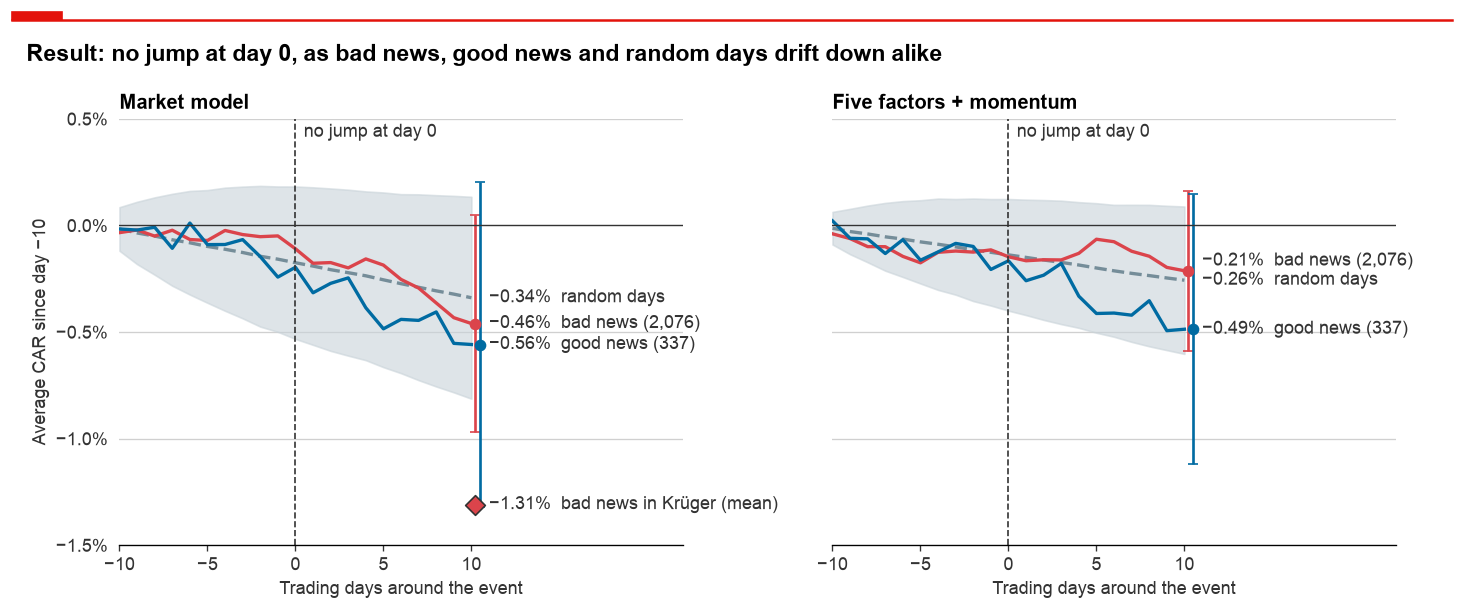

In [75]:
def clustered_mean(values, clusters):
    '''Compute a mean and its standard error, clustered by date.'''
    # statsmodels needs the clusters as numbers
    groups = pd.factorize(clusters)[0]
    # A regression on a constant alone gives the mean and its clustered error
    fit = sm.OLS(values, np.ones(len(values))).fit(
        cov_type="cluster", cov_kwds={"groups": groups})
    return fit.params[0], fit.bse[0]

def car_path(kept_days, ar_column, car_table, sign):
    '''Compute the average CAR of one sign for every day of the window.'''
    daily = kept_days.pivot(index="event_id", columns="day", values=ar_column)
    cumulative = daily.cumsum(axis=1)  # CAR from day -10 to each day

    events_of_sign = car_table[car_table["sign"] == sign]
    cumulative = cumulative.loc[events_of_sign.index]

    rows = {}
    for day in cumulative.columns:
        mean, error = clustered_mean(cumulative[day].values,
                                     events_of_sign["day_0"])
        rows[day] = {"mean": mean, "half_width": Z_95 * error}
    return pd.DataFrame(rows).T

def plot_car_path(ax, path, color, shift):
    '''Draw an average CAR path, with its 95% interval as a bar at day +10.'''
    ax.plot(path.index, path["mean"], color=color, lw=2)
    end = path.iloc[-1]
    ax.errorbar(EVENT_END + shift, end["mean"], yerr=end["half_width"], fmt="o", ms=6, capsize=3, color=color)


CAR_TICKS = np.arange(-0.015, 0.0051, 0.005)  # the same ticks on all CAR panels


def format_car_axis(ax, title):
    '''Set the lines, ticks and title of a CAR path panel.'''
    ax.axhline(0, color=DARK, lw=0.8)
    ax.axvline(0, color=DARK, ls="--", lw=1)
    ax.set_yticks(CAR_TICKS)
    ax.set_ylim(CAR_TICKS[0], CAR_TICKS[-1])
    annotate(ax, "no jump at day 0", (0, CAR_TICKS[-1]), offset=(5, -8), ha="left")
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=1))
    ax.set_xticks(range(EVENT_START, EVENT_END + 1, 5))
    ax.set_xlim(EVENT_START, EVENT_END + 12)  # room for the labels
    ax.set_xlabel("Trading days around the event")
    ax.set_title(title, fontsize=12)

paths = {}
for model, column in [("market", AR_MARKET), ("factors", AR_FACTORS)]:
    for sign in SIGNS:
        paths[model, sign] = car_path(kept_days, column, car_table, sign)

RANDOM_DRAWS = 1_000  # enough to read the tails of the random means


def cumulative_cars(bank, model):
    '''Compute the CAR from day -10 up to each event day, for every possible day 0.'''
    y, factors = model_data(bank, model)
    parameters = rolling[model, BASE_WINDOW][bank].shift(GAP_DAYS)
    table = {}
    for day in range(EVENT_START, EVENT_END + 1):
        length = day - EVENT_START + 1
        predicted = length * parameters["alpha"]
        for factor in BETA_MODELS[model]:
            predicted = predicted + parameters[factor] * factors[factor].rolling(length).sum().shift(-day)
        table[day] = y.rolling(length).sum().shift(-day) - predicted
    return table


def random_means(table, matrices, low=-np.inf, high=np.inf):
    '''Average the CARs after moving each date to a random day of its year, per draw and matrix.'''
    rng = np.random.default_rng(SEED)
    bank_columns = list(event_banks)
    columns = [bank_columns.index(bank) for bank in table["bank"]]
    date_codes, dates = pd.factorize(table["day_0"])
    means = np.zeros((RANDOM_DRAWS, len(matrices)))
    for draw in range(RANDOM_DRAWS):
        new_days = np.zeros(len(dates), dtype=int)
        for year in np.unique(dates.year):
            is_year = dates.year == year
            days_of_year = np.flatnonzero(all_days.year == year)
            new_days[is_year] = rng.choice(days_of_year, is_year.sum())
        # A closed market or a bank not yet listed gives a missing CAR
        rows = new_days[date_codes]
        for position, matrix in enumerate(matrices):
            means[draw, position] = np.nanmean(matrix[rows, columns].clip(low, high))
    return means


# One table per model and event day: possible day 0 in the rows, banks in the columns
random_day_tables = {}
for model in BETA_MODELS:
    per_bank = {bank: cumulative_cars(bank, model) for bank in event_banks}
    random_day_tables[model] = {
        day: pd.DataFrame({bank: per_bank[bank][day] for bank in event_banks})
        for day in range(EVENT_START, EVENT_END + 1)}
all_days = random_day_tables["market"][EVENT_END].index
negative_table = car_table[car_table["sign"] == "negative"]

placebo_paths = {}
for model, tables in random_day_tables.items():
    draws = random_means(negative_table, [table.values for table in tables.values()])
    placebo_paths[model] = pd.DataFrame({"mean": draws.mean(axis=0), "half_width": Z_95 * draws.std(axis=0)},
                                        index=list(tables))

counts = car_table["sign"].value_counts()
LABEL_GAP = 0.0009  # smallest vertical distance between the end labels


def label_path_ends(ax, ends):
    '''Write the end labels from low to high, moved apart where they would overlap.'''
    position = -np.inf
    for label, value in sorted(ends.items(), key=lambda item: item[1]):
        position = max(value, position + LABEL_GAP)
        annotate(ax, f"{value:+.2%}  {label}", (EVENT_END + 1, position), offset=(0, 0), ha="left")


# Krüger (2015), Tables 3 and 4: mean CAR and t statistic over [-10, +10]
KRUGER_NEGATIVE = -0.0131
KRUGER_NEGATIVE_MEDIAN = -0.0111
KRUGER_POSITIVE = -0.0047
KRUGER_NEGATIVE_T = -6.57
KRUGER_POSITIVE_T = -1.82
NEWS_NAMES = {"negative": "bad news", "positive": "good news"}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.88), sharey=True)
for ax, model in zip(axes, BETA_MODELS):
    placebo = placebo_paths[model]
    ax.fill_between(placebo.index, placebo["mean"] - placebo["half_width"], placebo["mean"] + placebo["half_width"],
                    color=LIGHT_GREY, alpha=0.6)
    ax.plot(placebo.index, placebo["mean"], color=GREY, lw=2, ls="--")
    ends = {"random days": placebo["mean"].iloc[-1]}
    for sign, shift in [("negative", 0.2), ("positive", 0.5)]:
        plot_car_path(ax, paths[model, sign], SENTIMENT_COLORS[sign], shift)
        ends[f"{NEWS_NAMES[sign]} ({counts[sign]:,})"] = paths[model, sign]["mean"].iloc[-1]
    if model == "market":  # Krüger uses the market model
        ax.scatter(EVENT_END + 0.2, KRUGER_NEGATIVE, marker="D", s=70, color=SENTIMENT_COLORS["negative"],
                   edgecolors=DARK, zorder=4)
        ends["bad news in Krüger (mean)"] = KRUGER_NEGATIVE
    label_path_ends(ax, ends)
    format_car_axis(ax, BETA_NAMES[model])
axes[0].set_ylabel("Average CAR since day −10")
show("Result: no jump at day 0, as bad news, good news and random days drift down alike")

In [76]:
negative_path = paths["market", "negative"]
print(f"Negative events, market model: {negative_path.loc[-1, 'mean']:+.2%} on day -1, "
      f"{negative_path.loc[1, 'mean']:+.2%} on day +1")
print("Half widths on day +10:", {key: f"{path.loc[EVENT_END, 'half_width']:.2%}" for key, path in paths.items()})

rows = []
for name in CAR_WINDOWS:
    for sign in SIGNS:
        table = car_table[car_table["sign"] == sign]
        for model in BETA_MODELS:
            mean, error = clustered_mean(table[f"{model} {name}"].values,
                                         table["day_0"])
            rows.append({"window": name, "sign": sign, "model": model,
                         "mean": mean, "half_width": Z_95 * error})

window_means = pd.DataFrame(rows)
excludes_zero = window_means["mean"].abs() > window_means["half_width"]

print(f"Intervals without zero: {excludes_zero.sum()} of {len(window_means)}")
print(window_means[excludes_zero].round(4).to_string(index=False))

car_gap = car_table[BASE_FACTOR_CAR] - car_table[BASE_CAR]
print(f"Correlation of the CARs: {car_table[BASE_CAR].corr(car_table[BASE_FACTOR_CAR]):.2f}")
print(f"Median absolute gap: {car_gap.abs().median():.2%}")
print(f"Volatility of the CARs, market model: {car_table[BASE_CAR].std():.2%}")
print(f"Volatility of the CARs, factors: {car_table[BASE_FACTOR_CAR].std():.2%}")

Negative events, market model: -0.05% on day -1, -0.18% on day +1
Half widths on day +10: {('market', 'negative'): '0.51%', ('market', 'positive'): '0.76%', ('factors', 'negative'): '0.37%', ('factors', 'positive'): '0.63%'}
Intervals without zero: 1 of 16
  window     sign  model    mean  half_width
[0, +10] negative market -0.0041      0.0033
Correlation of the CARs: 0.85
Median absolute gap: 2.03%
Volatility of the CARs, market model: 7.44%
Volatility of the CARs, factors: 6.62%


**Comments – 5.6**
* **Bad news drifts without a jump:** −0.05% on day −1, −0.18% on day +1, and it ends inside the range of random days in both models. Sigwatch dates can lag the news, but we see no reaction just before day 0 either.
* **Krüger's marker is his mean, a benchmark rather than a like-for-like test:** he studies other firms and years. His positive events also fall a little (−0.47%).
* **The factors halve the fall** from −0.46% to −0.21% and remove noise (CAR volatility 7.44% to 6.62%, correlation of the two 0.85), so about half of the market model's drift is exposure to other factors. The simple model changes the size, not the sign (the question of Task #4).
* **Windows add little:** one interval of 16 excludes zero, about what chance gives: negative events over $[0, +10]$, in the market model only.

## Task #6 – Do NGO campaigns matter?
Our main test takes the negative events over $[-10, +10]$ with the market model, as Krüger (2015) does. We then compare negative with positive events, split the negative events by period, issue and tone, and rerun the main test in several ways. Neutral events stay out. We chose the main test and the splits before running them, but after the descriptive results of Task #5. The tests on positive events, the clustered BMP test and the Brexit and overlap rows came later, and the factor sign test, the clustering by bank and month and the sector benchmark after a review of these results, and the diff-in-diff last. We report every test we ran.

### 6.1 Winsorised CARs
We set values beyond the 1st and 99th percentile to those percentiles. The limits come from negative and positive events together, so both groups are treated alike.

In [77]:
WINSOR_LEVELS = [0.01, 0.99]  # the 1st and 99th percentile


def winsorise(table, column):
    '''Limit a CAR to the percentiles of the signed events.'''
    signed_cars = table.loc[table["sign"] != "neutral", column]
    low, high = signed_cars.quantile(WINSOR_LEVELS)
    return table[column].clip(low, high)

# The other estimation windows are needed only for the robustness checks
for window in [120, 500]:
    car_table[f"market {window} days"] = all_cars["market", window]["[-10, +10]"]

CAR_COLUMNS = [f"{model} {name}" for model in BETA_MODELS
               for name in CAR_WINDOWS]
CAR_COLUMNS += ["market 120 days", "market 500 days"]

for column in CAR_COLUMNS:
    car_table[f"w {column}"] = winsorise(car_table, column)

MAIN_CAR = f"w {BASE_CAR}"
FACTOR_CAR = f"w {BASE_FACTOR_CAR}"

is_signed = car_table["sign"] != "neutral"
main_cars = car_table.loc[is_signed, MAIN_CAR]
raw_cars = car_table.loc[is_signed, BASE_CAR]
changed = (main_cars != raw_cars).sum()
print(f"Limits: {main_cars.min():+.1%} and {main_cars.max():+.1%}")
print(f"Signed events changed: {changed} of {len(main_cars):,}")

Limits: -17.4% and +20.8%
Signed events changed: 50 of 2,413


**Comments – 6.1**
* **The limits are −17.4% and +20.8%:** they touch only 50 of 2,413 signed events, so Bankia's −138% counts as −17.4%.
* **We cap, we do not delete:** every event keeps its place and sign, so the sign test does not change, and the raw CARs return in 6.5.

### 6.2 The main test
Four numbers, because each guards against something else:
* **The mean, with standard errors clustered by day 0.** Events on the same day move together.
* **The median.** One event cannot move it.
* **The BMP test** (Boehmer, Musumeci and Poulsen, 1991). Each CAR is divided by the bank's residual volatility in its estimation window, scaled to the 21 days, so volatile banks do not dominate: $SCAR_i = CAR_i / (\hat{\sigma}_i \sqrt{21})$. The statistic compares the mean $SCAR$ with its standard deviation across events.
* **The generalised sign test** (Cowan, 1992). Does the share of positive CARs differ from normal, the share of positive residuals in the estimation windows: $Z = (w - n\hat{p}) / \sqrt{n\hat{p}(1-\hat{p})}$.

In [78]:
def p_value(statistic):
    '''Compute the two sided p value of a normal statistic.'''
    return 2 * stats.norm.sf(abs(statistic))


def standardised_cars(table, column, sigma_column="sigma_market"):
    '''Divide each CAR by the bank's volatility over the 21 days.'''
    # sigma is a daily volatility, so a 21 day sum scales with the root of 21
    return table[column] / (table[sigma_column] * np.sqrt(WINDOW_LENGTH))


def bmp_tests(table, column, sigma_column="sigma_market"):
    '''Run the BMP test on one group of events, plain and clustered.'''
    standardised = standardised_cars(table, column, sigma_column)
    plain_error = standardised.std() / np.sqrt(len(standardised))
    statistic = standardised.mean() / plain_error
    mean, error = clustered_mean(standardised.values, table["day_0"])
    return {
        "BMP statistic": statistic,
        "p value, BMP": p_value(statistic),
        "p value, BMP clustered": p_value(mean / error),
    }

def positive_residual_share(event, model):
    '''Compute the share of positive residuals in an event's estimation window.'''
    days = window_days(event, BASE_WINDOW)
    y, factors = model_data(event["bank"], model)
    estimate = estimates[model, BASE_WINDOW].loc[event.name]  # event.name is its event_id
    columns = BETA_MODELS[model]
    predicted = (estimate["alpha"]
                 + (factors.loc[days, columns] * estimate[columns].astype(float)).sum(axis=1))
    return ((y.loc[days] - predicted).dropna() > 0).mean()


def sign_statistic(cars, expected_share):
    '''Compute the generalised sign test of Cowan (1992).'''
    n_events = len(cars)
    positive = (cars > 0).sum()
    expected = n_events * expected_share
    spread = np.sqrt(n_events * expected_share * (1 - expected_share))
    return (positive - expected) / spread

for model in BETA_MODELS:
    car_table[f"positive_share_{model}"] = car_table.apply(positive_residual_share, axis=1, model=model)
signed_events = car_table[is_signed]
negative_events = signed_events[signed_events["sign"] == "negative"]
positive_events = signed_events[signed_events["sign"] == "positive"]

def main_tests(table, column=MAIN_CAR, model="market"):
    '''Run the four tests of the main test on one group of events.'''
    mean, error = clustered_mean(table[column].values, table["day_0"])
    # Each event has its own normal share, the group has their mean
    normal_share = table[f"positive_share_{model}"].mean()
    sign_z = sign_statistic(table[column], normal_share)

    return pd.Series({
        "events": len(table),
        "mean": mean,
        "half width": Z_95 * error,
        "p value, clustered": p_value(mean / error),
        "median": table[column].median(),
        **bmp_tests(table, column, f"sigma_{model}"),
        "positive CARs": (table[column] > 0).mean(),
        "normal share": normal_share,
        "sign statistic": sign_z,
        "p value, sign": p_value(sign_z),
    })


def style_tests(results):
    '''Format a table of main_tests: percents for shares, counts for events.'''
    percent_rows = ["mean", "half width", "median", "positive CARs", "normal share"]
    return (results.style.format("{:.3f}")
            .format("{:+.2%}", subset=pd.IndexSlice[percent_rows, :])
            .format("{:,.0f}", subset=pd.IndexSlice[["events"], :]))

The drift of Task #5 touches both groups, so we run the same tests on positive events: a test that only picks up the drift rejects for them too, in the same direction. We repeat all of them with the five factors and momentum, where each CAR is scaled by that model's residual volatility and normal is the share of positive residuals of that model.

In [79]:
main_results = pd.DataFrame({"negative": main_tests(negative_events),
                             "positive": main_tests(positive_events)})
factor_results = pd.DataFrame({"negative": main_tests(negative_events, FACTOR_CAR, "factors"),
                               "positive": main_tests(positive_events, FACTOR_CAR, "factors")})

# p values follow in the grid below
SHOWN_TESTS = ["events", "mean", "half width", "median", "BMP statistic", "positive CARs",
               "normal share", "sign statistic"]
raw_negative = negative_events[BASE_CAR]
print(f"Against Krüger: mean {raw_negative.mean() / KRUGER_NEGATIVE:.0%} of his, median {raw_negative.median() / KRUGER_NEGATIVE_MEDIAN:.0%} of his")
style_tests(pd.concat({"Market model": main_results, BETA_NAMES["factors"]: factor_results},
                      axis=1).loc[SHOWN_TESTS])

Against Krüger: mean 35% of his, median 79% of his


**Which test rejects, under which setup?** Clustering by day 0 treats events one day apart as unrelated, although their windows share 20 of 21 days. So the grid also clusters by bank and calendar month at once. The sign test has no clustered version here.

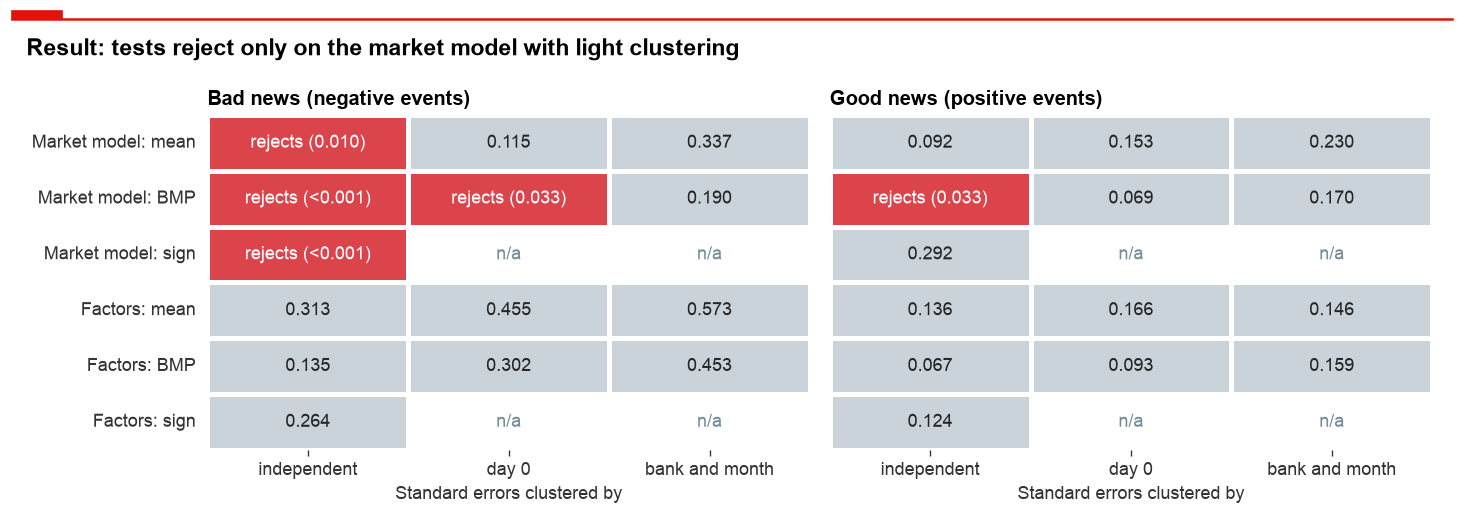

Mean of negative events, clustered by bank alone: 0.014
Negative minus positive, by day 0: 0.679, by bank and month: 0.679


In [80]:
GRID_COLUMNS = ["independent", "day 0", "bank and month"]


def cluster_p_values(table, values, is_first=None):
    '''Compute the p value of a mean, or of a gap between groups, under each clustering.'''
    design = np.ones(len(table))
    if is_first is not None:
        design = sm.add_constant(is_first.astype(float).values)
    day = pd.factorize(table["day_0"])[0]
    bank = pd.factorize(table["bank"])[0]
    month = pd.factorize(table["day_0"].dt.to_period("M"))[0]
    clusterings = {"day 0": day, "bank": bank, "bank and month": np.column_stack([bank, month])}

    model = sm.OLS(np.asarray(values, dtype=float), design)
    return {"independent": model.fit(use_t=False).pvalues[-1],
            **{name: model.fit(cov_type="cluster", cov_kwds={"groups": groups}).pvalues[-1]
               for name, groups in clusterings.items()}}


def p_value_rows(table, model, column, name):
    '''Collect the p values of the mean, BMP and sign tests of one model.'''
    standardised = standardised_cars(table, column, f"sigma_{model}")
    sign_p = main_tests(table, column, model)["p value, sign"]
    return {f"{name}: mean": cluster_p_values(table, table[column]),
            f"{name}: BMP": cluster_p_values(table, standardised),
            f"{name}: sign": {"independent": sign_p}}


def p_label(p):
    '''Write a p value, and say so where the test rejects at 5%.'''
    shown = "<0.001" if p < 0.001 else f"{p:.3f}"
    return f"rejects ({shown})" if p < ALPHA else shown


def plot_p_grid(ax, table, title):
    '''Show the p values of all tests and setups, rejections at 5% in red.'''
    grid = pd.DataFrame({**p_value_rows(table, "market", MAIN_CAR, "Market model"),
                         **p_value_rows(table, "factors", FACTOR_CAR, "Factors")}).T[GRID_COLUMNS]
    rejects = (grid < ALPHA).astype(float).where(grid.notna())
    sns.heatmap(rejects, annot=grid.map(p_label), fmt="", cmap=[LIGHT_GREY, LIGHT_RED], vmin=0, vmax=1,
                linewidths=2, cbar=False, ax=ax)
    for row, column in zip(*np.where(grid.isna())):
        ax.text(column + 0.5, row + 0.5, "n/a", ha="center", va="center", color=GREY)
    ax.tick_params(axis="y", rotation=0)
    ax.set_xlabel("Standard errors clustered by")
    ax.set_ylabel("")
    ax.grid(False)
    ax.set_title(title, fontsize=12)


fig, axes = plt.subplots(1, 2, figsize=(12, 4.12), sharey=True)
plot_p_grid(axes[0], negative_events, "Bad news (negative events)")
plot_p_grid(axes[1], positive_events, "Good news (positive events)")
axes[1].set_ylabel("")
show("Result: tests reject only on the market model with light clustering")

negative_mean = cluster_p_values(negative_events, negative_events[MAIN_CAR])
gap_p = cluster_p_values(signed_events, signed_events[MAIN_CAR], signed_events["sign"] == "negative")
print(f"Mean of negative events, clustered by bank alone: {negative_mean['bank']:.3f}")
print(f"Negative minus positive, by day 0: {gap_p['day 0']:.3f}, by bank and month: {gap_p['bank and month']:.3f}")

**Comments – 6.2**
* **Size:** the raw mean of −0.46% (−0.38% winsorised) is 35% of Krüger's −1.31%, but the median of −0.88% is 79% of his −1.11%, so the typical event falls nearly as much on the market model (his t −6.57, sign −5.20; positive events −0.47%, t −1.82, sign −1.66).
* **On the market model BMP is −3.64 and sign −3.98,** with 44.3% of CARs positive against a normal 48.6% (his share: 42.1%). Positive events have −2.14 and −1.05, so the clustered BMP and the sign test reject for negative events only, although far fewer positive events are tested.
* **With the factors nothing rejects:** BMP −1.49, sign −1.12, median −0.24%. Part of what the market model calls a reaction is exposure to other factors.
* **Why bank and month:** clustering by day 0 is the generous choice. Clustering by bank alone looks stronger (0.014 for the mean), but ignores that banks move together, so we do not rely on it.

### 6.3 Negative against positive events
Both groups fall a little, so a negative mean alone says little. Their difference removes what they share, which makes it the cleaner test if good news has no effect of its own. That is not certain: Krüger (2015) finds a weakly negative reaction to positive events, and 123 of our reports carry both signs (D1.6). We regress the CAR on a dummy, clustered by day 0, and every split below uses the same function.

In [81]:
def compare_groups(table, is_first, first, second, column=MAIN_CAR):
    '''Compare two groups: means, intervals, counts and the difference.'''
    # The coefficient on the dummy is the gap between the two group means
    fit = ols(table[column], is_first, clusters=table["day_0"])

    first_group = table[is_first]
    second_group = table[~is_first]
    first_mean, first_error = clustered_mean(first_group[column].values,
                                             first_group["day_0"])
    second_mean, second_error = clustered_mean(second_group[column].values,
                                               second_group["day_0"])
    return {
        "first": first, "second": second,
        "first mean": first_mean, "second mean": second_mean,
        "first half width": Z_95 * first_error,
        "second half width": Z_95 * second_error,
        "first events": len(first_group), "second events": len(second_group),
        "difference": fit.params[1], "error": fit.bse[1],
        "p value": fit.pvalues[1],
    }

In [82]:
is_negative = signed_events["sign"] == "negative"
sign_market = compare_groups(signed_events, is_negative, "Negative", "Positive")
sign_factors = compare_groups(signed_events, is_negative, "Negative",
                              "Positive", column=FACTOR_CAR)
drift = kept_days[AR_MARKET].mean() * WINDOW_LENGTH
gap_half_width = Z_95 * sign_market["error"]
print(f"Drift of all event days over 21 days: {drift:+.2%}")
print(f"Difference: {sign_market['difference']:+.2%} ± {gap_half_width:.2%}")

Drift of all event days over 21 days: -0.43%
Difference: +0.17% ± 0.82%


The BMP and sign tests have a difference test too: the standardised CARs and the share of positive CARs, regressed on the dummy.

In [83]:
compared = signed_events.assign(
    standardised=standardised_cars(signed_events, MAIN_CAR),
    is_positive_car=(signed_events[MAIN_CAR] > 0).astype(float),
)

for name, column in [("Standardised CAR", "standardised"), ("Share of positive CARs", "is_positive_car")]:
    result = compare_groups(compared, is_negative, "Negative", "Positive", column=column)
    print(f"{name}: difference {result['difference']:+.4f}, p = {result['p value']:.3f}")

Standardised CAR: difference +0.0368, p = 0.591
Share of positive CARs: difference -0.0143, p = 0.668


**Is the fall about events at all?** We compare with days that have no link to the reports: we move every event date to a random day of the same year, and compute the same CAR for the same banks. Events on one date move together, so the random means keep the clustering of the real ones.

In [84]:
cars_by_day = random_day_tables["market"][EVENT_END]

real_cars = [cars_by_day.at[row.day_0, row.bank] for row in car_table.itertuples()]
assert np.allclose(real_cars, car_table[BASE_CAR])  # on the real day 0 this gives our CARs

In [85]:
low, high = main_cars.min(), main_cars.max()  # the limits of the main test
draws = {"negative": random_means(negative_events, [cars_by_day.values], low, high)[:, 0],
         "positive": random_means(positive_events, [cars_by_day.values], low, high)[:, 0]}

rows = []
for sign, means in draws.items():
    real_mean = main_results.loc["mean", sign]
    rows.append({
        "real mean": real_mean,
        "random mean": means.mean(),
        "random sd": means.std(),
        "draws at or below the real mean": (means <= real_mean).mean(),
    })

random_table = pd.DataFrame(rows, index=draws)
random_table.style.format({
    "real mean": "{:+.2%}",
    "random mean": "{:+.2%}",
    "random sd": "{:.2%}",
    "draws at or below the real mean": "{:.1%}",
})

,real mean,random mean,random sd,draws at or below the real mean
negative,-0.38%,-0.34%,0.23%,44.6%
positive,-0.55%,-0.34%,0.40%,30.4%


**Comments – 6.3**
* **Random days fall about as much:** the same banks end at −0.34%, against −0.38% for negative events and −0.55% for positive ones, with 44.6% and 30.4% of the draws at or below the real means. A random day can lie close to a real event, as banks are hit so often, so this is no event free benchmark.
* **The gap shows nothing:** +0.17 points (p = 0.679), +0.31 with the factors (p = 0.365), and p values of 0.591 and 0.668 for BMP and sign. The median (−0.88% against −0.68%) and the share of positive CARs (44.3% against 45.7%) even point the other way.

### 6.4 Splits of the negative events
On the winsorised CARs. First the means of the five levels of the Sigwatch label: we test sign and intensity, not each level.

In [86]:
rows = []
for level, group in car_table.groupby("sentiment"):
    mean, error = clustered_mean(group[MAIN_CAR].values, group["day_0"])
    rows.append({"mean": mean, "half_width": Z_95 * error,
                 "events": len(group)})

level_means = pd.DataFrame(rows, index=sorted(car_table["sentiment"].unique()))

print(level_means["mean"].map("{:+.2%}".format).to_string())

-2    -0.66%
-1    -0.02%
 0    +0.39%
 1    -0.77%
 2    -0.01%


Now the splits. A headline event has prominence 4, and a high reach NGO an NGO power of 2 or more. A split by press coverage would need Task #1, which we did not build.

In [87]:
HIGH_REACH = 2  # NGO power of 2 or more counts as high reach

splits = {
    "COP21": compare_groups(negative_events, negative_events["day_0"] > COP21,
                            "After", "Up to"),
    "Trump election": compare_groups(negative_events,
                                     negative_events["day_0"] > TRUMP,
                                     "After", "Up to"),
    "Issue": compare_groups(negative_events,
                            negative_events["issue_group"] == CLIMATE_GROUP,
                            "Climate", "Other"),
    "Prominence": compare_groups(negative_events,
                                 negative_events["prominence"] == 4,
                                 "Headline", "Other"),
    "Intensity": compare_groups(negative_events,
                                negative_events["sentiment"] == -2,
                                "-2", "-1"),
    "NGO power": compare_groups(negative_events,
                                negative_events["ngo_power"] >= HIGH_REACH,
                                "High reach", "Low reach"),
}

Group comparisons: 7, false alarms expected at 5%: 0.35, found below 5%: 0


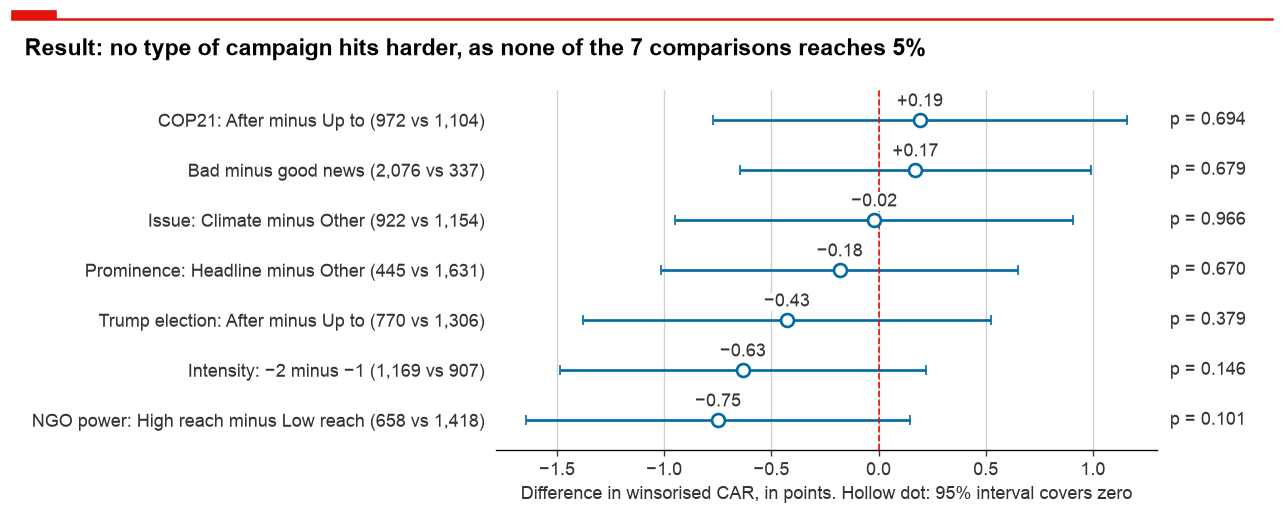

In [88]:
all_comparisons = {"Bad minus good news": sign_market}
for name, result in splits.items():
    all_comparisons[f"{name}: {result['first']} minus {result['second']}"] = result

comparisons = pd.DataFrame(all_comparisons).T.astype({"difference": float, "error": float, "p value": float})
comparisons = comparisons.sort_values("difference")
tests_run = len(comparisons)
print(f"Group comparisons: {tests_run}, false alarms expected at 5%: {tests_run * ALPHA:.2f}, "
      f"found below 5%: {(comparisons['p value'] < ALPHA).sum()}")

positions = np.arange(tests_run)
fig, ax = plt.subplots(figsize=(10.5, 4.12))
interval_dots(ax, comparisons["difference"], positions, Z_95 * comparisons["error"], BLUE)
for position, (difference, p) in zip(positions, zip(comparisons["difference"], comparisons["p value"])):
    annotate(ax, f"{difference * 100:+.2f}", (difference, position), offset=(0, 11), bbox=WHITE_BOX)
    ax.text(1.02, position, f"p = {p:.3f}", transform=ax.get_yaxis_transform(), va="center", color=DARK)
ax.axvline(0, color=ECONOMIST_RED, ls="--", lw=1)
ax.set_yticks(positions, [minus(f"{name} ({row['first events']:,} vs {row['second events']:,})")
                          for name, row in comparisons.iterrows()])
ax.set_ylim(-0.6, tests_run - 0.4)
ax.xaxis.set_major_formatter(POINTS)
ax.set_xlabel("Difference in winsorised CAR, in points. Hollow dot: 95% interval covers zero")
vertical_grid(ax)
show(f"Result: no type of campaign hits harder, as none of the {tests_run} comparisons reaches 5%")

**Comments – 6.4**
* **The largest are NGO power and intensity,** both in the expected direction, but we cannot tell them from noise. At 5% the 7 comparisons would give 0.35 false alarms, and we find none.
* **The five levels show no order:** −2 is at −0.66%, but +1 at −0.77%, below −1 at −0.02%.
* **COP21 is no clean experiment:** the placebo in 6.5 shows how far a date alone can move this, and Sigwatch's labels seem to change in 2016 (D1.5). Wide intervals mean we cannot tell, not that the effect is zero.

### 6.5 Robustness
For each check: the mean of the negative events, and the difference between negative and positive events, which removes the common drift. We show the setups that could change the answer: benchmark, the reaction window and sample. Five more only repeat them, so one line reports them: the windows $[-5, +5]$ and $[-10, -1]$, estimation windows of 120 and 500 days, and the 5 day rule of the do file.

In [89]:
def checked_row(name, table, column):
    '''Compute the mean of the negative events and the sign difference.'''
    result = compare_groups(table, table["sign"] == "negative", "Negative",
                            "Positive", column=column)
    return {
        "check": name,
        "events": result["first events"],
        "mean": result["first mean"],
        "half width": result["first half width"],
        "difference": result["difference"],
        "difference half width": Z_95 * result["error"],
        "p value": result["p value"],
    }

**A sector benchmark.** The market model compares a bank with all firms, so a weak period for banks counts as abnormal. Here we compare each bank with the equal weighted average of the other banks of its region, with no alpha or beta. Many of those banks are targeted too, so this also removes any reaction they share.

In [90]:
def sector_abnormal_returns(usd_returns, bank_region):
    '''Compute each bank's return minus the average of the other banks of its region.'''
    tables = []
    for region in REGION_ORDER:
        banks = usd_returns[bank_region.index[bank_region == region]]
        total, count = banks.sum(axis=1), banks.notna().sum(axis=1)
        # The bank itself leaves the average
        others = banks.rsub(total, axis=0).div(count - 1, axis=0)
        tables.append(banks - others)
    return pd.concat(tables, axis=1)


sector_returns = sector_abnormal_returns(usd_returns, bank_region).stack()
day_keys = pd.MultiIndex.from_frame(kept_days[["date", "bank"]])
kept_days["ar_sector"] = sector_returns.reindex(day_keys).values

car_table["sector [-10, +10]"] = event_cars(kept_days, "ar_sector")["[-10, +10]"]
SECTOR_CAR = "w sector [-10, +10]"
car_table[SECTOR_CAR] = winsorise(car_table, "sector [-10, +10]")
signed_events = signed_events.assign(**{SECTOR_CAR: car_table[SECTOR_CAR]})

sector_split = compare_groups(signed_events, signed_events["sign"] == "negative",
                              "Negative", "Positive", column=SECTOR_CAR)

In [91]:
# 2010 is coded differently, and the early years hold the euro crisis
from_2013 = signed_events["year"] >= 2013
us_banks_only = signed_events["region"] == "US"

checks = [
    ("Main test", signed_events, MAIN_CAR),
    ("Raw CARs, not winsorised", signed_events, BASE_CAR),
    ("Five factors + momentum", signed_events, FACTOR_CAR),
    ("Sector benchmark", signed_events, SECTOR_CAR),
    ("Window [0, +10]", signed_events, "w market [0, +10]"),
    ("US banks only", signed_events[us_banks_only], MAIN_CAR),
    ("Without 2010 to 2012", signed_events[from_2013], MAIN_CAR),
    ("Without the Brexit vote in the window",
     signed_events[~signed_events["brexit_in_window"]], MAIN_CAR),
    ("Without overlapping windows", signed_events[~signed_events["overlap"]],
     MAIN_CAR),
]

robustness = pd.DataFrame([checked_row(*check) for check in checks])
robustness = robustness.set_index("check")

means_without_zero = robustness["mean"].abs() > robustness["half width"]
print(f"Means without zero: {means_without_zero.sum()} of {len(robustness)}")
print(f"Lowest p value of the differences: {robustness['p value'].min():.3f}")

# Five more setups, reported in one line: they repeat what the rows above show
other_checks = [
    ("[-5, +5]", signed_events, "w market [-5, +5]"),
    ("[-10, -1]", signed_events, "w market [-10, -1]"),
    ("120 days", signed_events, "w market 120 days"),
    # Late listed banks have no 500 day window, so they drop out here
    ("500 days", signed_events.dropna(subset="w market 500 days"), "w market 500 days"),
    ("5 day rule", signed_events[~signed_events["conflict_5_days"]], MAIN_CAR),
]
other_results = pd.DataFrame([checked_row(*check) for check in other_checks]).set_index("check")
print("Other setups, p value of the gap:", other_results["p value"].round(3).to_dict())
print("Their means exclude zero:", (other_results["mean"].abs() > other_results["half width"]).sum())

Means without zero: 3 of 9
Lowest p value of the differences: 0.247


Other setups, p value of the gap: {'[-5, +5]': 0.259, '[-10, -1]': 0.424, '120 days': 0.868, '500 days': 0.374, '5 day rule': 0.813}
Their means exclude zero: 0


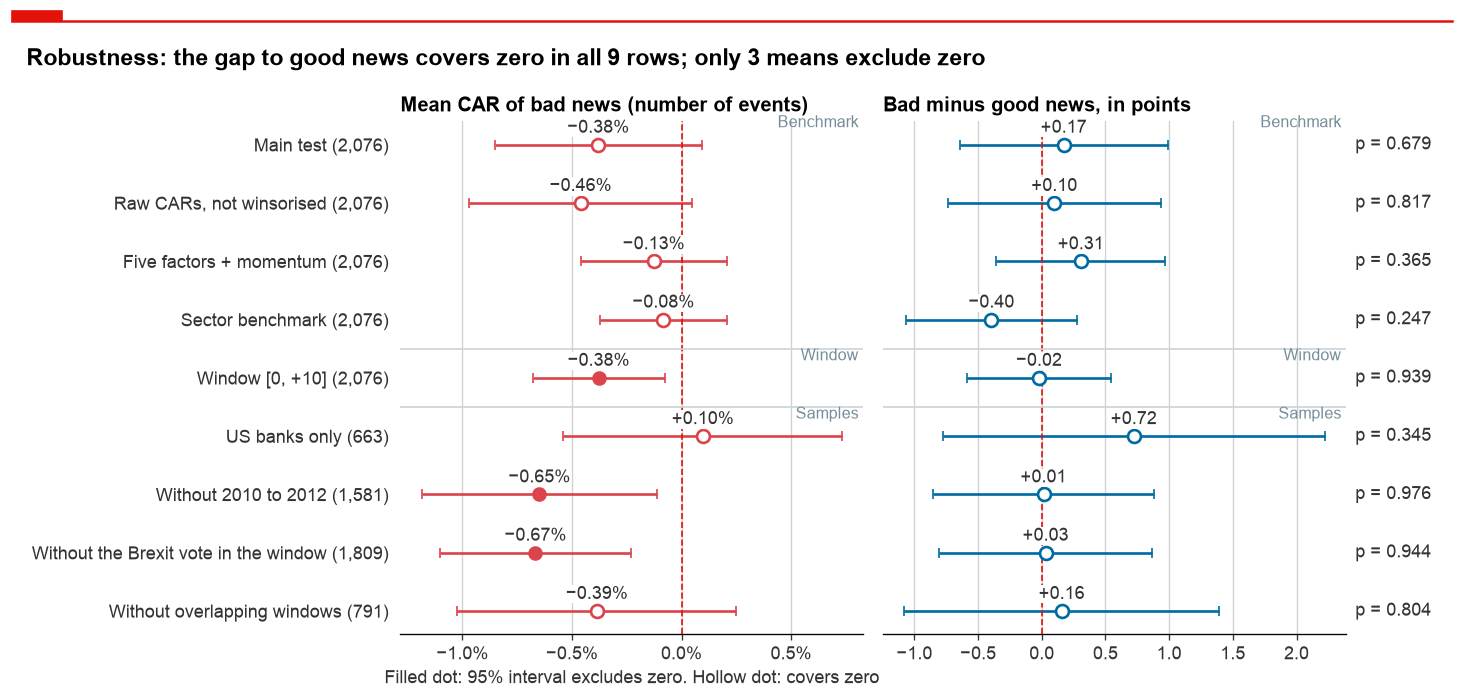

In [92]:
# Name, first and last row of each group of checks
CHECK_GROUPS = [("Benchmark", 0, 3), ("Window", 4, 4), ("Samples", 5, 8)]


def plot_checks(ax, table, value, width, color, title, in_points=False):
    '''Draw one labelled dot per check with its 95% interval and a zero line.'''
    positions = np.arange(len(table))[::-1]  # first check on top
    interval_dots(ax, table[value], positions, table[width], color)
    for position, number in zip(positions, table[value]):
        label = f"{number * 100:+.2f}" if in_points else f"{number:+.2%}"
        annotate(ax, label, (number, position), offset=(0, 10), bbox=WHITE_BOX)
    ax.axvline(0, color=ECONOMIST_RED, ls="--", lw=1)
    ax.set_yticks(positions, [minus(f"{check} ({events:,})") for check, events in table["events"].items()])
    ax.xaxis.set_major_locator(plt.MultipleLocator(0.005))
    ax.xaxis.set_major_formatter(POINTS if in_points else PercentFormatter(1, decimals=1))
    vertical_grid(ax)
    ax.set_title(title, fontsize=12)
    for name, first, last in CHECK_GROUPS:
        if last < len(table) - 1:
            ax.axhline(positions[last] - 0.5, color=LIGHT_GREY, lw=1)
        ax.text(0.99, positions[first] + 0.3, name, transform=ax.get_yaxis_transform(), ha="right",
                color=GREY, fontsize=9.5)


fig, axes = plt.subplots(1, 2, figsize=(12, 5.6), sharey=True)
plot_checks(axes[0], robustness, "mean", "half width",
            SENTIMENT_COLORS["negative"], "Mean CAR of bad news (number of events)")
plot_checks(axes[1], robustness, "difference", "difference half width",
            BLUE, "Bad minus good news, in points", in_points=True)
axes[0].set_xlabel("Filled dot: 95% interval excludes zero. Hollow dot: covers zero")
for position, p in zip(np.arange(len(robustness))[::-1], robustness["p value"]):
    axes[1].text(1.02, position, f"p = {p:.3f}", transform=axes[1].get_yaxis_transform(), va="center", color=DARK)
means_without_zero = (robustness["mean"].abs() > robustness["half width"]).sum()
show(f"Robustness: the gap to good news covers zero in all {len(robustness)} rows; only {means_without_zero} means exclude zero")

The COP21 split needs its own check. We move the date one year back, to 12 December 2014, and keep only events up to the real COP21. A difference at the false date would mean the split picks up something else.

In [93]:
PLACEBO_DATE = COP21 - pd.DateOffset(years=1)

# Only events up to the real COP21, which cannot then shape the placebo
before_cop21 = negative_events[negative_events["day_0"] <= COP21]
placebo = compare_groups(before_cop21, before_cop21["day_0"] > PLACEBO_DATE,
                         "After", "Up to")

real_split = splits["COP21"]
print(f"COP21, 12 Dec 2015: {real_split['difference']:+.2%}, "
      f"p = {real_split['p value']:.3f}")
print(f"Placebo, 12 Dec 2014: {placebo['difference']:+.2%}, "
      f"p = {placebo['p value']:.3f}")
print(f"Events after the false date: {placebo['first events']}")

COP21, 12 Dec 2015: +0.19%, p = 0.694
Placebo, 12 Dec 2014: -1.08%, p = 0.051
Events after the false date: 185


**Comments – 6.5**
* **The five setups not charted change nothing:** the gap covers zero in each, with p values from 0.259 to 0.868, and their means cover zero too.
* **The three means that exclude zero** are the window $[0, +10]$ and the samples without 2010 to 2012, the euro crisis years, and without the Brexit vote. The gap stays near zero in all three.
* **The sector benchmark removes the fall** (−0.08%), so the common drift looks like banks doing worse than the market. It can understate the effect when one report names several banks.
* **The placebo is a warning:** at the false date the gap is −1.08 points (p = 0.051, on 185 events), larger than at COP21 itself (+0.19, p = 0.694). Date splits can move this much by chance or with other news.
* **Other news stays a limit:** we have no news filter (no Factiva), so a campaign can coincide with earnings or a crisis. The median, the sign test and the rerun without 2010 to 2012 reduce this, but do not remove it.

### 6.6 Diff-in-diff against never-targeted banks
62 of our 126 banks never appear in our events, so they give a control group that the tests above do not use. For each event we take the targeted bank's return minus the average return of the never-targeted banks of its region, and compare the gap after the event (days 0 to +10) with the gap before it (days −10 to −1, scaled to 11 days). Each event has its own before and after, so events at different dates do not mix. We chose this test after seeing all results above, so it is exploratory.

In [94]:
never_targeted = usd_returns.columns.difference(event_banks)
controls = pd.DataFrame({region: usd_returns[never_targeted.intersection(bank_region.index[bank_region == region])].mean(axis=1)
                         for region in REGION_ORDER})
print("Never-targeted banks:", bank_region[never_targeted].value_counts().to_dict())

day_keys = pd.MultiIndex.from_arrays([kept_days["date"], kept_days["bank"].map(bank_region)])
kept_days["control_gap"] = kept_days["usd_return"] - controls.stack().reindex(day_keys).values

gap_sums = {"did before": kept_days[kept_days["day"] < 0], "did after": kept_days[kept_days["day"] >= 0]}
for name, days in gap_sums.items():
    car_table[name] = days.groupby("event_id")["control_gap"].sum()
car_table["did"] = car_table["did after"] - 11 / 10 * car_table["did before"]
for column in ["did before", "did after", "did"]:
    car_table[f"w {column}"] = winsorise(car_table, column)

did_columns = ["w did before", "w did after", "w did"]
signed_events = signed_events.assign(**car_table[did_columns])
did_split = compare_groups(signed_events, signed_events["sign"] == "negative", "Negative", "Positive", column="w did")


def did_rows(name, table):
    '''Report the diff-in-diff of negative and positive events in one sample.'''
    is_neg = table["sign"] == "negative"
    rows = []
    for sign, group in [("negative", table[is_neg]), ("positive", table[~is_neg])]:
        before_p = cluster_p_values(group, group["w did before"])
        did_p = cluster_p_values(group, group["w did"])
        rows.append({"sample": name, "sign": sign, "events": len(group),
                     "before": group["w did before"].mean(), "p, before": before_p["bank and month"],
                     "after": group["w did after"].mean(), "diff-in-diff": group["w did"].mean(),
                     "p, day 0": did_p["day 0"], "p, bank and month": did_p["bank and month"]})
    return rows


did_table = pd.DataFrame([*did_rows("All events", signed_events),
                          *did_rows("No overlapping windows", signed_events[~signed_events["overlap"]]),
                          # The UK and Sweden have only 3 and 1 never-targeted banks
                          *did_rows("US and euro area only", signed_events[signed_events["region"].isin(["US", "Euro area"])])])
did_table = did_table.set_index(["sample", "sign"])
did_gap = cluster_p_values(signed_events, signed_events["w did"], signed_events["sign"] == "negative")
print(f"Negative minus positive: {did_split['difference']:+.2%} ± {Z_95 * did_split['error']:.2%}, "
      f"p = {did_gap['day 0']:.3f} by day 0, {did_gap['bank and month']:.3f} by bank and month")
percent_columns = ["before", "after", "diff-in-diff"]
did_table.style.format("{:.3f}").format("{:+.2%}", subset=percent_columns).format("{:,}", subset=["events"])

Never-targeted banks: {'Euro area': 34, 'US': 24, 'UK': 3, 'Sweden': 1}


Negative minus positive: -0.21% ± 0.91%, p = 0.643 by day 0, 0.661 by bank and month


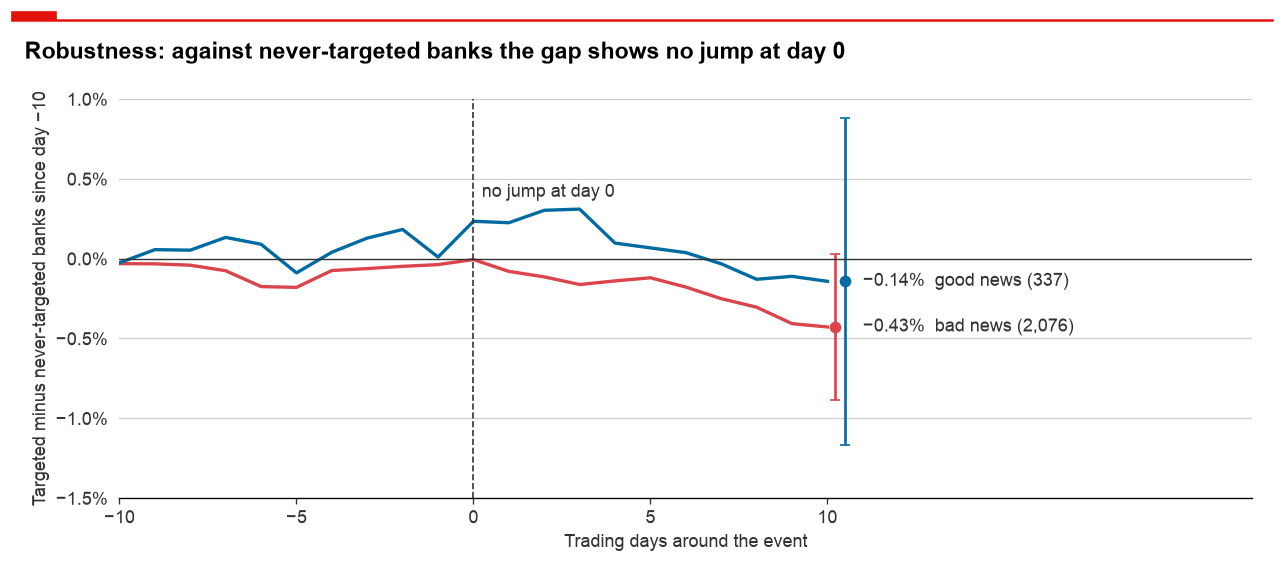

In [95]:
fig, ax = plt.subplots(figsize=(10.5, 4.5))
ends = {}
for sign, shift in [("negative", 0.2), ("positive", 0.5)]:
    gap_path = car_path(kept_days, "control_gap", car_table, sign)
    plot_car_path(ax, gap_path, SENTIMENT_COLORS[sign], shift)
    ends[f"{NEWS_NAMES[sign]} ({counts[sign]:,})"] = gap_path["mean"].iloc[-1]
label_path_ends(ax, ends)
format_car_axis(ax, "")
ax.set_yticks(np.arange(-0.015, 0.0101, 0.005))
ax.set_ylim(-0.015, 0.01)
ax.set_ylabel("Targeted minus never-targeted banks since day −10")
show("Robustness: against never-targeted banks the gap shows no jump at day 0")

In [96]:
control_betas = {}
for region in REGION_ORDER:
    days = trading_days[region]
    region_factors = factors_north_america if region == "US" else factors_europe
    fit = RollingOLS(controls.loc[days, region], sm.add_constant(region_factors.loc[days, ["market"]]),
                     window=BASE_WINDOW, min_nobs=int(BASE_WINDOW * MIN_VALID_SHARE), missing="drop").fit()
    control_betas[region] = fit.params["market"].shift(GAP_DAYS)  # known before the event window

target_beta = market_estimates["market"].reindex(car_table.index)
control_beta = pd.Series([control_betas[region].get(day, np.nan) for region, day in zip(car_table["region"], car_table["day_0"])],
                         index=car_table.index)
print(f"Average market beta: targeted banks {target_beta.mean():.2f}, never-targeted banks {control_beta.mean():.2f}")

Average market beta: targeted banks 1.41, never-targeted banks 1.03


**Comments – 6.6**
* **The fall stays small and not significant:** −0.37% for negative events (p = 0.150 by day 0, 0.235 by bank and month) and −0.16% for positive ones, a gap of −0.21 ± 0.91 points (p = 0.643). Pre-event gaps of +0.02% support the comparison (p = 0.931 and 0.945), though they are larger without overlapping windows (−0.20% and −0.37%, p = 0.465 and 0.308).
* **The estimate is fragile:** 0.00% on the 791 negative events without an overlap (p = 0.996), and −0.15% on US and euro area banks (p = 0.590). So the UK and Sweden, with only 3 and 1 never-targeted banks, carry most of it.
* **Why this design, and what it assumes:** it compares targeted banks with real untargeted banks of the same region over the same days, needs no model or betas, and gives each event its own before and after. It rests on parallel trends, comparable controls, random timing, no spillovers and one clean treatment per window. Small pre-event gaps support the first, but the others may not hold here: targeted banks have higher betas (1.41 against 1.03) and are probably larger, the UK and Sweden have only 3 and 1 controls, NGOs may target banks already in the news, a campaign can affect untargeted banks too, and 61% of windows overlap. So we claim no causal effect, and as we chose this test last, we read it as exploratory.

### 6.7 How much could the test see?
We set the test of negative against positive events against Krüger's gap, whose standard error follows from his means and t statistics.

Krüger's gap: -0.84% ± 0.64%
Our gap: +0.17% ± 0.82%
Distance between the gaps: +1.01%, p = 0.056
Power against Krüger's gap: 52%
Gap needed for 80% power: 1.17%


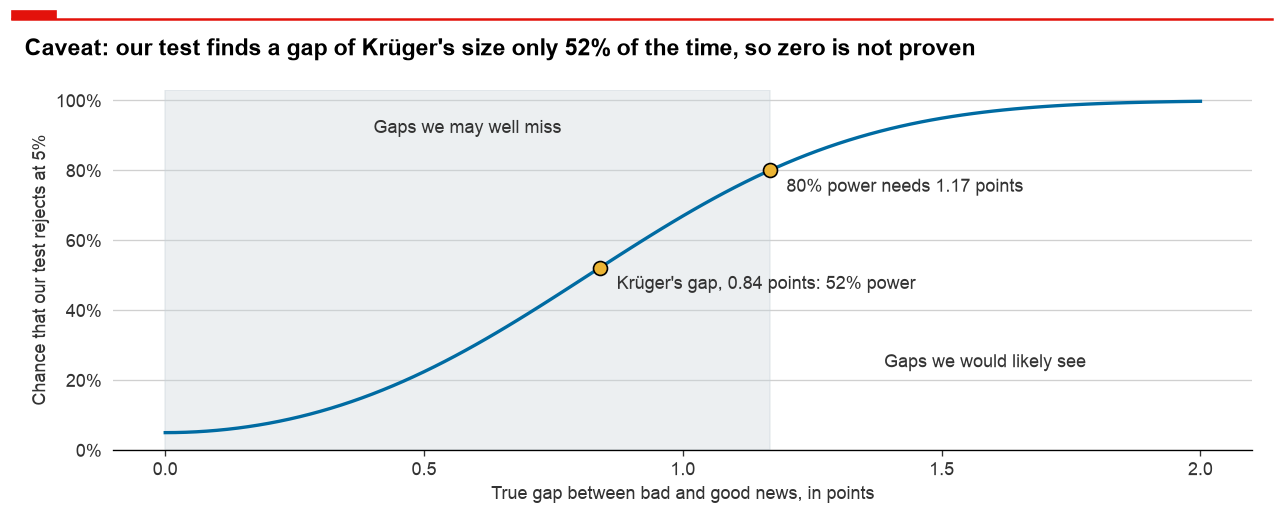

In [97]:
POWER_TARGET = 0.8  # the usual standard for a well powered test

kruger_gap = KRUGER_NEGATIVE - KRUGER_POSITIVE
# Separate groups of events, so their variances add up
kruger_error = np.sqrt((KRUGER_NEGATIVE / KRUGER_NEGATIVE_T) ** 2
                       + (KRUGER_POSITIVE / KRUGER_POSITIVE_T) ** 2)
our_gap, our_error = sign_market["difference"], sign_market["error"]

gap_distance = our_gap - kruger_gap
distance_error = np.sqrt(our_error ** 2 + kruger_error ** 2)
gap_p_value = p_value(gap_distance / distance_error)

# Power of a two sided test at 5% against a gap of Krüger's size
shift_in_errors = abs(kruger_gap) / our_error
power = (stats.norm.sf(Z_95 - shift_in_errors)
         + stats.norm.cdf(-Z_95 - shift_in_errors))
smallest_gap = (Z_95 + stats.norm.ppf(POWER_TARGET)) * our_error

print(f"Krüger's gap: {kruger_gap:+.2%} ± {Z_95 * kruger_error:.2%}")
print(f"Our gap: {our_gap:+.2%} ± {Z_95 * our_error:.2%}")
print(f"Distance between the gaps: {gap_distance:+.2%}, p = {gap_p_value:.3f}")
print(f"Power against Krüger's gap: {power:.0%}")
print(f"Gap needed for {POWER_TARGET:.0%} power: {smallest_gap:.2%}")

true_gaps = np.linspace(0, 0.02, 101)
power_curve = stats.norm.sf(Z_95 - true_gaps / our_error) + stats.norm.cdf(-Z_95 - true_gaps / our_error)

fig, ax = plt.subplots(figsize=(10.5, 4.12))
ax.axvspan(0, smallest_gap, color=LIGHT_GREY, alpha=0.35)
ax.plot(true_gaps, power_curve, color=BLUE, lw=2)
annotate(ax, "Gaps we may well miss", (smallest_gap / 2, 0.92), offset=(0, 0))
annotate(ax, "Gaps we would likely see", ((smallest_gap + true_gaps[-1]) / 2, 0.25), offset=(0, 0))
for gap, share, label in [(abs(kruger_gap), power, f"Krüger's gap, {abs(kruger_gap) * 100:.2f} points: {power:.0%} power"),
                          (smallest_gap, POWER_TARGET, f"{POWER_TARGET:.0%} power needs {smallest_gap * 100:.2f} points")]:
    ax.scatter(gap, share, color=YELLOW, edgecolors="black", s=70, zorder=3)
    annotate(ax, label, (gap, share), offset=(10, -10))
ax.xaxis.set_major_locator(plt.MultipleLocator(0.005))
ax.xaxis.set_major_formatter(POINTS)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_ylim(0, 1.03)
ax.set_xlabel("True gap between bad and good news, in points")
ax.set_ylabel("Chance that our test rejects at 5%")
show(f"Caveat: our test finds a gap of Krüger's size only {power:.0%} of the time, so zero is not proven")

**Comments – 6.7**
* **This is no proof of a zero effect:** Krüger's gap of −0.84 points has a 95% interval of ± 0.64, which overlaps our +0.17 ± 0.82, and the two gaps differ with p = 0.056. He also studies other firms, years and news.

## Conclusion

Mean: campaign windows -0.38%, any window -0.35%
Share of windows with a fall: campaign 55.7%, any 54.5%
Standard deviation of campaign CARs: 6.69%


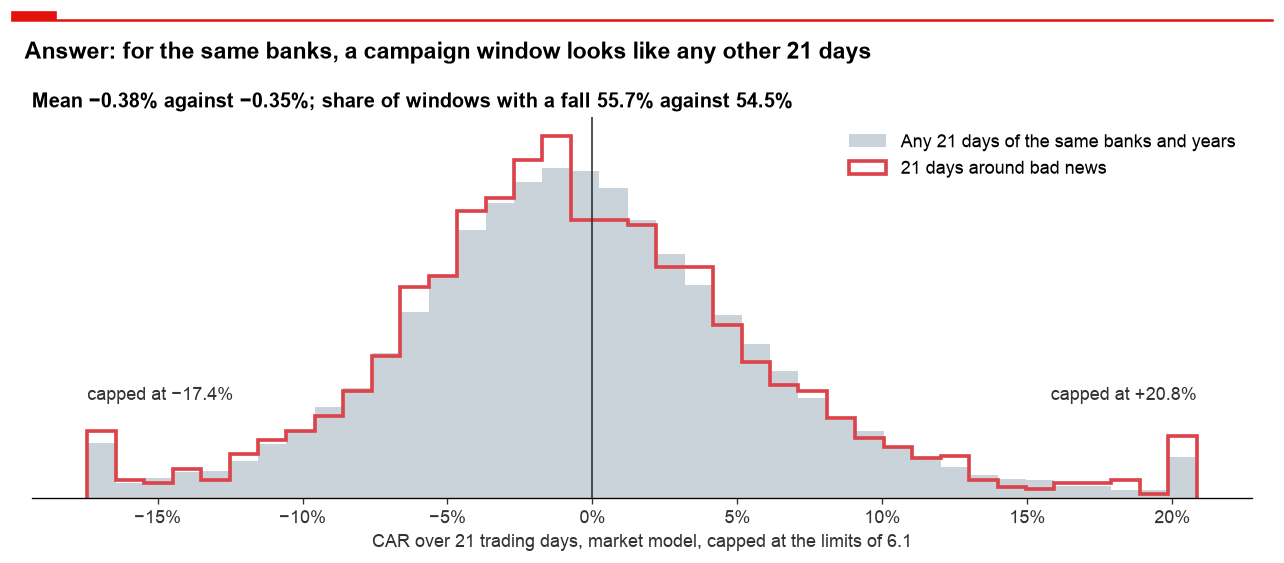

In [98]:
def random_day_cars(table, low, high):
    '''Collect the capped CARs of all days of each event's bank and year, weighted per event.'''
    values, weights = [], []
    pairs = table.groupby(["bank", table["day_0"].dt.year]).size()
    for (bank, year), n_events in pairs.items():
        cars = cars_by_day.loc[str(year), bank].dropna().clip(low, high)
        values.append(cars.values)
        weights.append(np.full(len(cars), n_events / len(cars)))
    return np.concatenate(values), np.concatenate(weights)


other_cars, other_weights = random_day_cars(negative_events, low, high)
real_cars = negative_events[MAIN_CAR]
other_mean = np.average(other_cars, weights=other_weights)
falling_real = (real_cars < 0).mean()
falling_other = other_weights[other_cars < 0].sum() / other_weights.sum()
print(f"Mean: campaign windows {real_cars.mean():+.2%}, any window {other_mean:+.2%}")
print(f"Share of windows with a fall: campaign {falling_real:.1%}, any {falling_other:.1%}")
print(f"Standard deviation of campaign CARs: {real_cars.std():.2%}")

OVERLAP_BINS = np.linspace(low, high, 40)

fig, ax = plt.subplots(figsize=(10.5, 4.5))
ax.hist(other_cars, bins=OVERLAP_BINS, weights=other_weights, density=True, color=LIGHT_GREY,
        label="Any 21 days of the same banks and years")
ax.hist(real_cars, bins=OVERLAP_BINS, density=True, histtype="step", lw=2.2,
        color=SENTIMENT_COLORS["negative"], label="21 days around bad news")
ax.axvline(0, color=DARK, lw=1)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_yticks([])
ax.set_xlabel("CAR over 21 trading days, market model, capped at the limits of 6.1")
top = ax.get_ylim()[1]
annotate(ax, f"capped at {low:+.1%}", (low, 0.27 * top), offset=(0, 0), ha="left")
annotate(ax, f"capped at {high:+.1%}", (high, 0.27 * top), offset=(0, 0), ha="right")
ax.legend(loc="upper right")
ax.set_title(minus(f"Mean {real_cars.mean():+.2%} against {other_mean:+.2%}; share of windows with a fall "
                   f"{falling_real:.1%} against {falling_other:.1%}"), fontsize=12)
show("Answer: for the same banks, a campaign window looks like any other 21 days")

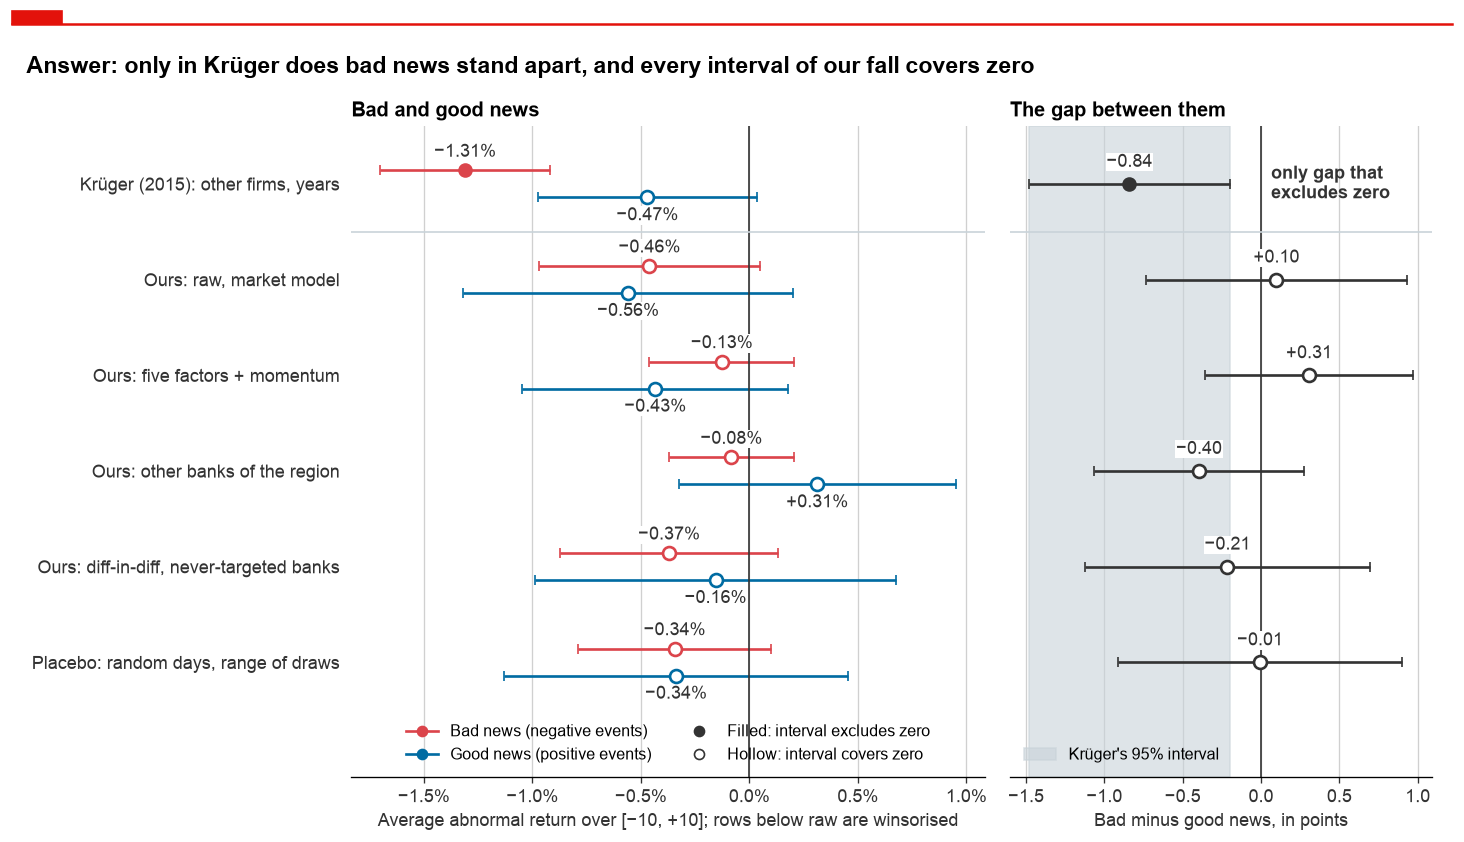

In [99]:
def group_stats(result):
    '''Return mean and half width of both groups of a compare_groups result.'''
    return (result["first mean"], result["first half width"],
            result["second mean"], result["second half width"])


def random_stats(sign):
    '''Return the mean of the random days of one sign and its 95% half width.'''
    return random_table.loc[sign, "random mean"], Z_95 * random_table.loc[sign, "random sd"]


def path_stats(sign):
    '''Return the raw mean CAR of one sign on day +10 and its half width.'''
    return tuple(paths["market", sign].loc[EVENT_END, ["mean", "half_width"]])


ladder = pd.DataFrame({
    "Krüger (2015): other firms, years": (KRUGER_NEGATIVE, Z_95 * abs(KRUGER_NEGATIVE / KRUGER_NEGATIVE_T),
                      KRUGER_POSITIVE, Z_95 * abs(KRUGER_POSITIVE / KRUGER_POSITIVE_T)),
    "Ours: raw, market model": (*path_stats("negative"), *path_stats("positive")),
    "Ours: five factors + momentum": group_stats(sign_factors),
    "Ours: other banks of the region": group_stats(sector_split),
    "Ours: diff-in-diff, never-targeted banks": (did_split["first mean"], did_split["first half width"],
                                                 did_split["second mean"], did_split["second half width"]),
    "Placebo: random days, range of draws": (*random_stats("negative"), *random_stats("positive")),
}, index=["negative", "negative width", "positive", "positive width"]).T
ladder["gap width"] = [Z_95 * kruger_error,
                       robustness.loc["Raw CARs, not winsorised", "difference half width"],
                       Z_95 * sign_factors["error"],
                       Z_95 * sector_split["error"],
                       Z_95 * did_split["error"],
                       Z_95 * np.hypot(*random_table["random sd"])]


def plot_ladder(left, right, ladder):
    '''Show the mean effect of bad and good news per benchmark, and the gap between them.'''
    rows = np.arange(len(ladder))[::-1]  # first row on top
    handles = []
    for sign, shift, label_shift in [("negative", 0.14, 11), ("positive", -0.14, -11)]:
        color = SENTIMENT_COLORS[sign]
        interval_dots(left, ladder[sign], rows + shift, ladder[f"{sign} width"], color)
        handles.append(plt.Line2D([], [], color=color, marker="o", label=f"{NEWS_NAMES[sign].capitalize()} ({sign} events)"))
        for row, value in zip(rows, ladder[sign]):
            annotate(left, f"{value:+.2%}", (value, row + shift), offset=(0, label_shift), bbox=WHITE_BOX)
    handles.append(plt.Line2D([], [], color=DARK, marker="o", ls="none", label="Filled: interval excludes zero"))
    handles.append(plt.Line2D([], [], color=DARK, marker="o", ls="none", markerfacecolor=left.get_facecolor(),
                              label="Hollow: interval covers zero"))

    gaps = ladder["negative"] - ladder["positive"]
    kruger_center, kruger_width = gaps.iloc[0], ladder["gap width"].iloc[0]
    right.axvspan(kruger_center - kruger_width, kruger_center + kruger_width, color=LIGHT_GREY, alpha=0.6,
                  label="Krüger's 95% interval")
    interval_dots(right, gaps, rows, ladder["gap width"], DARK)
    for row, gap in zip(rows, gaps):
        annotate(right, f"{gap * 100:+.2f}", (gap, row), offset=(0, 13), bbox=WHITE_BOX)
    annotate(right, "only gap that\nexcludes zero", (0, rows[0]), offset=(6, 0), ha="left", fontweight="bold")

    for ax in [left, right]:
        ax.axvline(0, color=DARK, lw=1)
        ax.axhline(rows[0] - 0.5, color=LIGHT_GREY, lw=1)  # the published result stands apart
        vertical_grid(ax)
    left.xaxis.set_major_formatter(PercentFormatter(1, decimals=1))
    right.xaxis.set_major_formatter(POINTS)
    right.xaxis.set_major_locator(plt.MultipleLocator(0.005))
    left.set_yticks(rows, ladder.index)
    left.set_ylim(-1.2, rows[0] + 0.6)  # room for the legends
    left.set_xlabel("Average abnormal return over [−10, +10]; rows below raw are winsorised")
    left.set_title("Bad and good news", fontsize=12)
    left.legend(handles=handles, loc="lower center", ncol=2, fontsize=9.5)
    right.set_xlabel("Bad minus good news, in points")
    right.set_title("The gap between them", fontsize=12)
    right.legend(loc="lower left", fontsize=9.5)


fig, axes = plt.subplots(1, 2, figsize=(12, 6.75), sharey=True, gridspec_kw={"width_ratios": [1.5, 1]})
plot_ladder(axes[0], axes[1], ladder)
show("Answer: only in Krüger does bad news stand apart, and every interval of our fall covers zero")

**Our answer: markets barely react to NGO campaigns against banks.**
* **A campaign window looks like any other** (first chart): it falls 55.7% of the time, any 21 days of the same banks and years 54.5%, and random days end at −0.34%. With a standard deviation of 6.69%, the noise is about 18 times the mean of −0.38%.
* **Only Krüger's gap excludes zero** (second chart): −0.84 points, against +0.10 raw and +0.17 winsorised for us (p = 0.679). On his tests and market model bad news does fall (BMP −3.64, sign −3.98): the mean of −0.46% is 35% of his −1.31%, while the median of −0.88% is 79% of his −1.11%. But with the factors the median is −0.24% and no test rejects, and none rejects clustered by bank and month. Good news falls too: none of the 7 comparisons reaches 5%, and none of the 8 robustness checks is significant (lowest p value 0.247).
* **The size of the fall depends on the benchmark:** −0.13% with the factors, −0.08% against other banks of the region, −0.37% against never-targeted banks (p = 0.235), but 0.00% there without overlapping windows and −0.15% on US and euro area banks. Clustered by bank and month the BMP test has p = 0.190.

**Caveats.**
* **This is no proof of a zero effect:** we have 52% power against Krüger's gap, and his interval of ± 0.64 overlaps our ± 0.82.
* **Overlaps may make our intervals too narrow:** 61.2% of events start within 21 trading days of the bank's previous event, so one return can enter two CARs, which clustering does not remove. On the 791 negative events without an overlap the mean stays at −0.39%, with a wider interval.

**Possible reasons.** Banks may be targeted so often that one report is no news: the median event has 12 others of the same bank in its estimation window. Sigwatch dates can also lag the real news, so a reaction may fall before our window.

**With more time.** A news filter (Factiva), to remove earnings and crises from the event windows, and Tasks #1 and #2, to see which campaigns reach the press and social media.

## References
* Boehmer, E., Musumeci, J. and Poulsen, A. (1991), Event-study methodology under conditions of event-induced variance, *Journal of Financial Economics* 30, 253–272.
* Cowan, A. (1992), Nonparametric event study tests, *Review of Quantitative Finance and Accounting* 2, 343–358.
* Fama, E. and French, K. (2015), A five-factor asset pricing model, *Journal of Financial Economics* 116, 1–22.
* Koenig, P. (2017), Notes on Sigwatch's NGO campaign database, preprint, halshs-01671758.
* Krüger, P. (2015), Corporate goodness and shareholder wealth, *Journal of Financial Economics* 115, 304–329.